# **Optimal Cybersecurity Investment and Cyber-Insurance in a Stochastic Gordon-Loeb Model under Clustered Attacks**

Full set of experiments reported in the thesis. All numerical logic lives in the
project modules (`processes.py`, `premiums.py`, `pide_common.py`,
`pide_risk_neutral.py`, `pide_risk_averse.py`, `bounds.py`, `plotting.py`);
this notebook only calls into them, inspects results, and produces figures.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import numpy as np
import matplotlib.pyplot as plt

from processes import Expectation_Lambda_t, Expectation_Nt, Var_Nt
from premiums import calculate_premium_lomax, calculate_premium_lognormal
from pide_risk_neutral import Hawkes_PIDE_solver, Poisson_PDE_solver, z_star, z_star_Poisson
from pide_risk_averse import PDE_rhs_Hawkes_RA, Hawkes_PIDE_solver_RA, solve_W_by_C_RA, MGF_Bounded_Losses_RA, solve_W_zbar_RA
from validation import evaluate_J_Poisson_optimal_policy_grid
import plotting as PL

In [2]:
np.random.seed(0)

In [3]:
THESIS_PLOTS_DIR = "thesis_plots"
if not os.path.exists(THESIS_PLOTS_DIR):
    os.makedirs(THESIS_PLOTS_DIR)

-----------------------------------------------------------------------------------------------------------------

# **Hawkes Process Simulation**

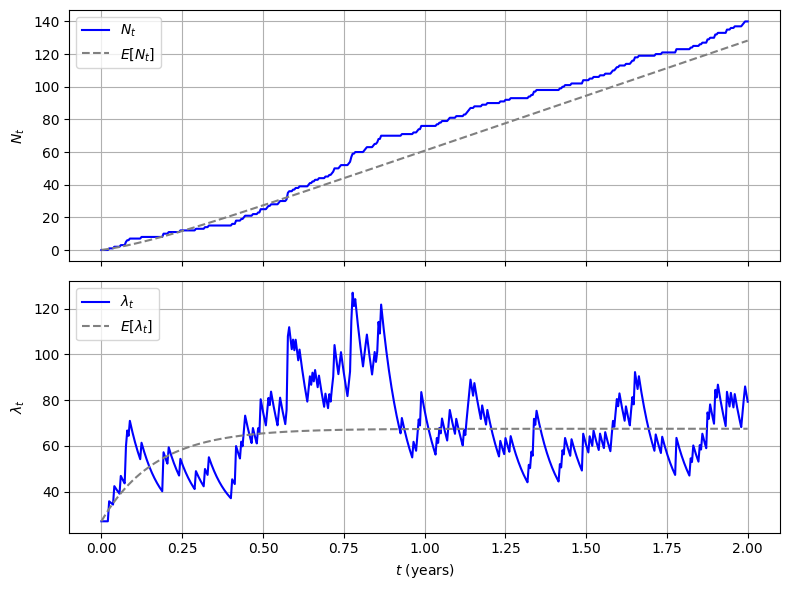

In [4]:
PL.Visual_Process("hawkes", T_final=2, alpha=27, lambda_0=27, xi=15, beta=9)

# **Security Breach Probability Functions**

## Gordon-Loeb Class 1

Saved: thesis_plots/GLI_Function.png


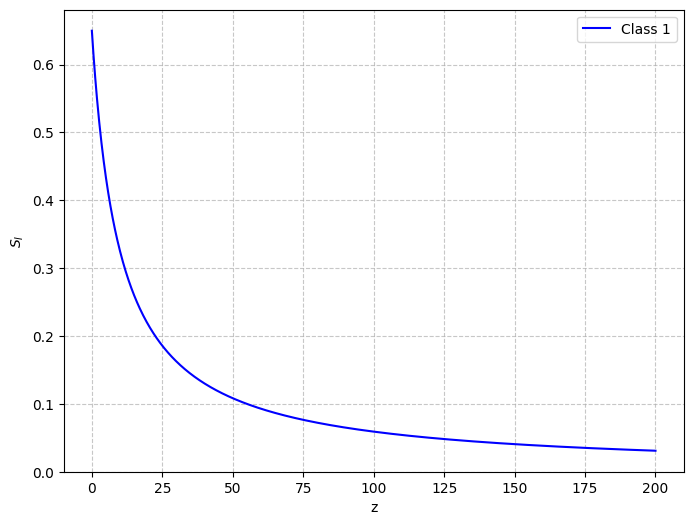

In [5]:
name = 'GLI_Function'

PL.SBPF(class_type = 1, v = 0.65, a = 0.1, b = 1, save_name = name)

## Gordon-Loeb Class 2

Saved: thesis_plots/GLI_Function.png


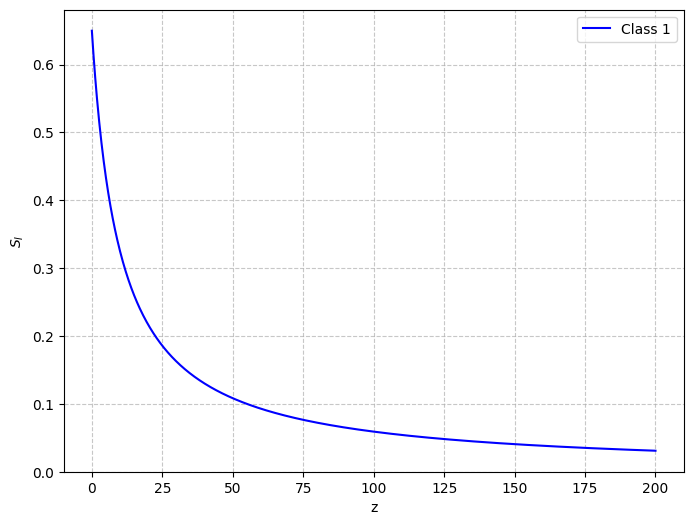

In [6]:
name = 'GLI_Function'

PL.SBPF(class_type = 1, v = 0.65, a = 0.1, b = 1, save_name = name)

# **Premium Analysis**

## Lomax SDP

Saved: thesis_plots/Premium_Lomax_SDP.png


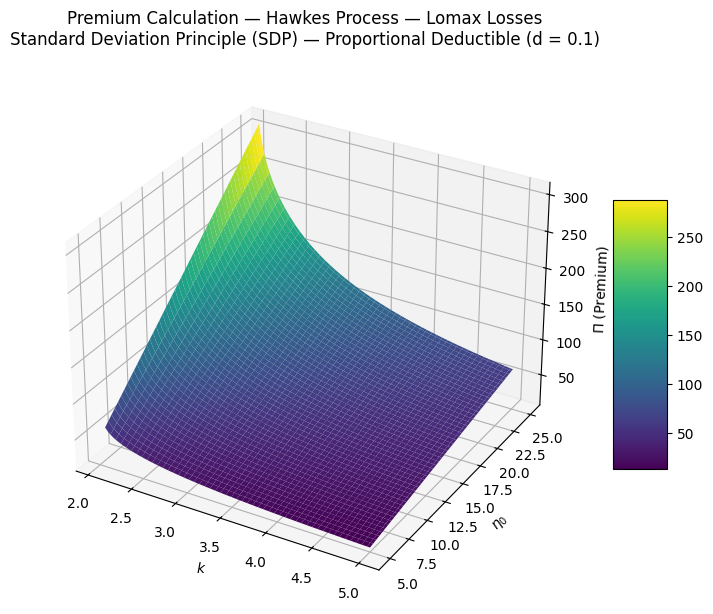

In [7]:
name = 'Premium_Lomax_SDP'

PL.Visual_premium_lomax(t = 1, C = 0.85, d = 0.1, H_0 = 25, Principle = 'SDP', process_type = 'Hawkes', save_name = name)

Saved: thesis_plots/elasticity_eta_0_SDP.png


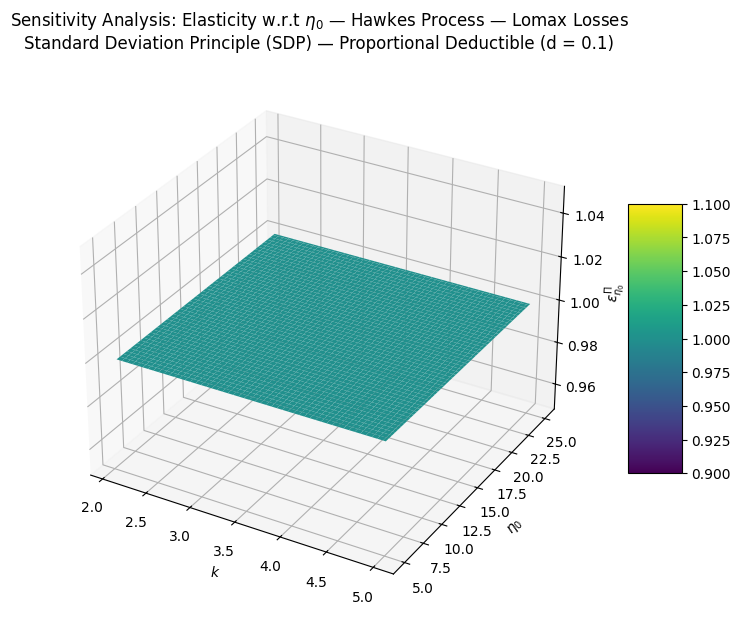

In [8]:
name = 'elasticity_eta_0_SDP'

PL.Visual_elasticity_premium_eta_0_lomax(t = 1, C = 0.85, d = 0.1, H_0 = 25, Principle = 'SDP', process_type = 'Hawkes', save_name = name)

Saved: thesis_plots/elasticity_k_SDP.png


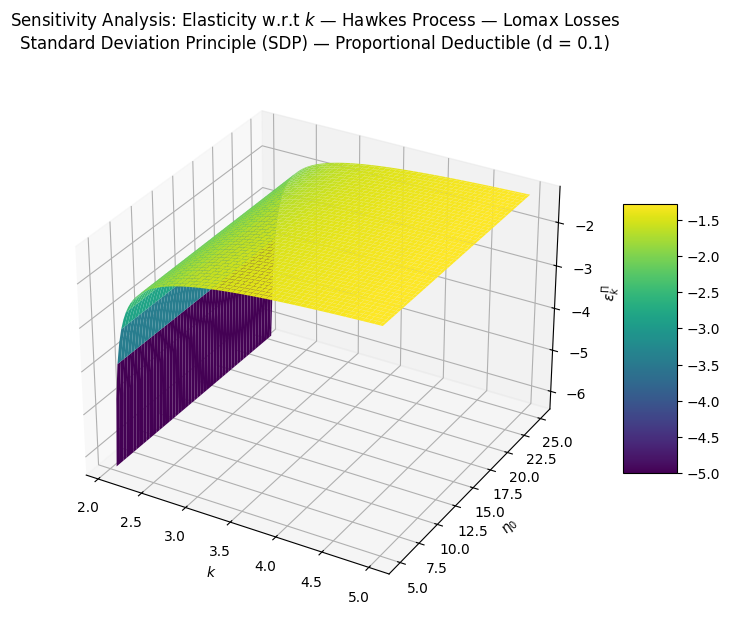

In [9]:
name = 'elasticity_k_SDP'

PL.Visual_elasticity_premium_k_lomax(t = 1, C = 0.85, d = 0.1, H_0 = 25, Principle = 'SDP', process_type = 'Hawkes', save_name = name)

Saved: thesis_plots/Lomax_Comparison_SDP_27.png


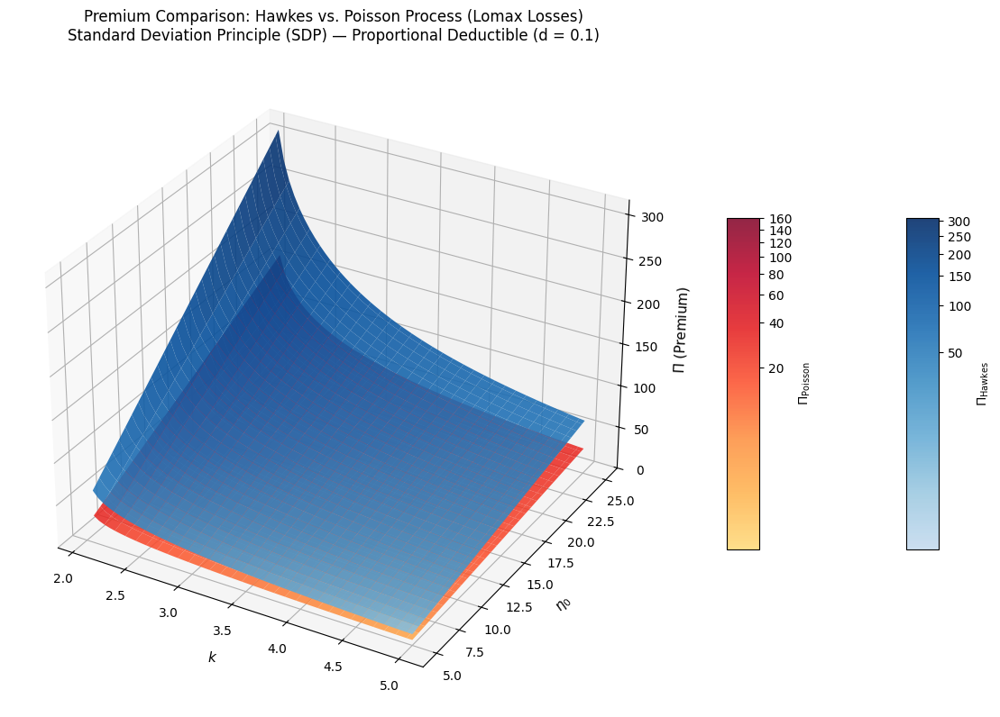

In [10]:
name = 'Lomax_Comparison_SDP_27'

PL.Premium_comparison(t = 1, C = 0.85, d = 0.1, H_0 = 25, lambda_poisson = 27, Principle = 'SDP', dist_type= 'lomax', save_name = name)

Saved: thesis_plots/Lomax_Comparison_SDP_61.png


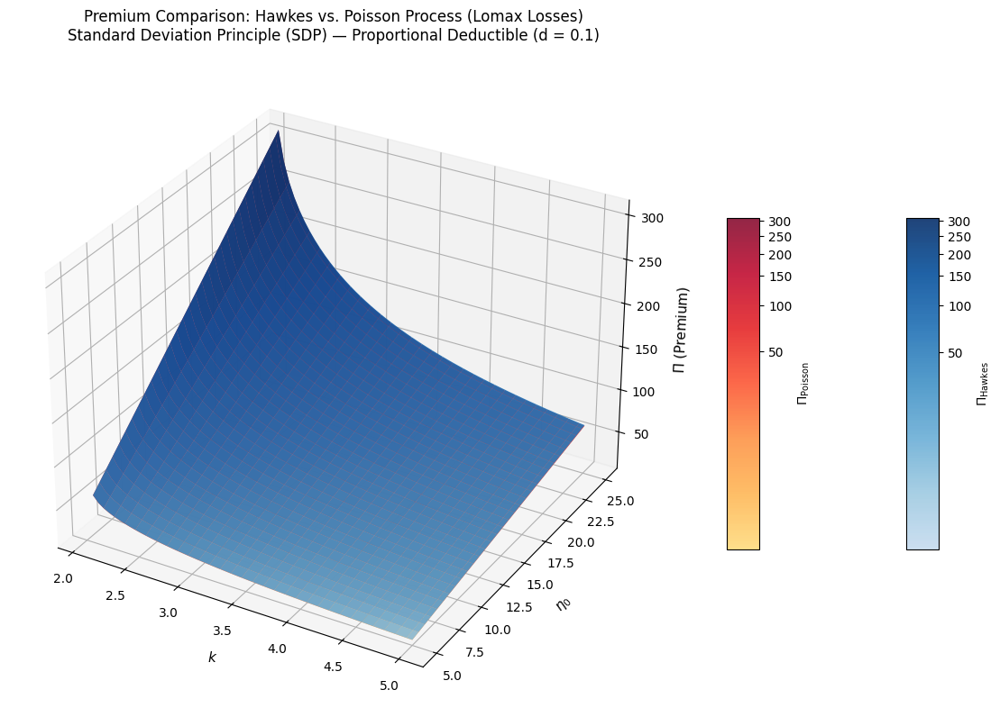

In [11]:
name = 'Lomax_Comparison_SDP_61'

PL.Premium_comparison(t = 1, C = 0.85, d = 0.1, H_0 = 25, lambda_poisson = 61, Principle = 'SDP', dist_type= 'lomax', save_name = name)

## Lomax VP

Saved: thesis_plots/Premium_Lomax_VP.png


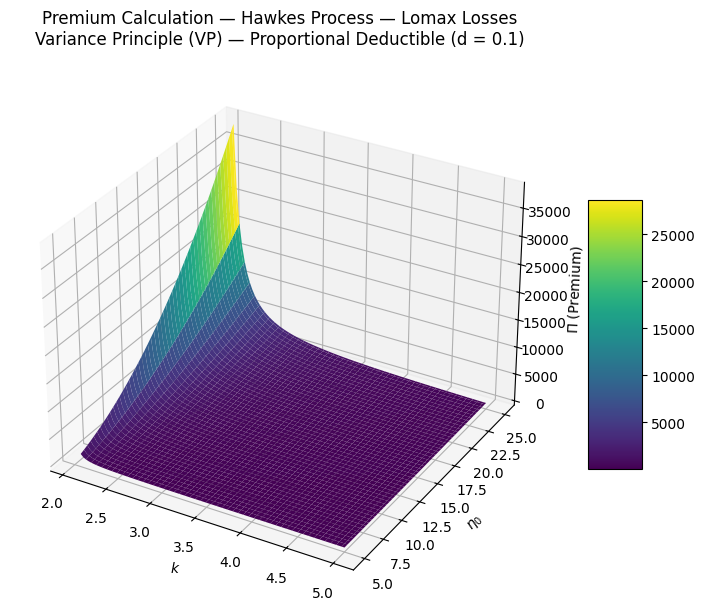

In [12]:
name = 'Premium_Lomax_VP'

PL.Visual_premium_lomax(t = 1, C = 0.85, d = 0.1, H_0 = 25, Principle = 'VP', process_type = 'Hawkes', save_name = name)

Saved: thesis_plots/elasticity_eta_0_VP.png


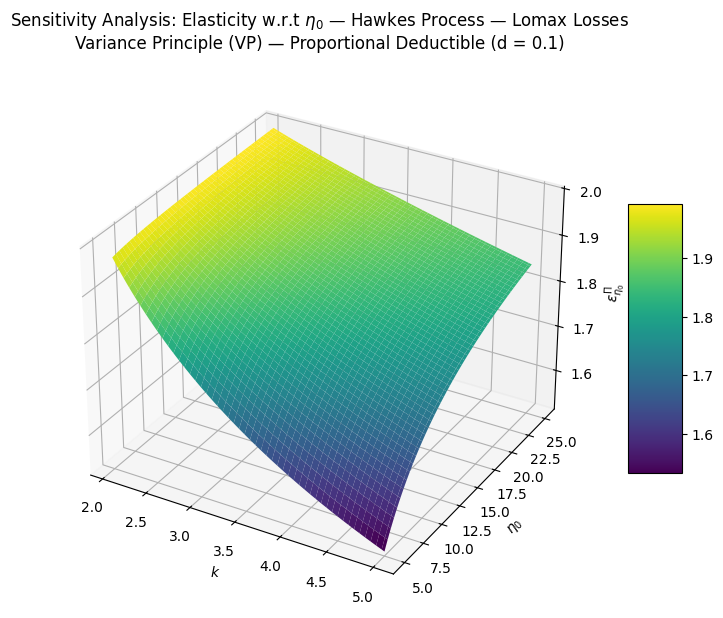

In [13]:
name = 'elasticity_eta_0_VP'

PL.Visual_elasticity_premium_eta_0_lomax(t = 1, C = 0.85, d = 0.1, H_0 = 25, Principle = 'VP', process_type = 'Hawkes', save_name = name)

Saved: thesis_plots/elasticity_k_VP.png


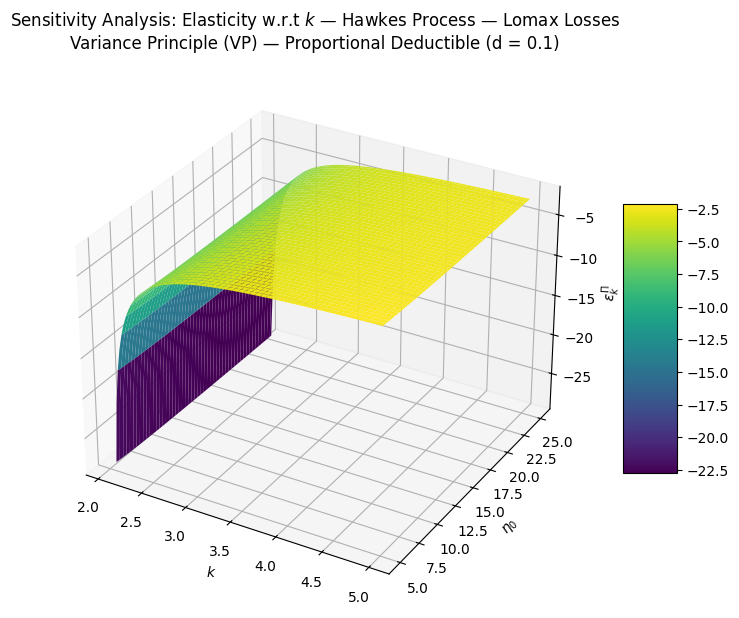

In [14]:
name = 'elasticity_k_VP'

PL.Visual_elasticity_premium_k_lomax(t = 1, C = 0.85, d = 0.1, H_0 = 25, Principle = 'VP', process_type = 'Hawkes', save_name = name)

Saved: thesis_plots/Lomax_Comparison_VP_27.png


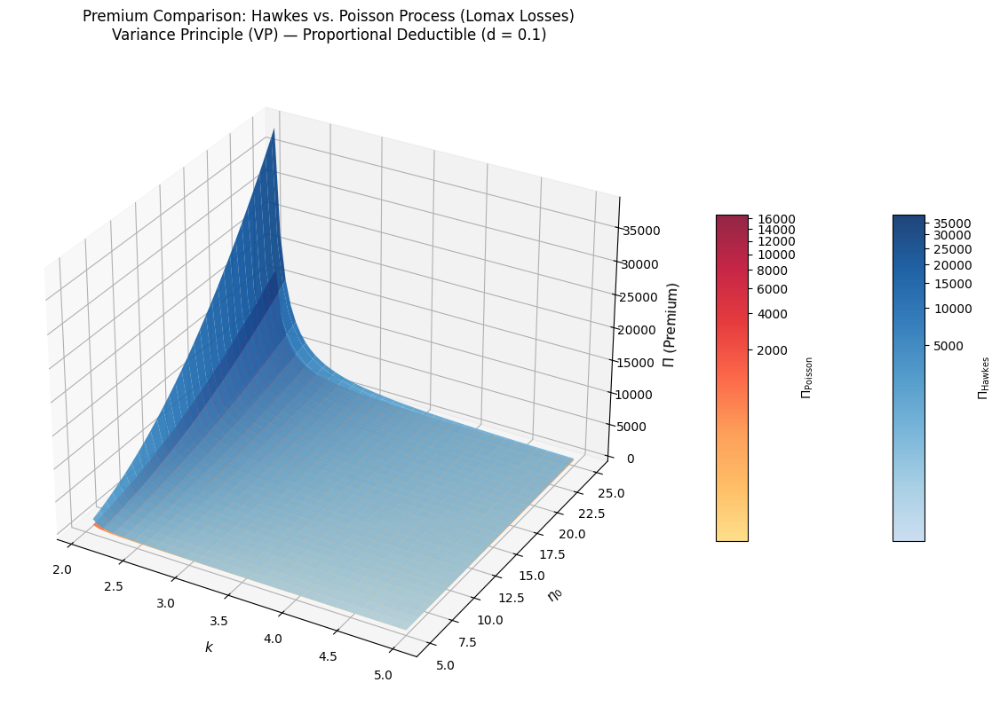

In [15]:
name = 'Lomax_Comparison_VP_27'

PL.Premium_comparison(t = 1, C = 0.85, d = 0.1, H_0 = 25, lambda_poisson = 27, Principle = 'VP', dist_type= 'lomax', save_name = name)

Saved: thesis_plots/Lomax_Comparison_VP_61.png


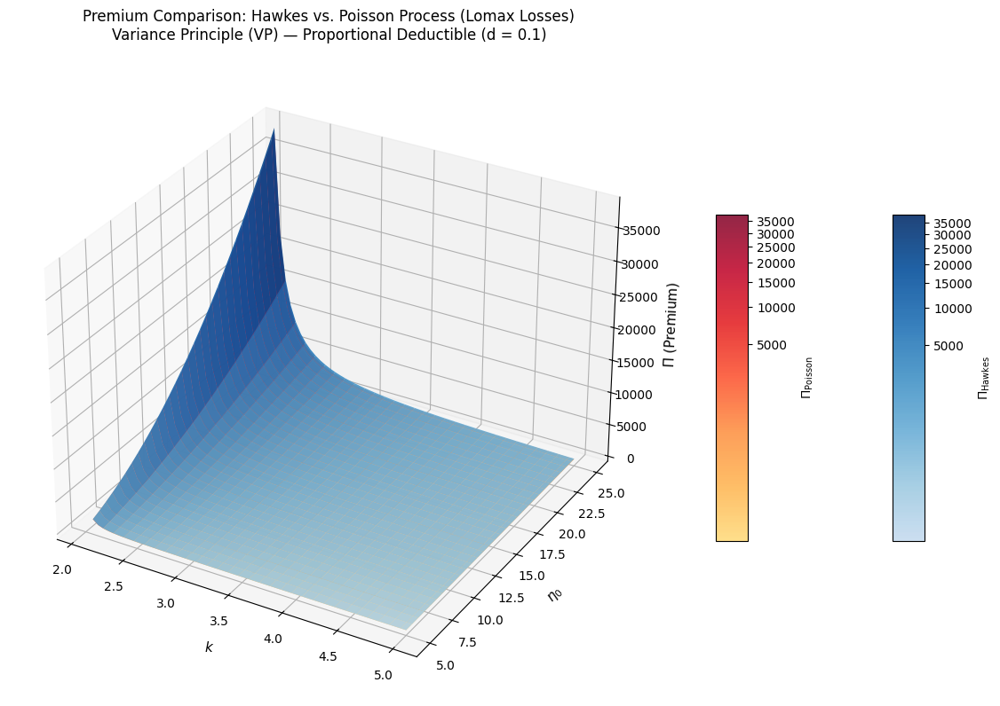

In [16]:
name = 'Lomax_Comparison_VP_61'

PL.Premium_comparison(t = 1, C = 0.85, d = 0.1, H_0 = 25, lambda_poisson = 61, Principle = 'VP', dist_type= 'lomax', save_name = name)

## Lognormal SDP

Saved: thesis_plots/Premium_Lognormal_SDP.png


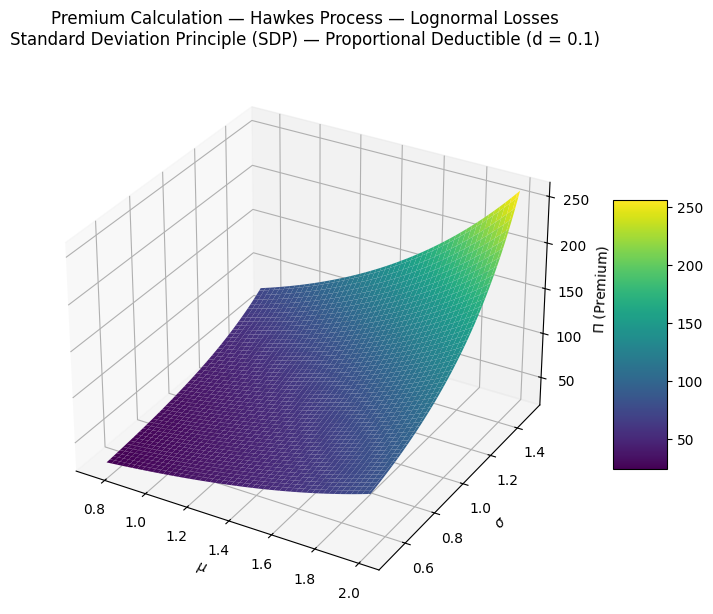

In [17]:
name = 'Premium_Lognormal_SDP'

PL.Visual_premium_lognormal(t = 1, C = 0.85, d = 0.1, H_0 = 25, Principle = 'SDP', process_type = 'Hawkes', save_name = name)

Saved: thesis_plots/elasticity_mu_SDP.png


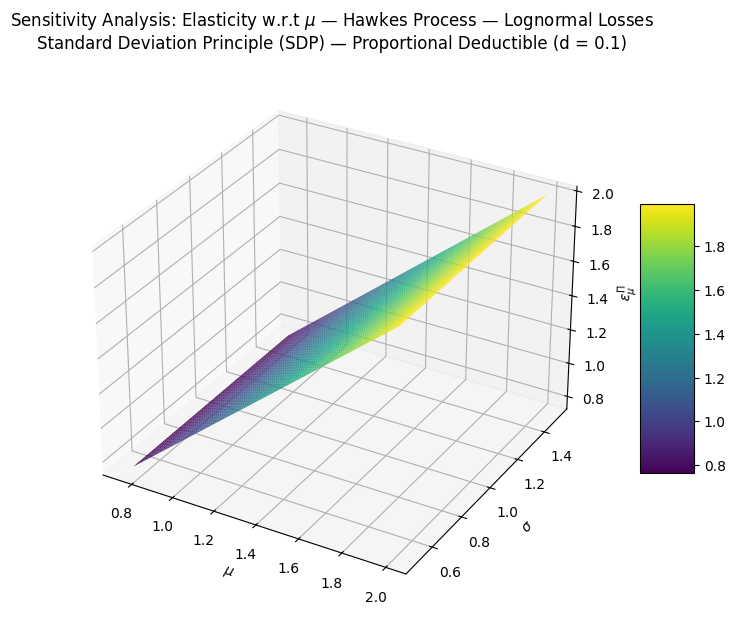

In [18]:
name = 'elasticity_mu_SDP'

PL.Visual_elasticity_premium_mu(t = 1, C = 0.85, d = 0.1, H_0 = 25, Principle = 'SDP', process_type = 'Hawkes', save_name = name)

Saved: thesis_plots/elasticity_sigma_SDP.png


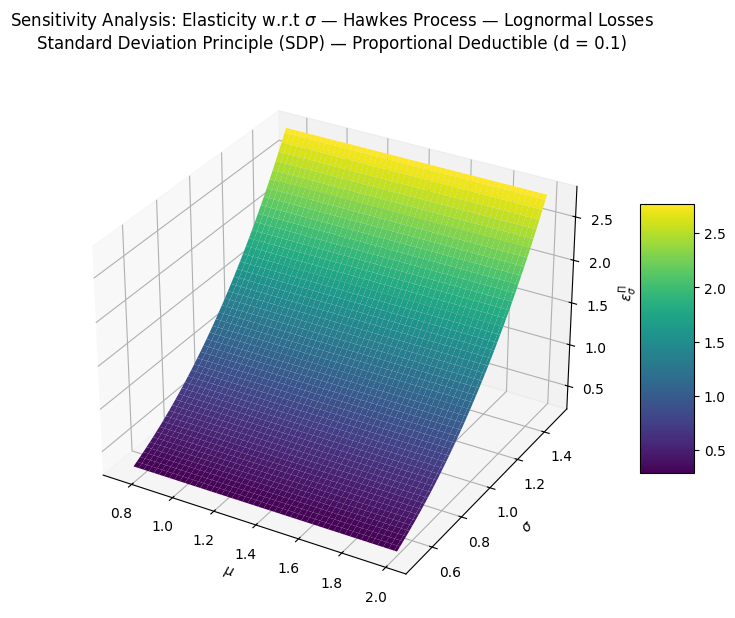

In [19]:
name = 'elasticity_sigma_SDP'

PL.Visual_elasticity_premium_sigma(t = 1, C = 0.85, d = 0.1, H_0 = 25, Principle = 'SDP', process_type = 'Hawkes', save_name = name)

Saved: thesis_plots/Lognormal_Comparison_SDP_27.png


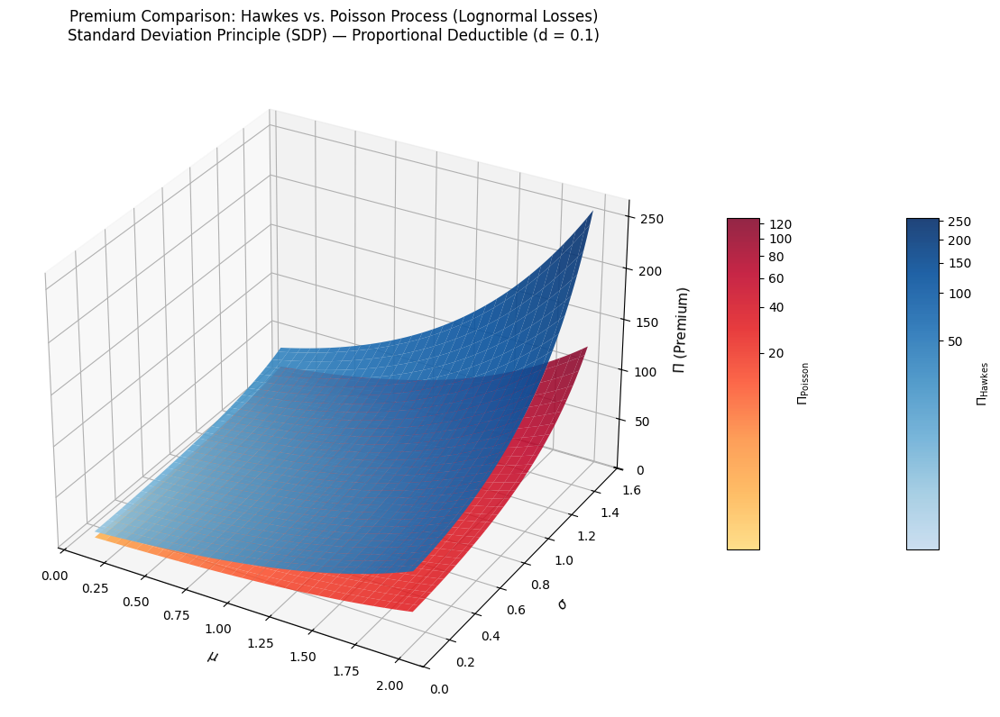

In [20]:
name = 'Lognormal_Comparison_SDP_27'

PL.Premium_comparison(t = 1, C = 0.85, d = 0.1, H_0 = 25, lambda_poisson = 27, Principle = 'SDP', dist_type= 'lognormal', save_name = name)

Saved: thesis_plots/Lognormal_Comparison_SDP_61.png


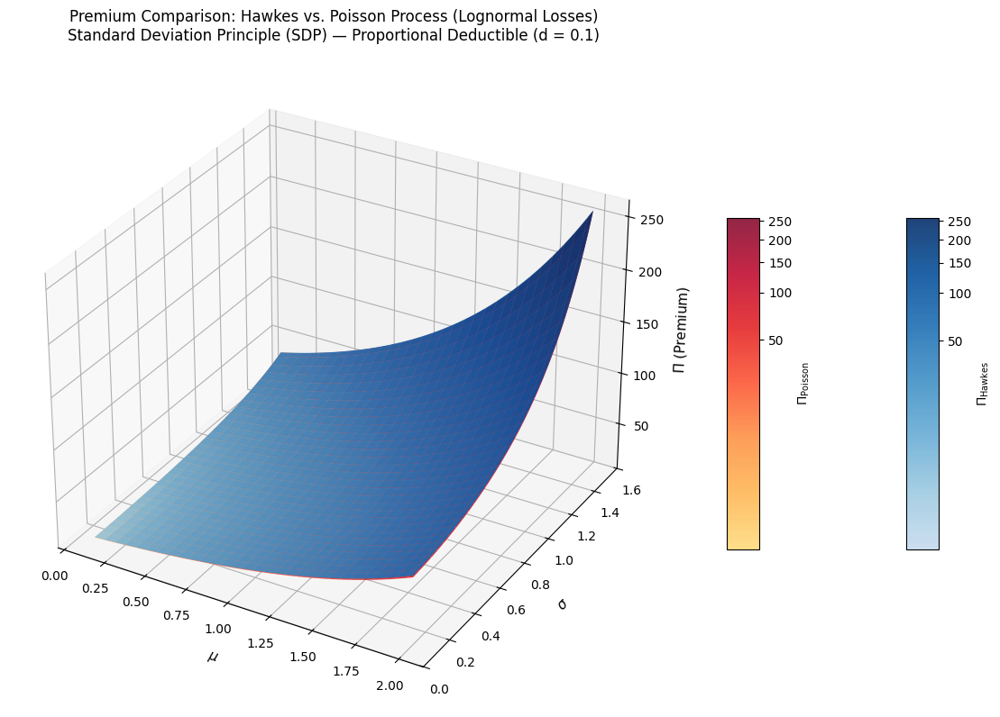

In [21]:
name = 'Lognormal_Comparison_SDP_61'

PL.Premium_comparison(t = 1, C = 0.85, d = 0.1, H_0 = 25, lambda_poisson = 61, Principle = 'SDP', dist_type= 'lognormal', save_name = name)

## Lognormal VP

Saved: thesis_plots/Premium_Lognormal_VP.png


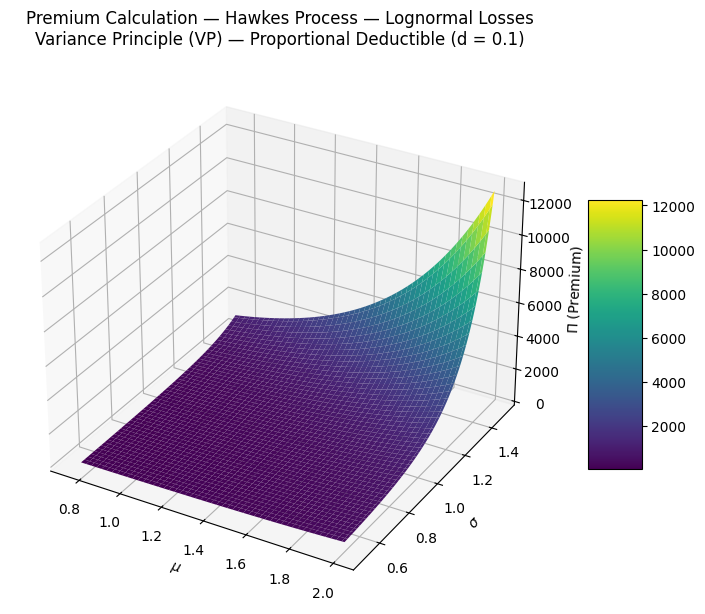

In [22]:
name = 'Premium_Lognormal_VP'

PL.Visual_premium_lognormal(t = 1, C = 0.85, d = 0.1, H_0 = 25, Principle = 'VP', process_type = 'Hawkes', save_name = name)

Saved: thesis_plots/elasticity_mu_VP.png


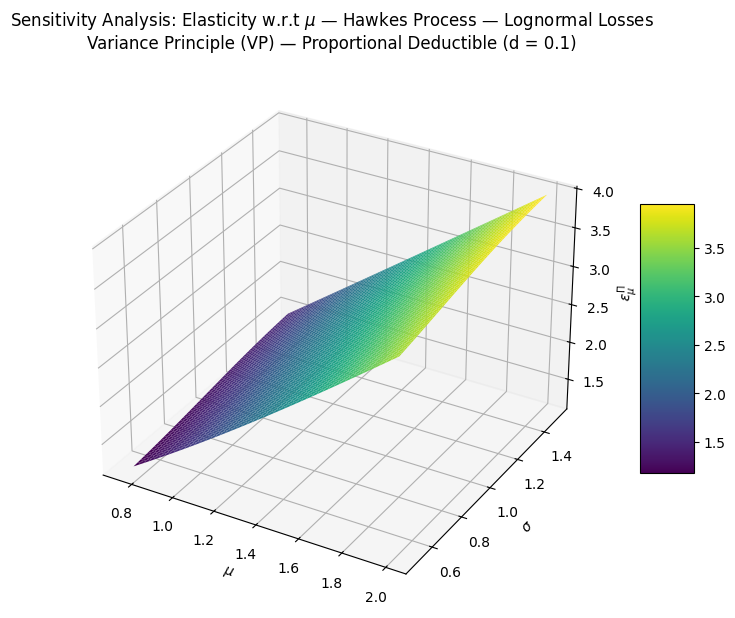

In [23]:
name = 'elasticity_mu_VP'

PL.Visual_elasticity_premium_mu(t = 1, C = 0.85, d = 0.1, H_0 = 25, Principle = 'VP', process_type = 'Hawkes', save_name = name)

Saved: thesis_plots/elasticity_sigma_VP.png


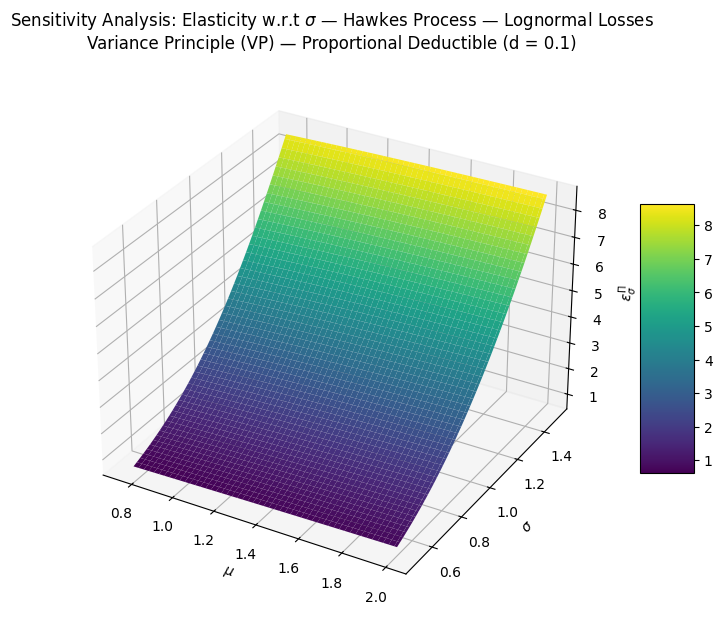

In [24]:
name = 'elasticity_sigma_VP'

PL.Visual_elasticity_premium_sigma(t = 1, C = 0.85, d = 0.1, H_0 = 25, Principle = 'VP', process_type = 'Hawkes', save_name = name)

Saved: thesis_plots/Lognormal_Comparison_VP_27.png


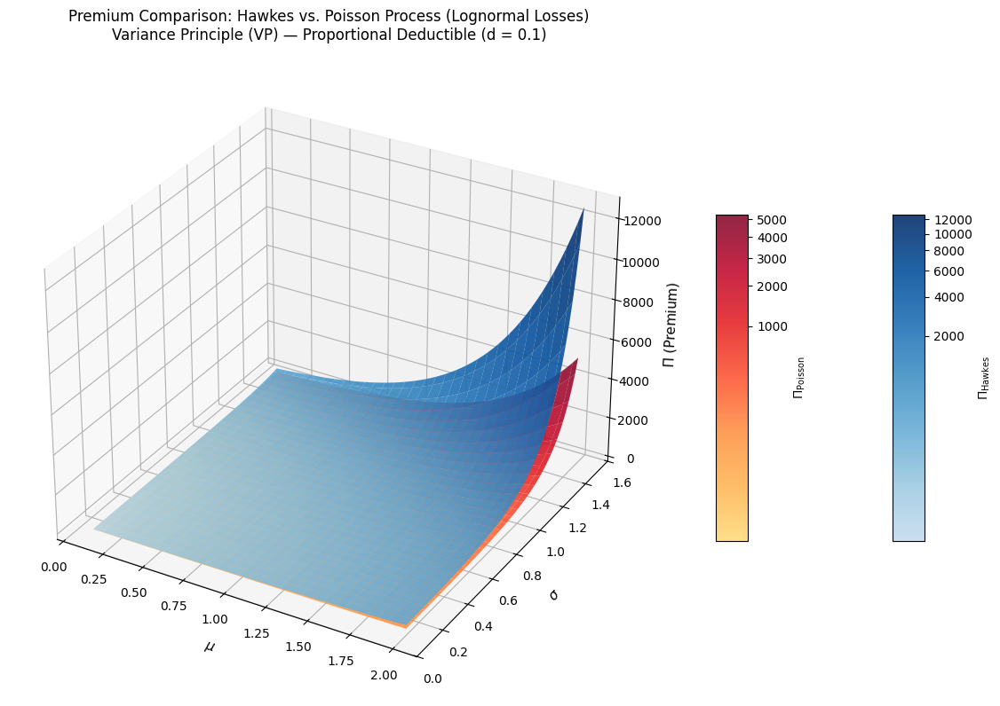

In [25]:
name = 'Lognormal_Comparison_VP_27'

PL.Premium_comparison(t = 1, C = 0.85, d = 0.1, H_0 = 25, lambda_poisson = 27, Principle = 'VP', dist_type= 'lognormal', save_name = name)

Saved: thesis_plots/Lognormal_Comparison_VP_61.png


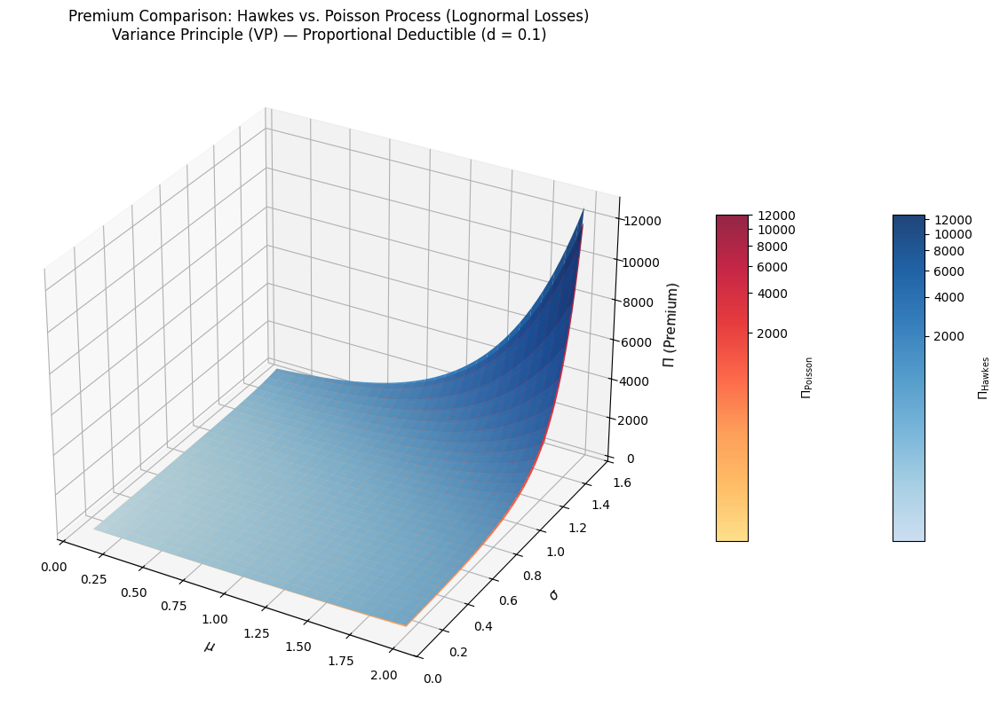

In [26]:
name = 'Lognormal_Comparison_VP_61'

PL.Premium_comparison(t = 1, C = 0.85, d = 0.1, H_0 = 25, lambda_poisson = 61, Principle = 'VP', dist_type= 'lognormal', save_name = name)

# **Risk-Neutral Framework**

## **Inner Control Problem**

### **Value Functions and Optimal Control**

Saved: thesis_plots/V0_Lomax_I_Hawkes1.png
Saved: thesis_plots/V0_Lomax_I_Hawkes2.png
Saved: thesis_plots/V0_Lomax_I_Hawkes3.png


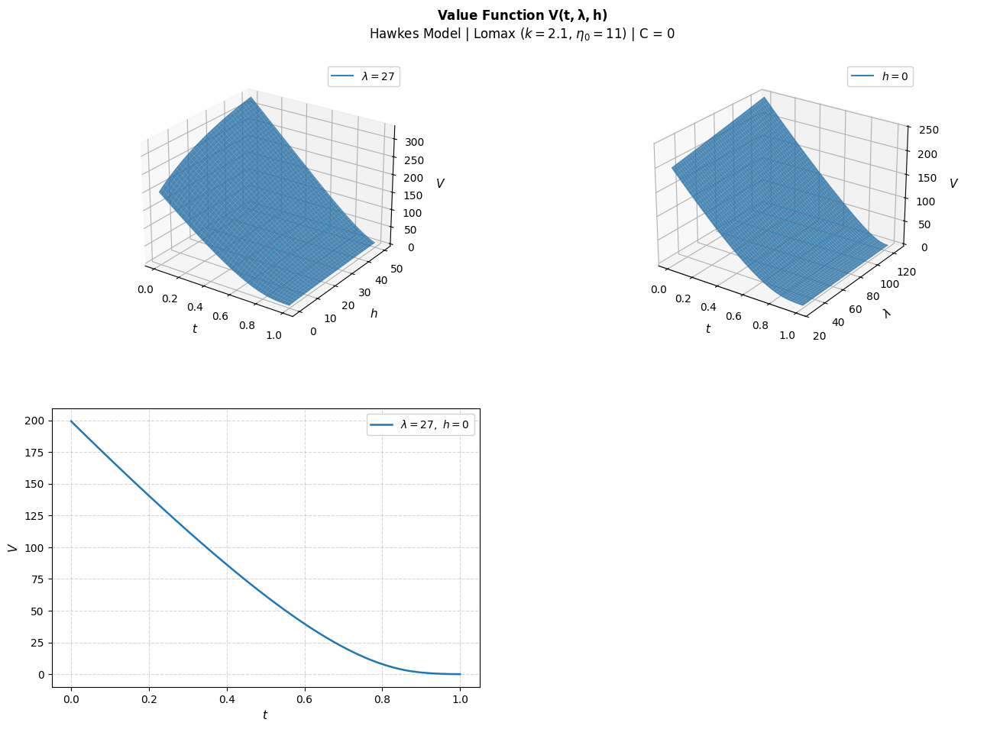

Saved: thesis_plots/z0_Lomax_I_Hawkes1.png
Saved: thesis_plots/z0_Lomax_I_Hawkes2.png
Saved: thesis_plots/z0_Lomax_I_Hawkes3.png


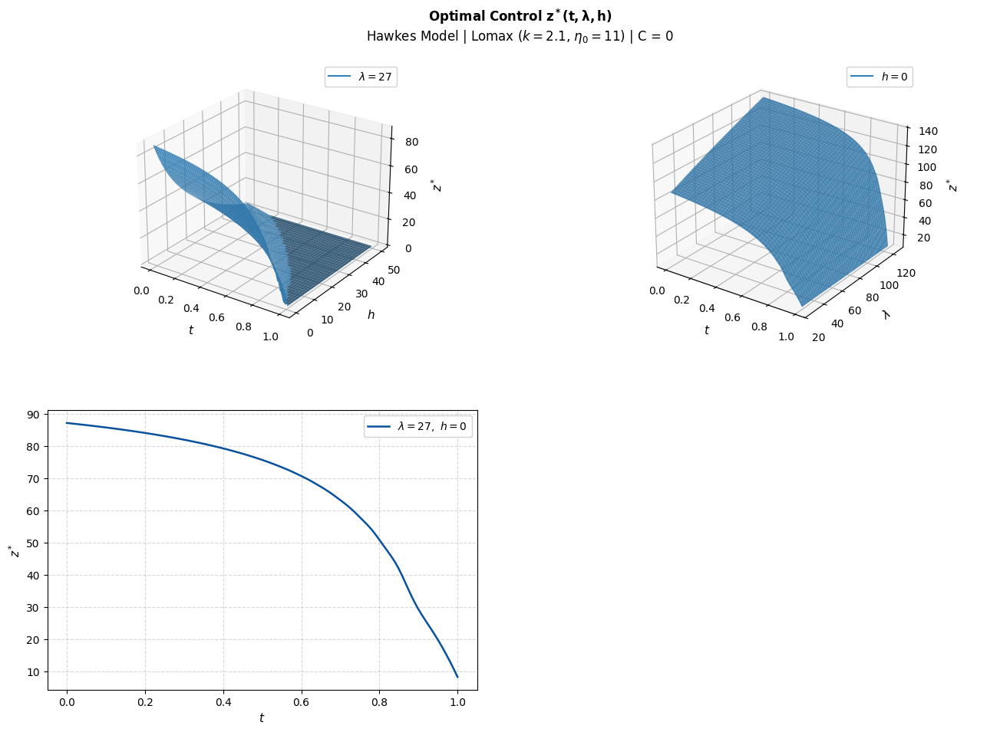

In [27]:
names_V=['V0_Lomax_I_Hawkes1', 'V0_Lomax_I_Hawkes2', 'V0_Lomax_I_Hawkes3']
names_z=['z0_Lomax_I_Hawkes1', 'z0_Lomax_I_Hawkes2', 'z0_Lomax_I_Hawkes3']

V0_Lomax_I_Hawkes, _ = Hawkes_PIDE_solver(dist_type="lomax", k=2.1, eta_0=11, C=0)
z0_Lomax_I_Hawkes = z_star(V0_Lomax_I_Hawkes, d_lambda = 1, d_h = 0.5, gamma = 0.05)

_ = PL.plot_value_function(V0_Lomax_I_Hawkes, lambda_fixed=27, h_fixed=0, context = 'RN',
                        dist_type="Lomax", k=2.1, eta_0=11, C=0, d=0.1, lambda_plot_max=125, save_names = names_V)
_ = PL.plot_optimal_control(V0_Lomax_I_Hawkes, lambda_fixed=27, h_fixed=0,
                         dist_type="Lomax", k=2.1, eta_0=11, C=0, d=0.1, lambda_plot_max=125, save_names = names_z)

Saved: thesis_plots/V1_Lomax_I_Hawkes1.png
Saved: thesis_plots/V1_Lomax_I_Hawkes2.png
Saved: thesis_plots/V1_Lomax_I_Hawkes3.png


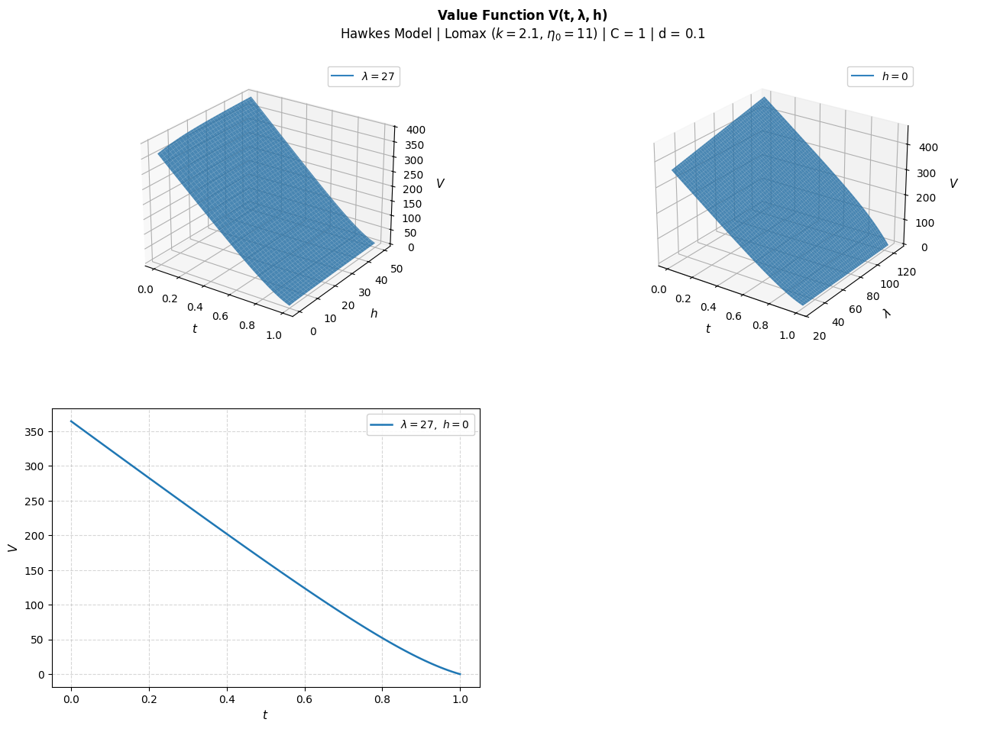

Saved: thesis_plots/z1_Lomax_I_Hawkes1.png
Saved: thesis_plots/z1_Lomax_I_Hawkes2.png
Saved: thesis_plots/z1_Lomax_I_Hawkes3.png


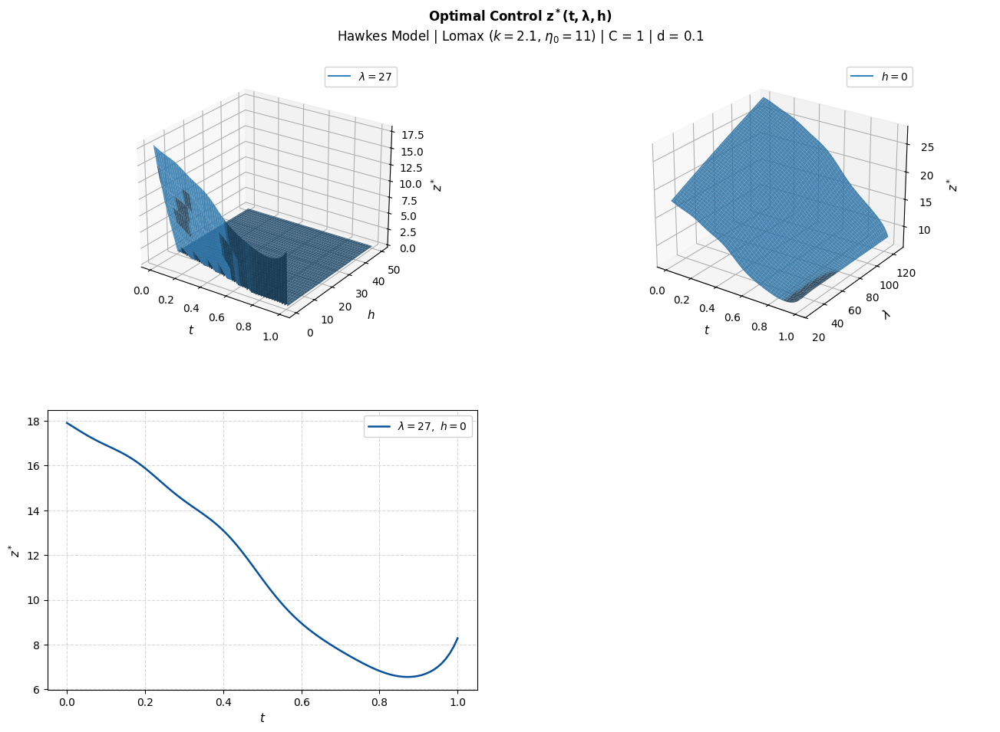

In [28]:
names_V=['V1_Lomax_I_Hawkes1', 'V1_Lomax_I_Hawkes2', 'V1_Lomax_I_Hawkes3']
names_z=['z1_Lomax_I_Hawkes1', 'z1_Lomax_I_Hawkes2', 'z1_Lomax_I_Hawkes3']

V1_Lomax_I_Hawkes, _ = Hawkes_PIDE_solver(dist_type="lomax", k=2.1, eta_0=11, C=1, d=0.1, U_sqrt=True)
z1_Lomax_I_Hawkes = z_star(V1_Lomax_I_Hawkes, d_lambda = 1, d_h = 0.5, gamma = 0.05)

_ = PL.plot_value_function(V1_Lomax_I_Hawkes, lambda_fixed=27, h_fixed=0, context = 'RN',
                        dist_type="Lomax", k=2.1, eta_0=11, C=1, d=0.1, lambda_plot_max=125, save_names = names_V)
_ = PL.plot_optimal_control(V1_Lomax_I_Hawkes, lambda_fixed=27, h_fixed=0,
                         dist_type="Lomax", k=2.1, eta_0=11, C=1, d=0.1, lambda_plot_max=125, save_names = names_z)

Saved: thesis_plots/z1_Lomax_I_Hawkes1_U0.png
Saved: thesis_plots/z1_Lomax_I_Hawkes2_U0.png
Saved: thesis_plots/z1_Lomax_I_Hawkes3_U0.png


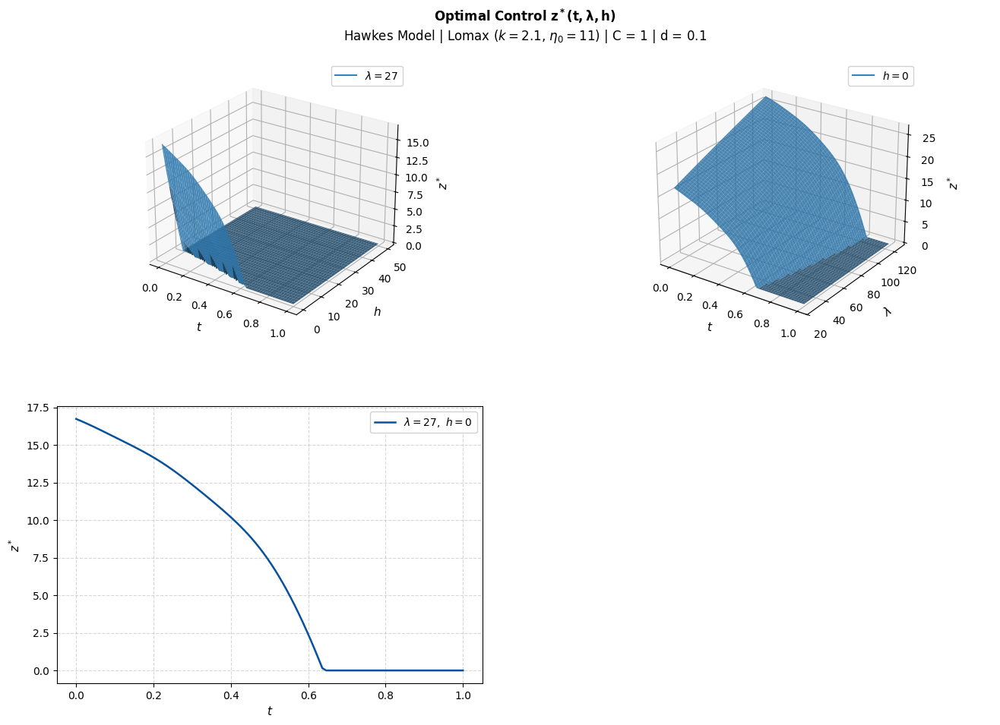

In [29]:
names_z=['z1_Lomax_I_Hawkes1_U0', 'z1_Lomax_I_Hawkes2_U0', 'z1_Lomax_I_Hawkes3_U0']

V1_Lomax_I_Hawkes_U0, _ = Hawkes_PIDE_solver(dist_type="lomax", k=2.1, eta_0=11, C=1, d=0.1, U_sqrt=False)

_ = PL.plot_optimal_control(V1_Lomax_I_Hawkes_U0, lambda_fixed=27, h_fixed=0,
                         dist_type="Lomax", k=2.1, eta_0=11, C=1, d=0.1, lambda_plot_max=125, save_names = names_z)

### **Sensitivity analysis of the Value Function and the Optimal Control**

In [30]:
lambda_fixed = 27
h_fixed = 0

#### Sensitivity with respect to $\xi$

In [31]:
xi_grid = [15,25,35,45,50]

Solving V for xi=15 ...
Solving V for xi=25 ...
Solving V for xi=35 ...
Solving V for xi=45 ...
Solving V for xi=50 ...
Saved: thesis_plots/sensitivity0_xi_V.png
Saved: thesis_plots/sensitivity0_xi_z.png


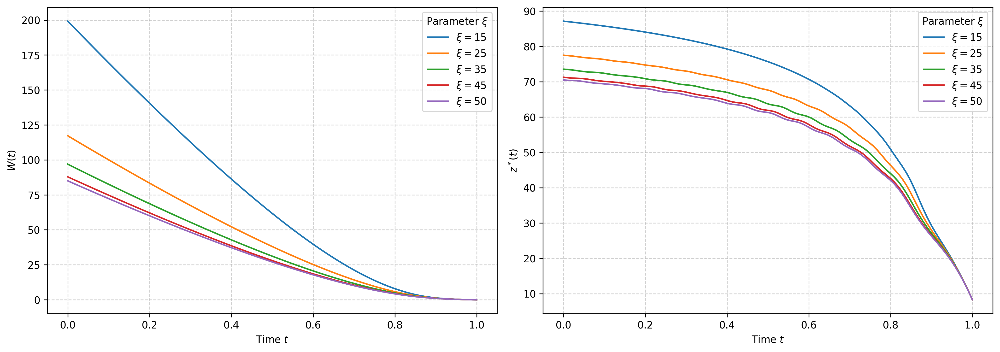

In [32]:
names = ['sensitivity0_xi_V', 'sensitivity0_xi_z']

fig, axes = PL.plot_parameter_sensitivity("xi", xi_grid, lambda_fixed=lambda_fixed, h_fixed=h_fixed,
                                        dist_type="lomax", k=2.1, eta_0=11, C=0, save_names = names)

Solving V for xi=15 ...
Solving V for xi=25 ...
Solving V for xi=35 ...
Solving V for xi=45 ...
Solving V for xi=50 ...
Saved: thesis_plots/sensitivity1_xi_V.png
Saved: thesis_plots/sensitivity1_xi_z.png


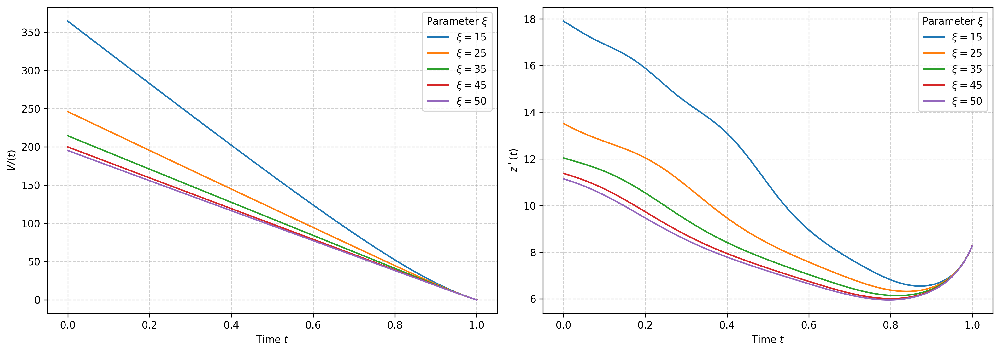

In [33]:
names = ['sensitivity1_xi_V', 'sensitivity1_xi_z']

fig, axes = PL.plot_parameter_sensitivity("xi", xi_grid, lambda_fixed=lambda_fixed, h_fixed=h_fixed,
                                        dist_type="lomax", k=2.1, eta_0=11, C=1, d=0.1, save_names = names)

#### Sensitivity with respect to $\rho$

In [34]:
rho_grid = [0,0.25,0.5,0.75,1]

Solving V for rho=0 ...
Solving V for rho=0.25 ...
Solving V for rho=0.5 ...
Solving V for rho=0.75 ...
Solving V for rho=1 ...
Saved: thesis_plots/sensitivity0_rho_V.png
Saved: thesis_plots/sensitivity0_rho_z.png


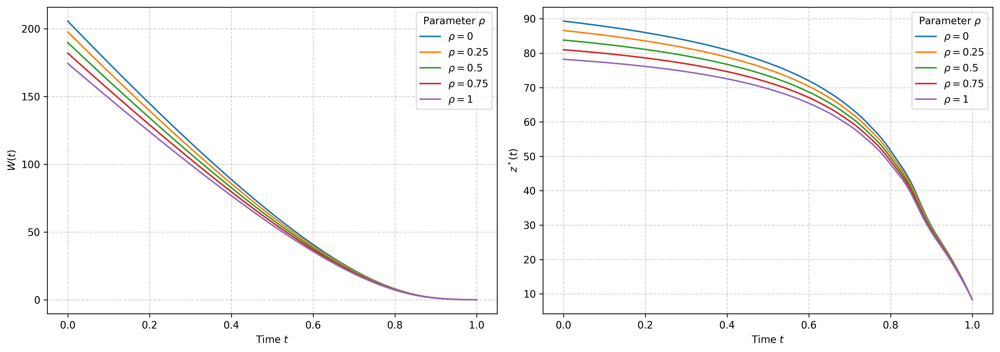

In [35]:
names = ['sensitivity0_rho_V', 'sensitivity0_rho_z']

fig, axes = PL.plot_parameter_sensitivity("rho", rho_grid, lambda_fixed=lambda_fixed, h_fixed=h_fixed,
                                        dist_type="lomax", k=2.1, eta_0=11, C=0, save_names = names)

Solving V for rho=0 ...
Solving V for rho=0.25 ...
Solving V for rho=0.5 ...
Solving V for rho=0.75 ...
Solving V for rho=1 ...
Saved: thesis_plots/sensitivity1_rho_V.png
Saved: thesis_plots/sensitivity1_rho_z.png


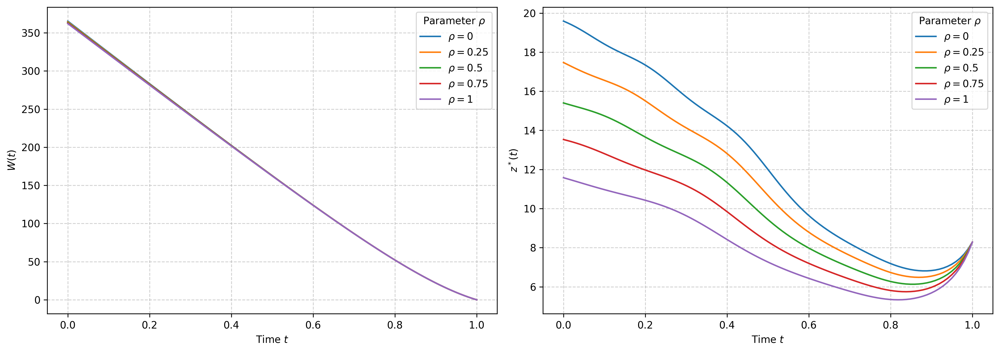

In [36]:
names = ['sensitivity1_rho_V', 'sensitivity1_rho_z']

fig, axes = PL.plot_parameter_sensitivity("rho", rho_grid, lambda_fixed=lambda_fixed, h_fixed=h_fixed,
                                        dist_type="lomax", k=2.1, eta_0=11, C=1, d=0.1, save_names = names)

#### Sensitivity with respect to $d$

In [37]:
d_grid = [0,0.05,0.10,0.15,0.2,1]

Solving V for d=0 ...
Solving V for d=0.05 ...
Solving V for d=0.1 ...
Solving V for d=0.15 ...
Solving V for d=0.2 ...
Solving V for d=1 ...
Saved: thesis_plots/sensitivity1_d_V.png
Saved: thesis_plots/sensitivity1_d_z.png


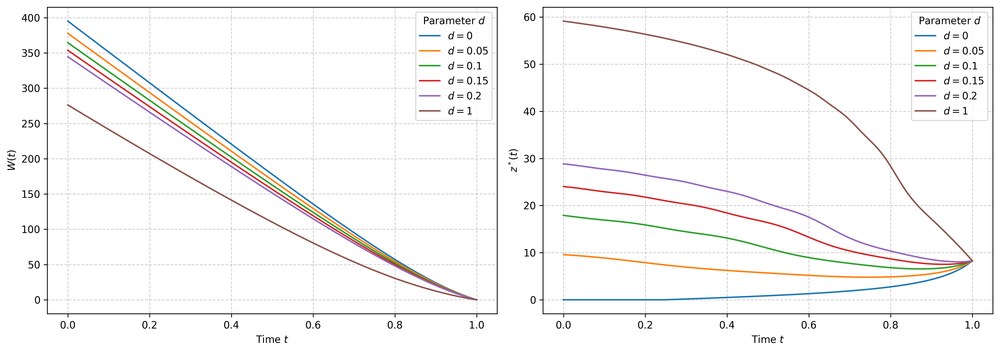

In [38]:
names = ['sensitivity1_d_V', 'sensitivity1_d_z']

fig, axes = PL.plot_parameter_sensitivity("d", d_grid, lambda_fixed=lambda_fixed, h_fixed=h_fixed,
                                        dist_type="lomax", k=2.1, eta_0=11, C=1, save_names = names)

### **Gain against static optimal investment strategy**

Saved: thesis_plots/gain0_static_investment.png


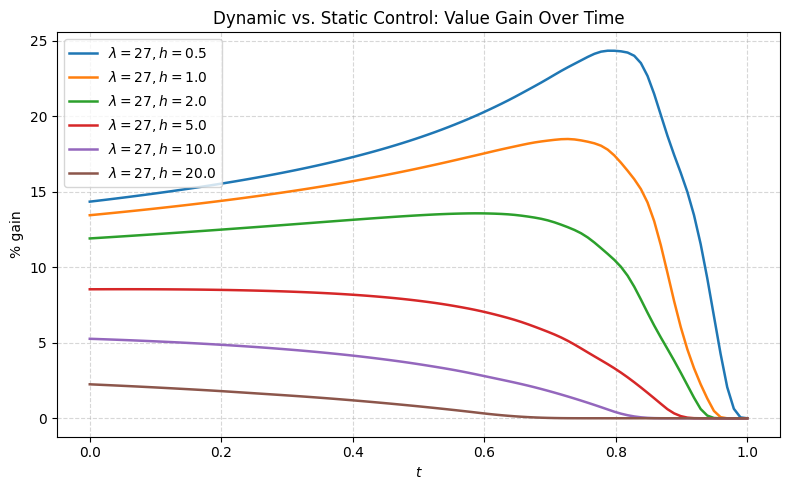

In [39]:
name = 'gain0_static_investment'

PL.plot_dynamic_vs_static_gain(V0_Lomax_I_Hawkes, dist_type = 'lomax', k = 2.1, eta_0 = 11, C = 0, save_name = name)

Saved: thesis_plots/gain1_static_investment.png


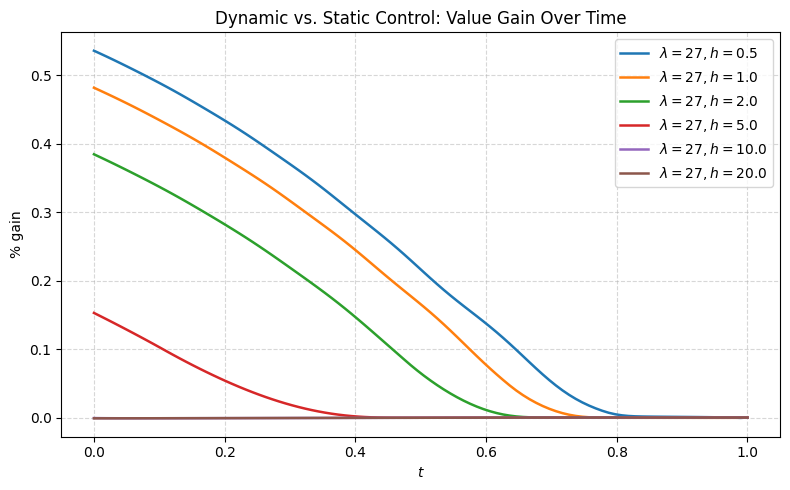

In [40]:
name = 'gain1_static_investment'

V1_Lomax_I_Hawkes_ref , _ = Hawkes_PIDE_solver(dist_type="lomax", k=2.1, eta_0=11, C=1, d=0.1, d_h = 0.25, U_sqrt=True) 
PL.plot_dynamic_vs_static_gain(V1_Lomax_I_Hawkes_ref, dist_type = 'lomax', k = 2.1, eta_0 = 11, C = 1, d = 0.1, d_h = 0.25, save_name = name)

### **Gain against static z = 0 investment strategy**

Saved: thesis_plots/gain1_zero_investment.png


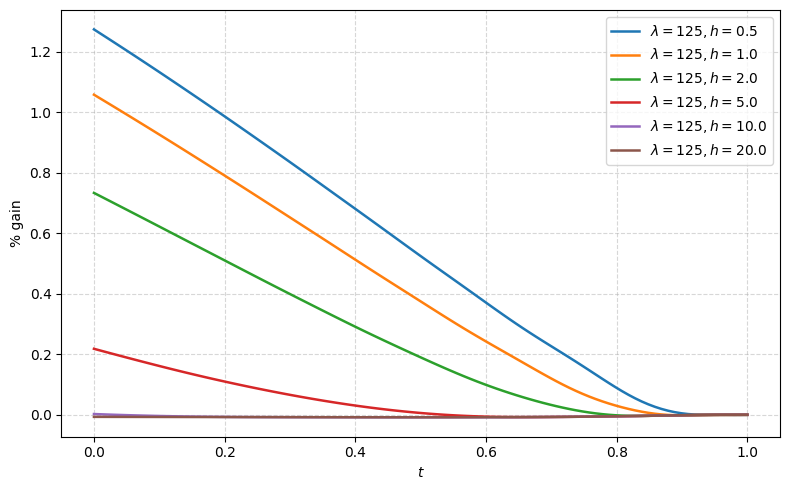

In [41]:
name = 'gain1_zero_investment'

V1_Lomax_I_Hawkes_ref , _ = Hawkes_PIDE_solver(dist_type="lomax", k=2.1, eta_0=11, C=1, d=0.1, d_h = 0.25, U_sqrt=True) 
PL.plot_dynamic_vs_constant_gain(V1_Lomax_I_Hawkes_ref, z_val = 0, lambda_fixed = 125 ,dist_type = 'lomax', k = 2.1, eta_0 = 11, C = 1, d = 0.1, 
                                 d_h = 0.25, save_name = name)

### **Comparison with the Poisson Process Benchmark**

#### $\lambda = 27$

Saved: thesis_plots/V0_27_Poisson_Hawkes_1.png
Saved: thesis_plots/V0_27_Poisson_Hawkes_2.png
Saved: thesis_plots/V0_27_Poisson_Hawkes_3.png


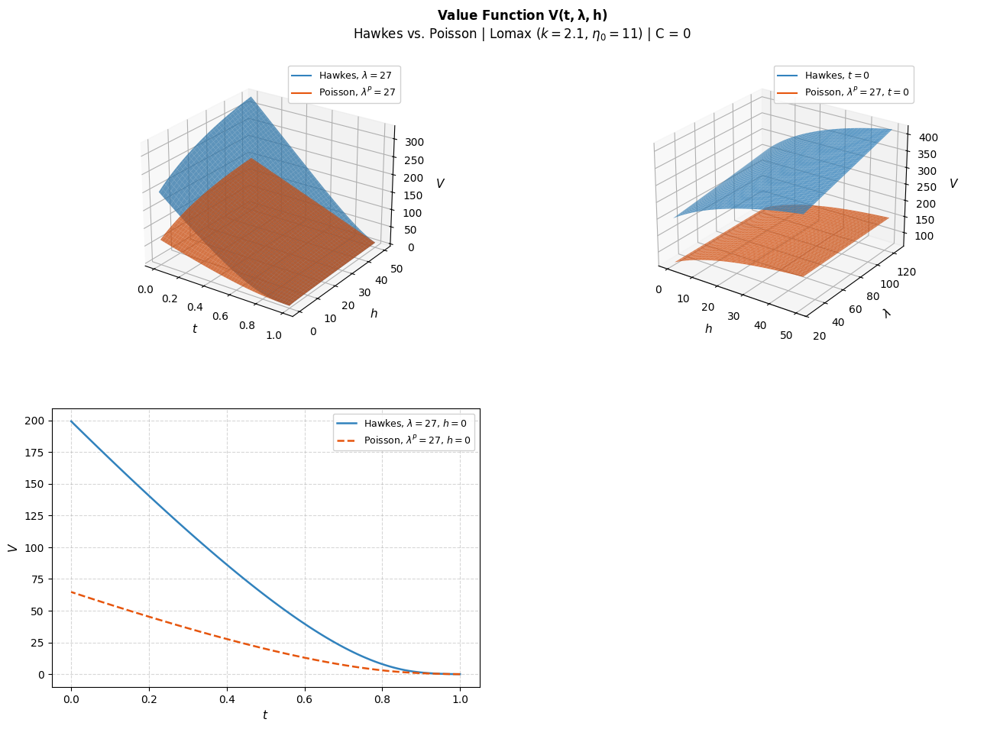

Saved: thesis_plots/z0_27_Poisson_Hawkes_1.png
Saved: thesis_plots/z0_27_Poisson_Hawkes_2.png
Saved: thesis_plots/z0_27_Poisson_Hawkes_3.png


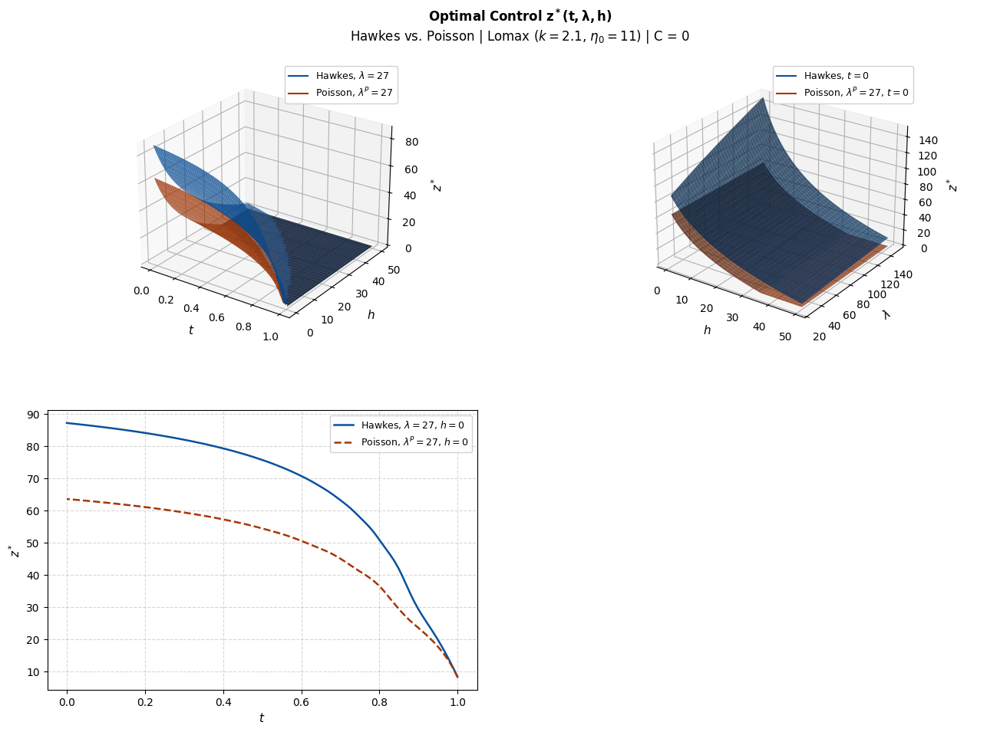

In [42]:
names_V=['V0_27_Poisson_Hawkes_1', 'V0_27_Poisson_Hawkes_2', 'V0_27_Poisson_Hawkes_3']
names_z=['z0_27_Poisson_Hawkes_1', 'z0_27_Poisson_Hawkes_2', 'z0_27_Poisson_Hawkes_3']

J0_Lomax_I_poisson27, _ = Poisson_PDE_solver(dist_type = 'lomax', k = 2.1, eta_0 = 11, C = 0)


PL.plot_value_function_vs_poisson(V0_Lomax_I_Hawkes, J0_Lomax_I_poisson27, lambda_fixed=27, h_fixed=0, t_fixed=0.0, context = 'RN',
                                dist_type='Lomax', k=2.1, eta_0=11, C=0, lambda_plot_max=125, save_names = names_V)


z0_Lomax_I_Hawkes, z0_mat_poisson27 = PL.plot_optimal_control_vs_poisson(
    V0_Lomax_I_Hawkes, J0_Lomax_I_poisson27, gamma=0.05,
    lambda_fixed=27, h_fixed=0, t_fixed=0.0,
    dist_type='Lomax', k=2.1, eta_0=11, C=0, save_names = names_z
)

Saved: thesis_plots/V1_27_Poisson_Hawkes_1.png
Saved: thesis_plots/V1_27_Poisson_Hawkes_2.png
Saved: thesis_plots/V1_27_Poisson_Hawkes_3.png


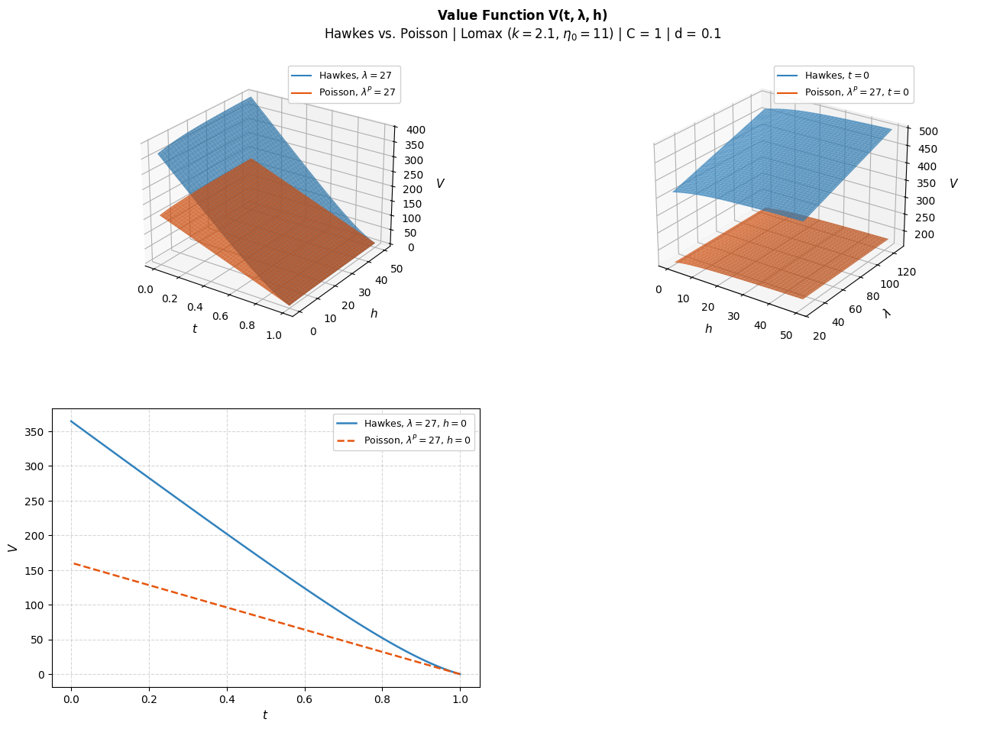

Saved: thesis_plots/z1_27_Poisson_Hawkes_1.png
Saved: thesis_plots/z1_27_Poisson_Hawkes_2.png
Saved: thesis_plots/z1_27_Poisson_Hawkes_3.png


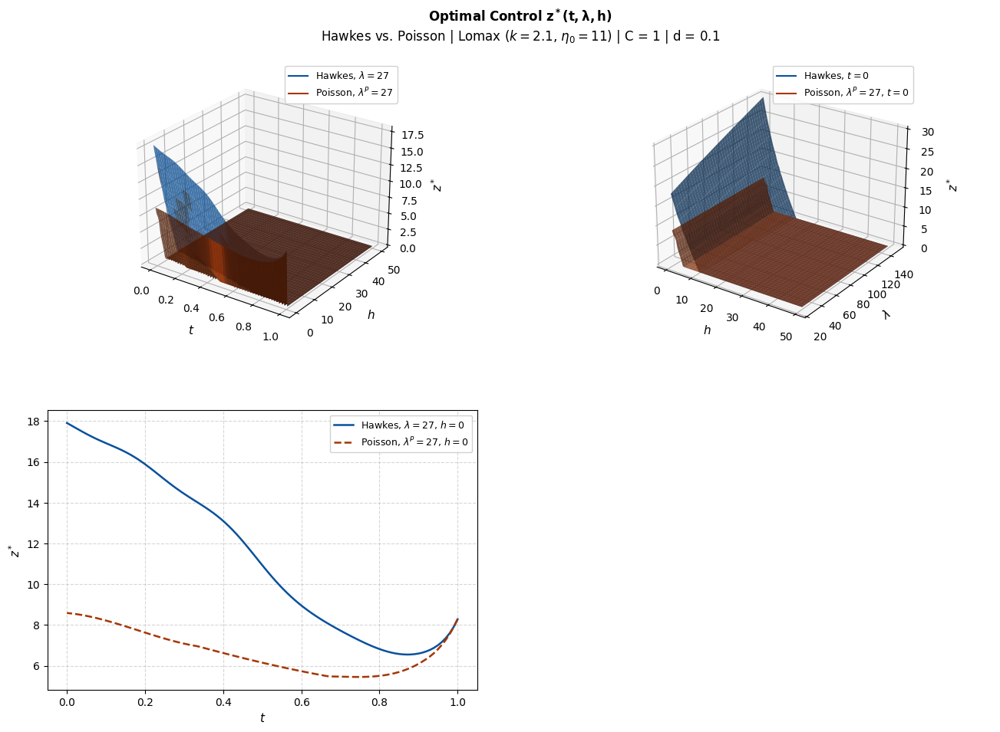

In [43]:
names_V=['V1_27_Poisson_Hawkes_1', 'V1_27_Poisson_Hawkes_2', 'V1_27_Poisson_Hawkes_3']
names_z=['z1_27_Poisson_Hawkes_1', 'z1_27_Poisson_Hawkes_2', 'z1_27_Poisson_Hawkes_3']

J1_Lomax_I_poisson27, _ = Poisson_PDE_solver(dist_type = 'lomax', k = 2.1, eta_0 = 11, C = 1, d = 0.1)


PL.plot_value_function_vs_poisson(V1_Lomax_I_Hawkes, J1_Lomax_I_poisson27, lambda_fixed=27, h_fixed=0, t_fixed=0.0, context = 'RN',
                                dist_type='Lomax', k=2.1, eta_0=11, C=1, d = 0.1, lambda_plot_max=125, save_names = names_V)


z1_Lomax_I_Hawkes, z1_mat_poisson27 = PL.plot_optimal_control_vs_poisson(
    V1_Lomax_I_Hawkes, J1_Lomax_I_poisson27, gamma=0.05,
    lambda_fixed=27, h_fixed=0, t_fixed=0.0,
    dist_type='Lomax', k=2.1, eta_0=11, C=1, d=0.1, save_names = names_z
)

#### $\lambda = 61$

Saved: thesis_plots/V0_61_Poisson_Hawkes_1.png
Saved: thesis_plots/V0_61_Poisson_Hawkes_2.png
Saved: thesis_plots/V0_61_Poisson_Hawkes_3.png


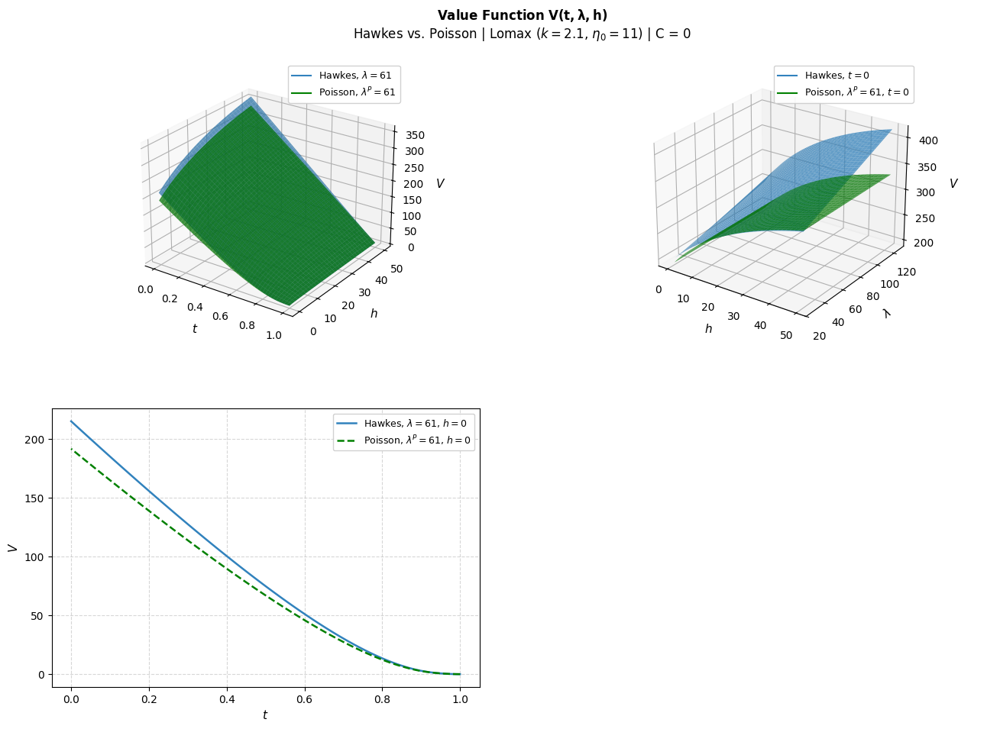

Saved: thesis_plots/z0_61_Poisson_Hawkes_1.png
Saved: thesis_plots/z0_61_Poisson_Hawkes_2.png
Saved: thesis_plots/z0_61_Poisson_Hawkes_3.png


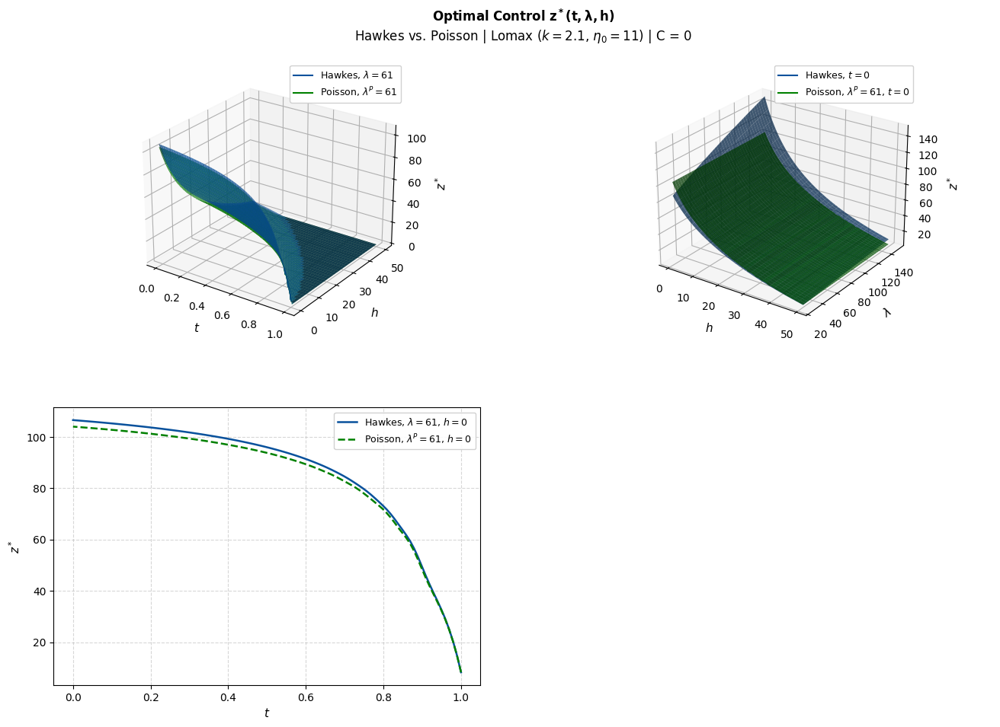

In [44]:
names_V=['V0_61_Poisson_Hawkes_1', 'V0_61_Poisson_Hawkes_2', 'V0_61_Poisson_Hawkes_3']
names_z=['z0_61_Poisson_Hawkes_1', 'z0_61_Poisson_Hawkes_2', 'z0_61_Poisson_Hawkes_3']

J0_Lomax_I_poisson61, _ = Poisson_PDE_solver(dist_type = 'lomax', lambda_0 = 61, k = 2.1, eta_0 = 11, C = 0)


PL.plot_value_function_vs_poisson(V0_Lomax_I_Hawkes, J0_Lomax_I_poisson61, lambda_fixed=61, h_fixed=0, t_fixed=0.0, context = 'RN',
                                dist_type='Lomax', k=2.1, eta_0=11, C=0, poisson_color="green", lambda_plot_max=125, save_names = names_V)


z0_Lomax_I_Hawkes, z0_mat_poisson61 = PL.plot_optimal_control_vs_poisson(
    V0_Lomax_I_Hawkes, J0_Lomax_I_poisson61, gamma=0.05,
    lambda_fixed=61, h_fixed=0, t_fixed=0.0,
    dist_type='Lomax', k=2.1, eta_0=11, C=0, poisson_color="green", save_names = names_z
)

Saved: thesis_plots/V1_61_Poisson_Hawkes_1.png
Saved: thesis_plots/V1_61_Poisson_Hawkes_2.png
Saved: thesis_plots/V1_61_Poisson_Hawkes_3.png


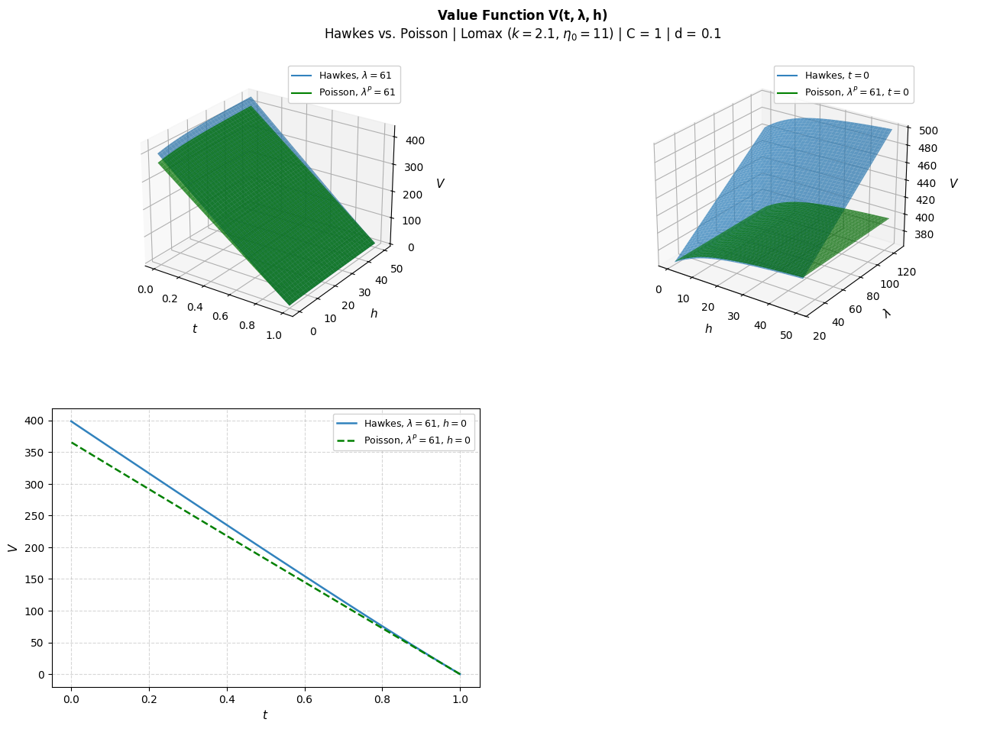

Saved: thesis_plots/z1_61_Poisson_Hawkes_1.png
Saved: thesis_plots/z1_61_Poisson_Hawkes_2.png
Saved: thesis_plots/z1_61_Poisson_Hawkes_3.png


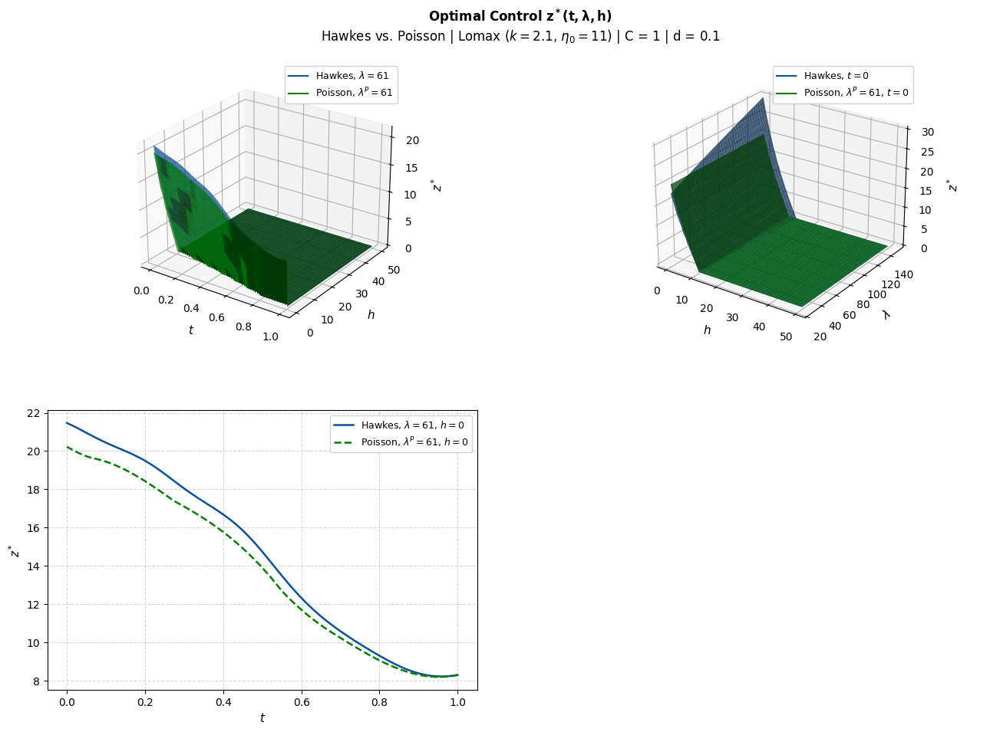

In [45]:
names_V=['V1_61_Poisson_Hawkes_1', 'V1_61_Poisson_Hawkes_2', 'V1_61_Poisson_Hawkes_3']
names_z=['z1_61_Poisson_Hawkes_1', 'z1_61_Poisson_Hawkes_2', 'z1_61_Poisson_Hawkes_3']

J1_Lomax_I_poisson61, _ = Poisson_PDE_solver(dist_type = 'lomax', lambda_0 = 61, k = 2.1, eta_0 = 11, C = 1, d = 0.1)


PL.plot_value_function_vs_poisson(V1_Lomax_I_Hawkes, J1_Lomax_I_poisson61, lambda_fixed=61, h_fixed=0, t_fixed=0.0, context = 'RN',
                                dist_type='Lomax', k=2.1, eta_0=11, C=1, d = 0.1, poisson_color="green", lambda_plot_max=125, save_names = names_V)


z1_Lomax_I_Hawkes, z1_mat_poisson61 = PL.plot_optimal_control_vs_poisson(
    V1_Lomax_I_Hawkes, J1_Lomax_I_poisson61, gamma=0.05,
    lambda_fixed=61, h_fixed=0, t_fixed=0.0,
    dist_type='Lomax', k=2.1, eta_0=11, C=1, d = 0.1, poisson_color="green", save_names = names_z
)

## **Global Optimization Problem (Bang-Bang Strategy)**

### **Decision Boundary $C^* \in \{0,1\}$**

Saved: thesis_plots/Lomax_comparison1.png
Saved: thesis_plots/Lomax_comparison2.png
Saved: thesis_plots/Lomax_comparison3.png


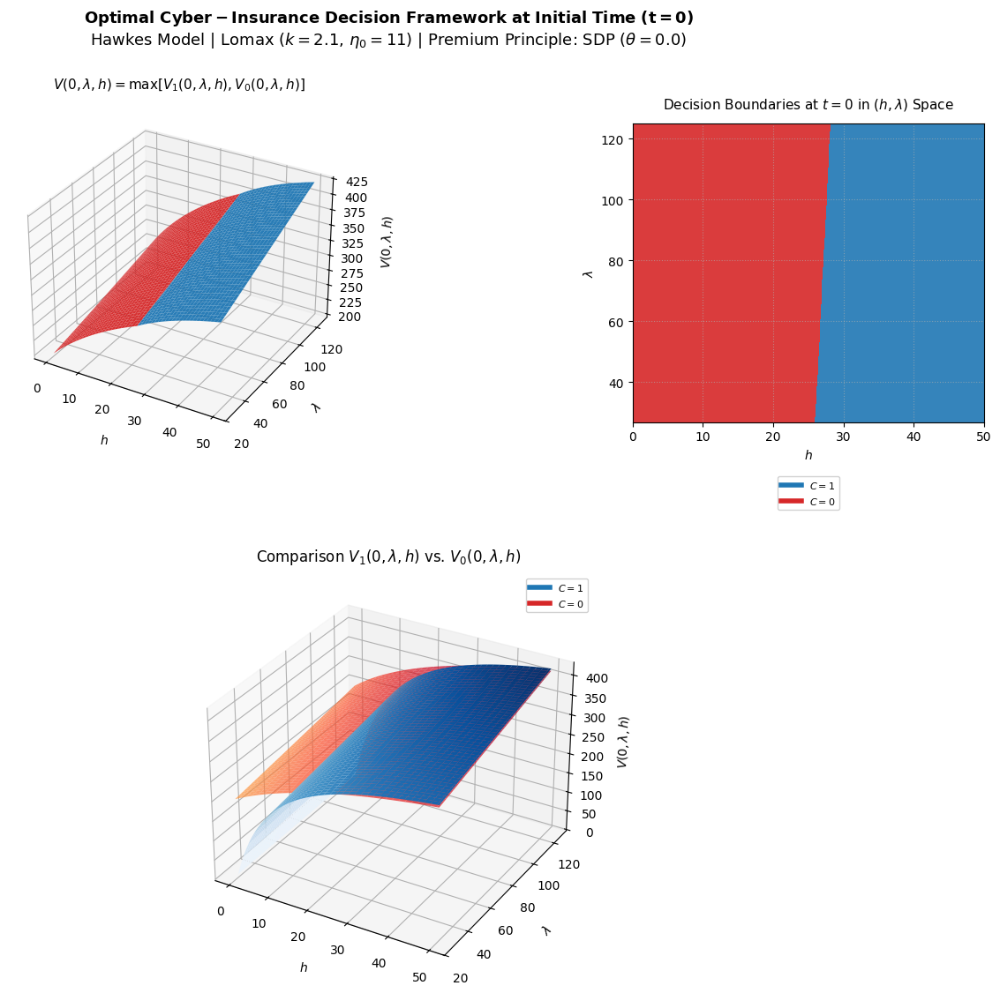

In [46]:
names =['Lomax_comparison1', 'Lomax_comparison2', 'Lomax_comparison3']

_ = PL.initial_comparison_1_0_Hawkes(
    V1=V1_Lomax_I_Hawkes, V0=V0_Lomax_I_Hawkes, dist_type="lomax", k=2.1, eta_0=11,lambda_plot_max=125,
    d=0.1, Principle="SDP", theta = 0.0, save_names = names, show_panel_title=True
)

Saved: thesis_plots/z_comparison_RN.png


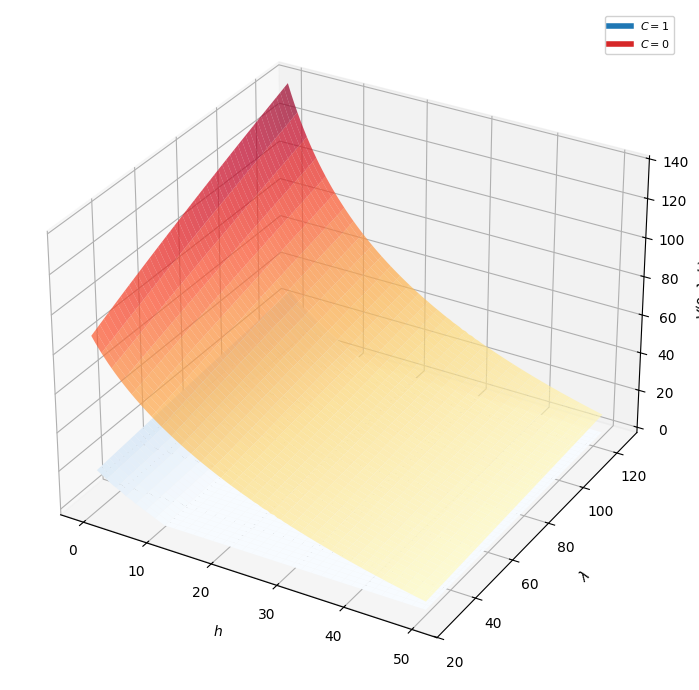

In [47]:
names =['z_comparison_RN']

# PL.initial_comparison_1_0_Hawkes is useful to compare between two different strategies in the grid lambda x h 
# at t = 0 when sub_Pre = False.
 
_ = PL.initial_comparison_1_0_Hawkes(
    V1=z1_Lomax_I_Hawkes, V0=z0_Lomax_I_Hawkes, dist_type="lomax", k=2.1, eta_0=11,lambda_plot_max=125, show_suptitle = False,
    d=0.1, Principle="SDP", theta = 0.0, save_names = names, panel = 'comparison_surface', sub_Pre=False,
)

Saved: thesis_plots/Lognormal_comparison1.png
Saved: thesis_plots/Lognormal_comparison2.png
Saved: thesis_plots/Lognormal_comparison3.png


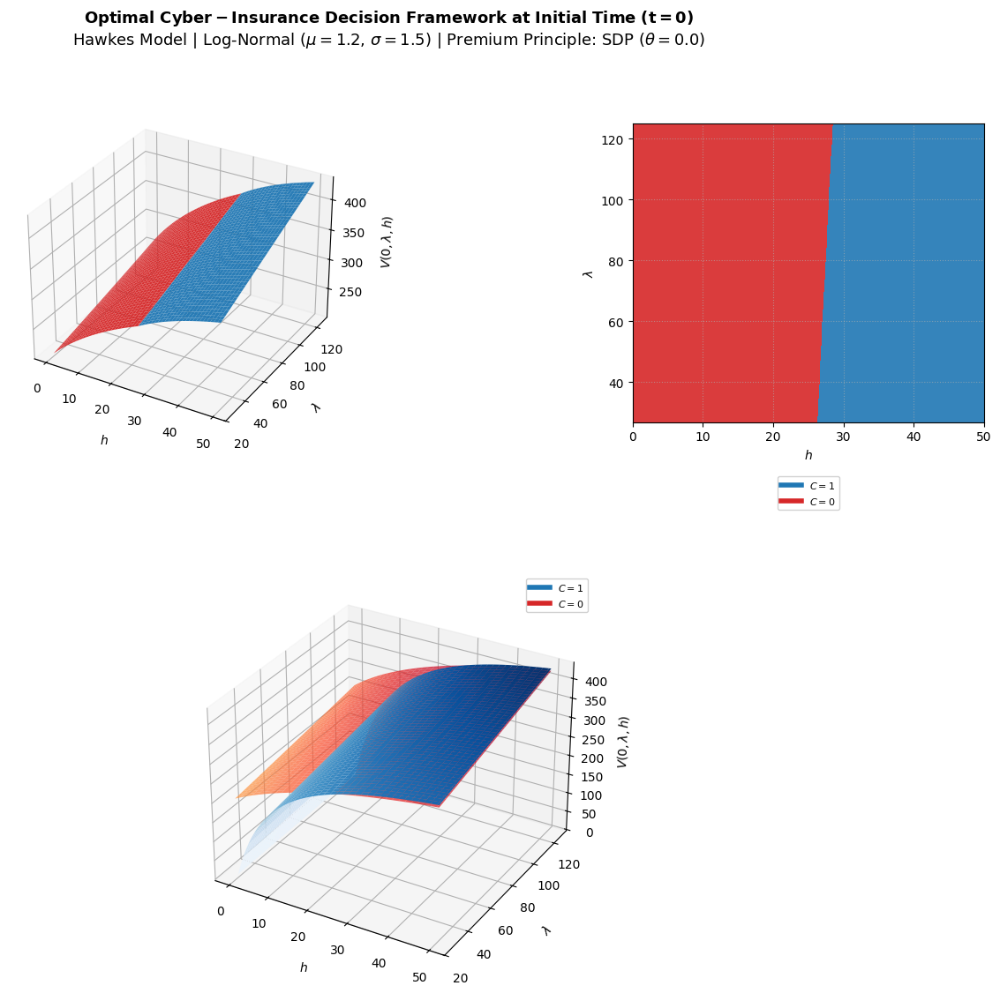

In [48]:
names =['Lognormal_comparison1', 'Lognormal_comparison2', 'Lognormal_comparison3']

_,_,V1_Lognormal_I_Hawkes,_,V0_Lognormal_I_Hawkes,_ = PL.initial_comparison_1_0_Hawkes(dist_type="lognormal", mu=1.2, sigma=1.5, d=0.1, 
                                                                                        Principle="SDP", theta = 0.0, lambda_plot_max=125,
                                                                                          save_names = names)

### **Sensitivity Analysis of the Decision Boundary**

#### Sensitivity with respect to $d$

Saved: thesis_plots/comparison_sensivity_d_0_1.png
Saved: thesis_plots/comparison_sensivity_d_0_2.png
Saved: thesis_plots/comparison_sensivity_d_0_3.png


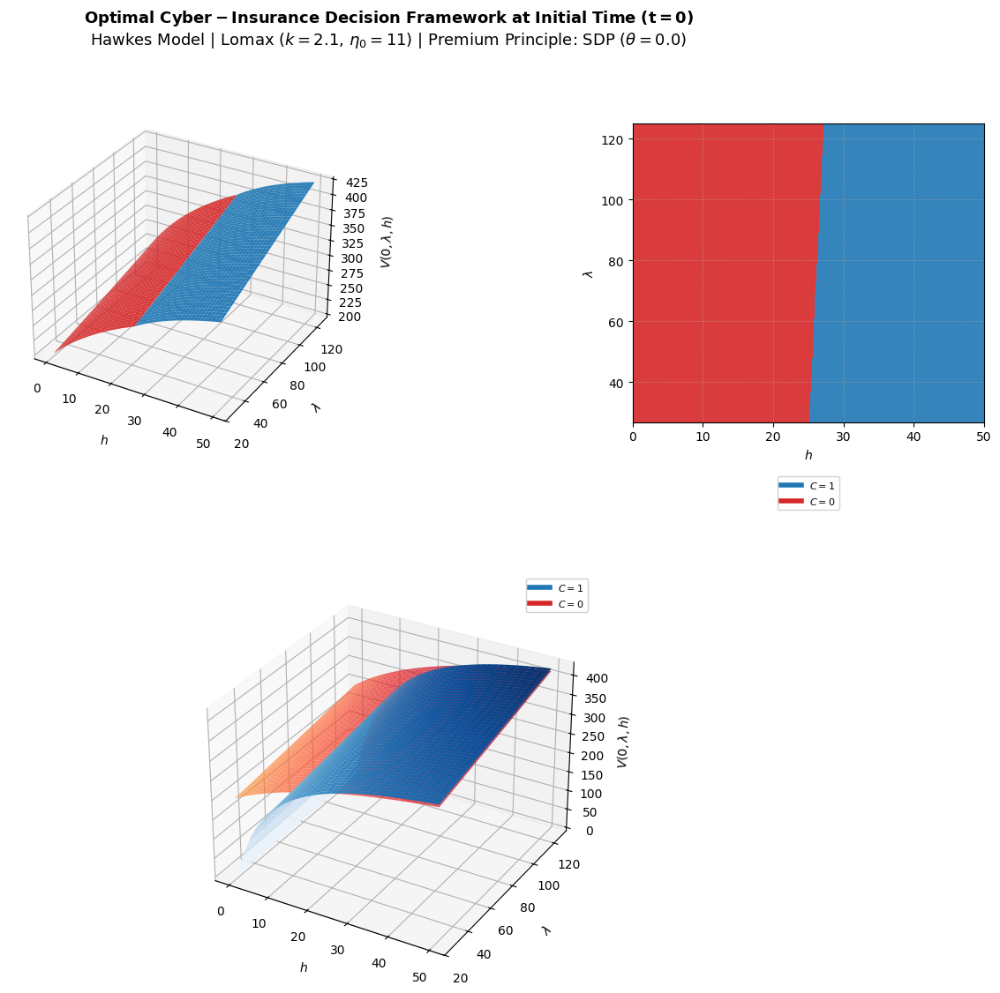

In [49]:
names =['comparison_sensivity_d_0_1', 'comparison_sensivity_d_0_2', 'comparison_sensivity_d_0_3']

_ = PL.initial_comparison_1_0_Hawkes(V0=V0_Lomax_I_Hawkes, dist_type="lomax", k=2.1, eta_0=11, d=0, Principle="SDP", 
                                     theta = 0.0, lambda_plot_max=125, save_names = names)

Saved: thesis_plots/comparison_sensivity_d_005_1.png
Saved: thesis_plots/comparison_sensivity_d_0005_2.png
Saved: thesis_plots/comparison_sensivity_d_005_3.png


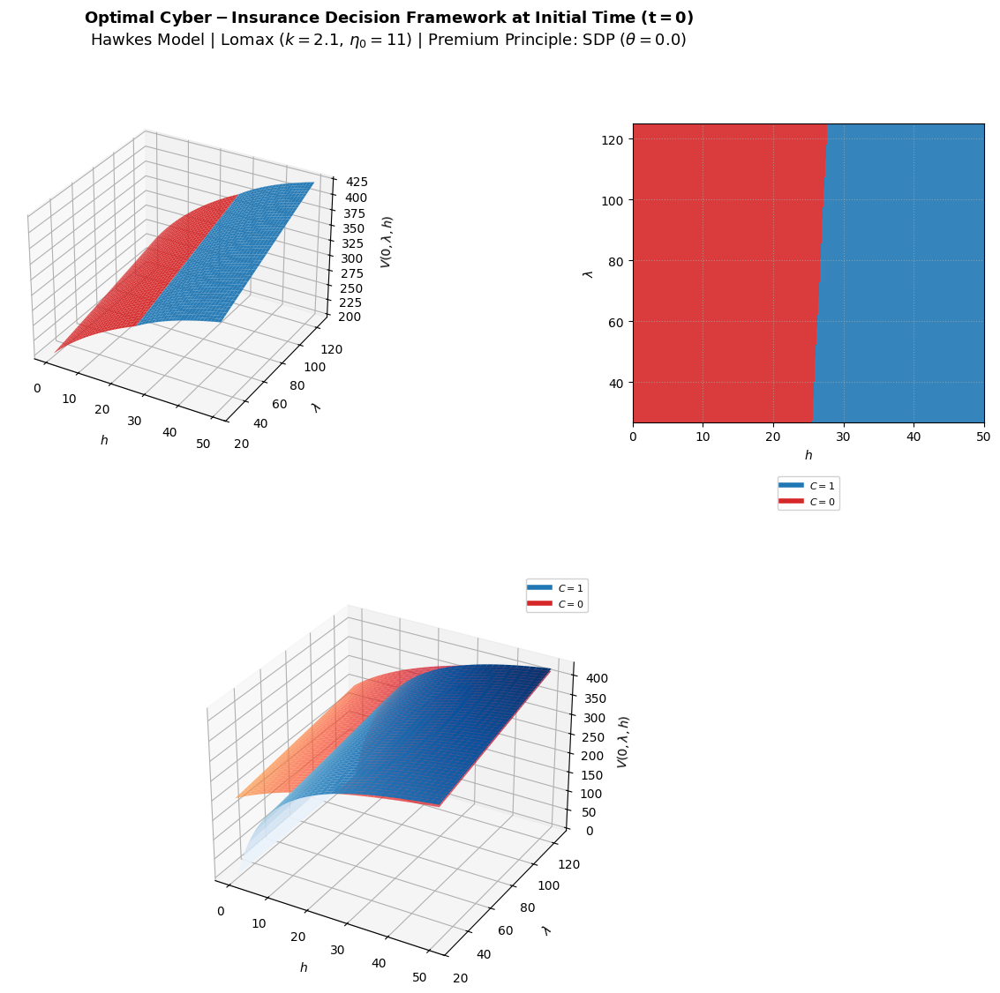

In [50]:
names =['comparison_sensivity_d_005_1', 'comparison_sensivity_d_0005_2', 'comparison_sensivity_d_005_3']

_ = PL.initial_comparison_1_0_Hawkes(V0=V0_Lomax_I_Hawkes, dist_type="lomax", k=2.1, eta_0=11, d=0.05, Principle="SDP", 
                                     theta = 0.0, lambda_plot_max=125, save_names = names)

Saved: thesis_plots/comparison_sensivity_d_015_1.png
Saved: thesis_plots/comparison_sensivity_d_015_2.png
Saved: thesis_plots/comparison_sensivity_d_015_3.png


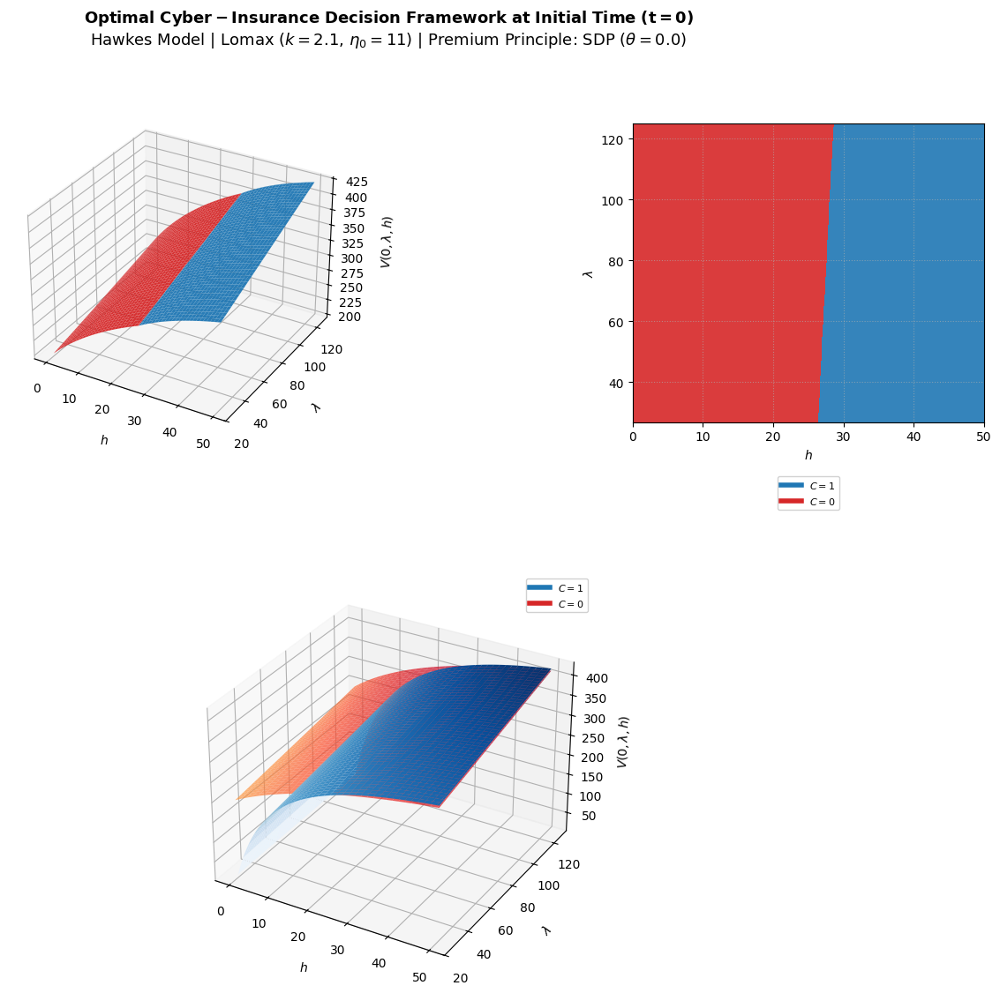

In [51]:
names =['comparison_sensivity_d_015_1', 'comparison_sensivity_d_015_2', 'comparison_sensivity_d_015_3']

_ = PL.initial_comparison_1_0_Hawkes(V0=V0_Lomax_I_Hawkes, dist_type="lomax", k=2.1, eta_0=11, d=0.15, Principle="SDP", 
                                     theta = 0.0, lambda_plot_max=125, save_names = names)

Saved: thesis_plots/comparison_sensivity_d_02_1.png
Saved: thesis_plots/comparison_sensivity_d_02_2.png
Saved: thesis_plots/comparison_sensivity_d_02_3.png


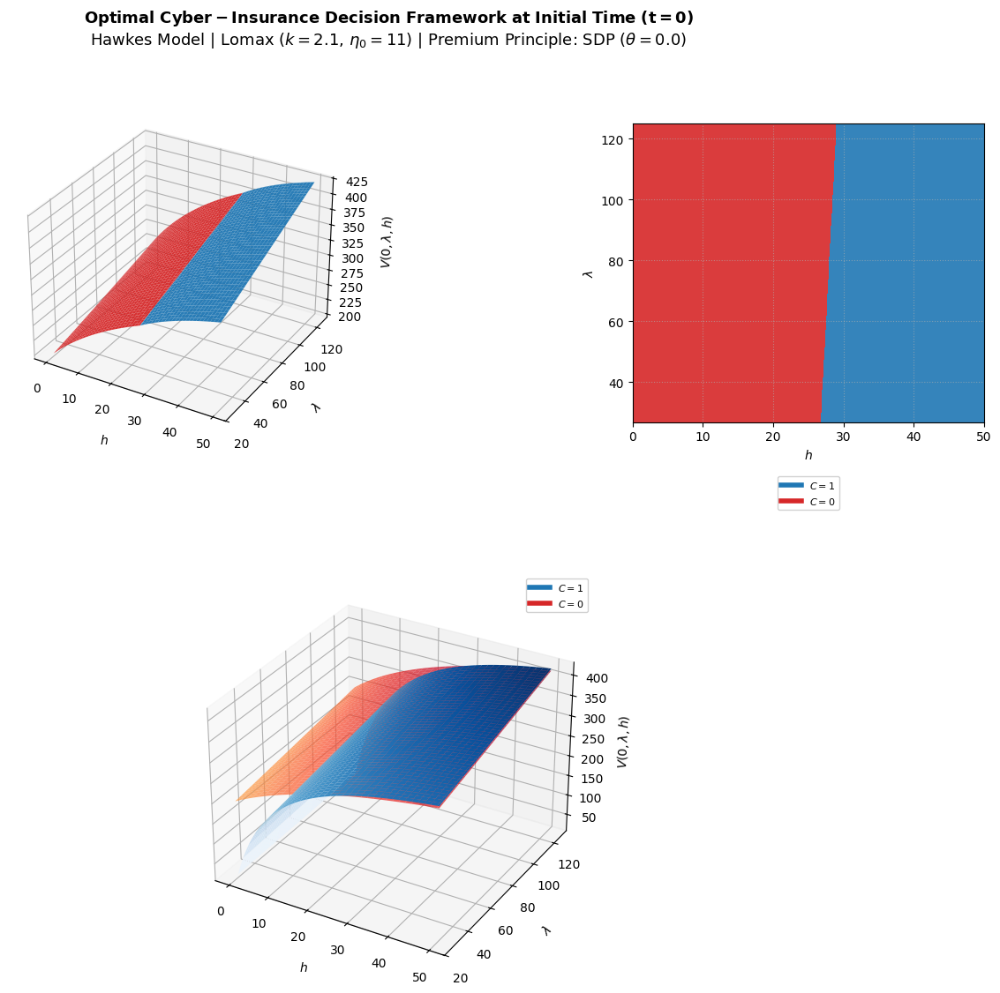

In [52]:
names =['comparison_sensivity_d_02_1', 'comparison_sensivity_d_02_2', 'comparison_sensivity_d_02_3']

_ = PL.initial_comparison_1_0_Hawkes(V0=V0_Lomax_I_Hawkes, dist_type="lomax", k=2.1, eta_0=11, d=0.20, Principle="SDP", 
                                     theta = 0.0, lambda_plot_max=125, save_names = names)

Saved: thesis_plots/comparison_sensivity_d_1_1.png
Saved: thesis_plots/comparison_sensivity_d_1_2.png
Saved: thesis_plots/comparison_sensivity_d_1_3.png


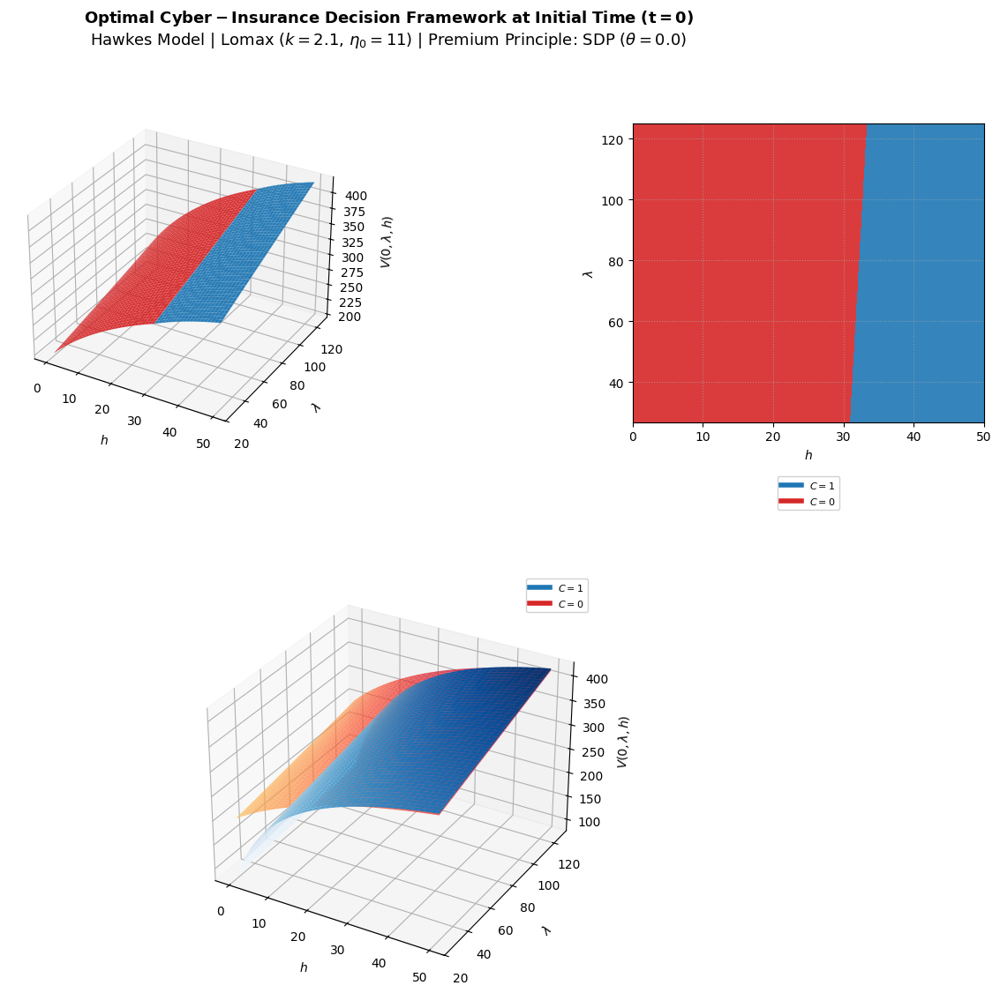

In [53]:
names =['comparison_sensivity_d_1_1', 'comparison_sensivity_d_1_2', 'comparison_sensivity_d_1_3']

_ = PL.initial_comparison_1_0_Hawkes(V0=V0_Lomax_I_Hawkes, dist_type="lomax", k=2.1, eta_0=11, d=1, Principle="SDP", 
                                     theta = 0.0, lambda_plot_max=125, save_names = names)

#### Sensitivity with respect to $\theta$

Saved: thesis_plots/comparison_sensivity_Lomax_theta_0025_1.png
Saved: thesis_plots/comparison_sensivity_Lomax_theta_0025_2.png
Saved: thesis_plots/comparison_sensivity_Lomax_theta_0025_3.png


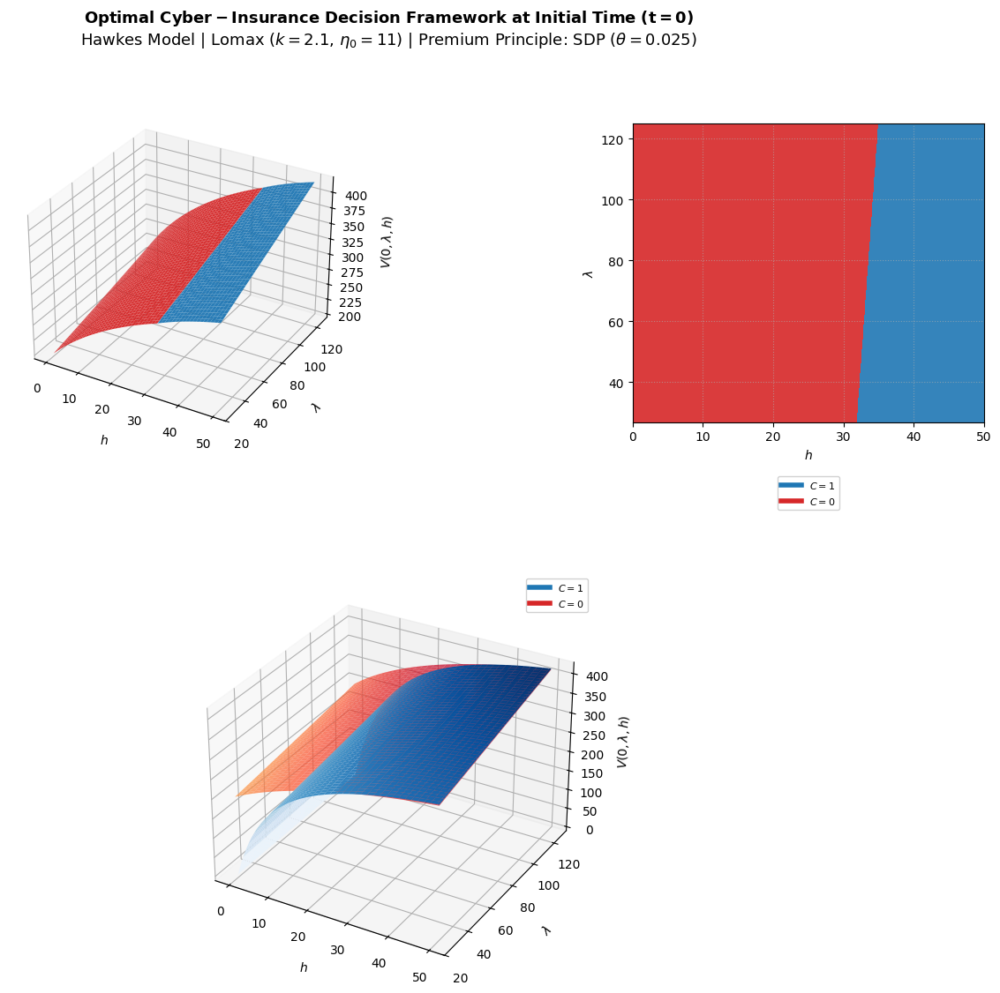

In [54]:
names =['comparison_sensivity_Lomax_theta_0025_1', 'comparison_sensivity_Lomax_theta_0025_2', 'comparison_sensivity_Lomax_theta_0025_3']

_ = PL.initial_comparison_1_0_Hawkes(
    V1=V1_Lomax_I_Hawkes, V0=V0_Lomax_I_Hawkes, dist_type="lomax", k=2.1, eta_0=11,
    d=0.1, Principle="SDP", theta = 0.025, lambda_plot_max=125, save_names = names
)

Saved: thesis_plots/comparison_sensivity_Lomax_theta_005_1.png
Saved: thesis_plots/comparison_sensivity_Lomax_theta_005_2.png
Saved: thesis_plots/comparison_sensivity_Lomax_theta_005_3.png


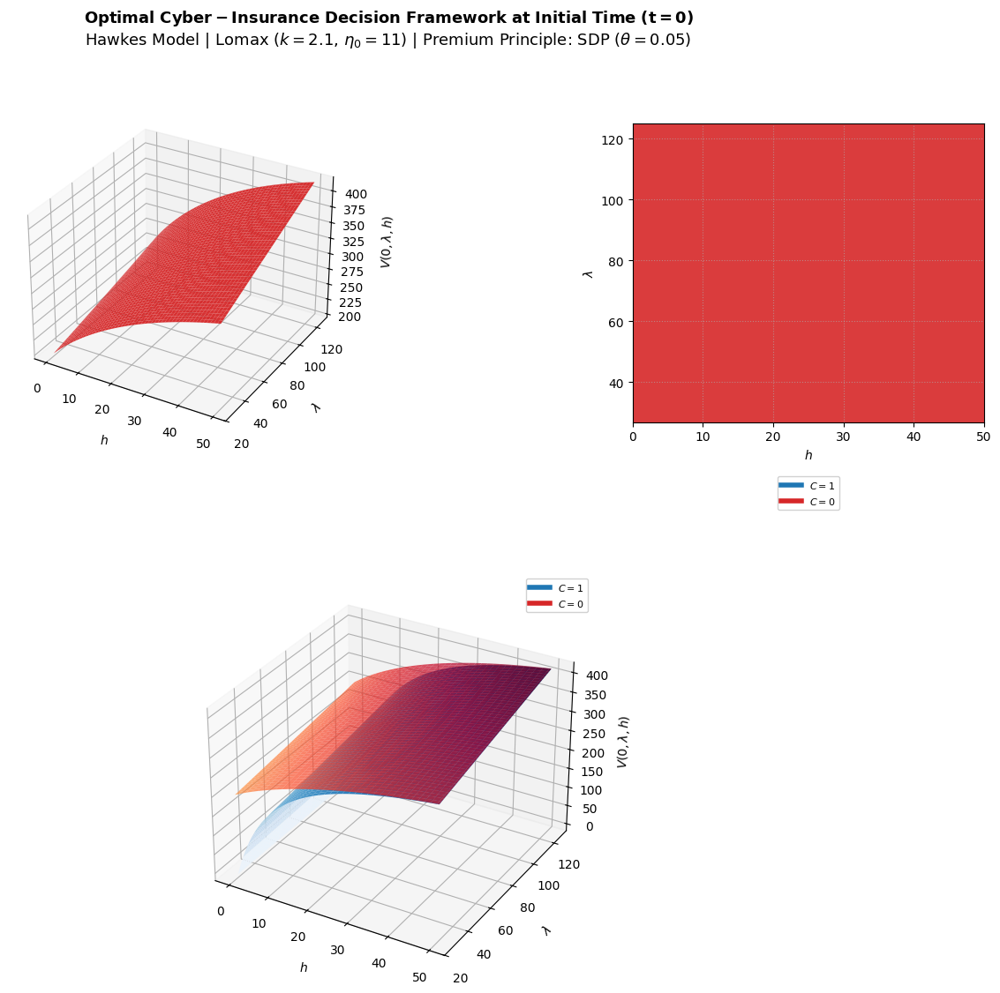

In [55]:
names =['comparison_sensivity_Lomax_theta_005_1', 'comparison_sensivity_Lomax_theta_005_2', 'comparison_sensivity_Lomax_theta_005_3']

_ = PL.initial_comparison_1_0_Hawkes(
    V1=V1_Lomax_I_Hawkes, V0=V0_Lomax_I_Hawkes, dist_type="lomax", k=2.1, eta_0=11,
    d=0.1, Principle="SDP", theta = 0.05, lambda_plot_max=125, save_names = names
)

Saved: thesis_plots/comparison_sensivity_Lognormal_theta_0025_1.png
Saved: thesis_plots/comparison_sensivity_Lognormal_theta_0025_2.png
Saved: thesis_plots/comparison_sensivity_Lognormal_theta_0025_3.png


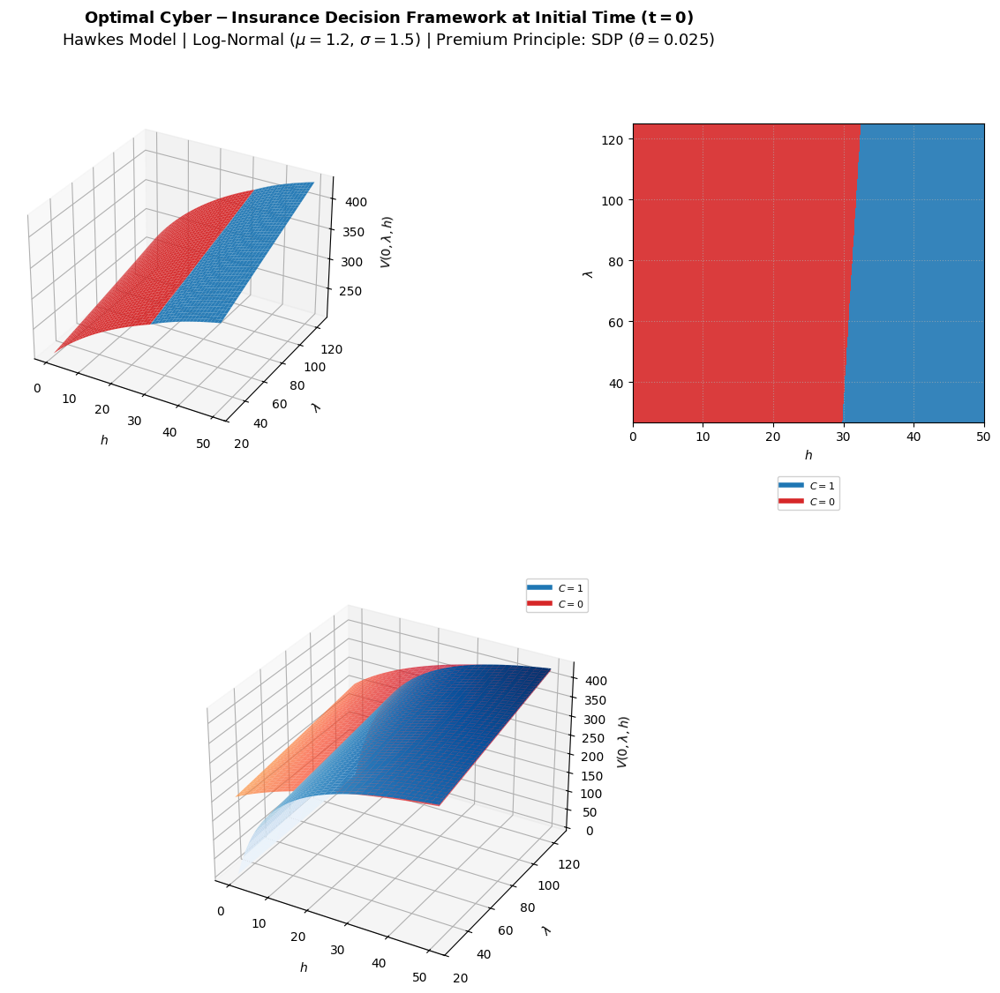

In [56]:
names =['comparison_sensivity_Lognormal_theta_0025_1', 'comparison_sensivity_Lognormal_theta_0025_2', 'comparison_sensivity_Lognormal_theta_0025_3']

_ = PL.initial_comparison_1_0_Hawkes(
    V1=V1_Lognormal_I_Hawkes, V0=V0_Lognormal_I_Hawkes, dist_type="lognormal", mu=1.2, sigma = 1.5,
    d=0.1, Principle="SDP", theta = 0.025, lambda_plot_max=125, save_names = names
)

Saved: thesis_plots/comparison_sensivity_Lognormal_theta_005_1.png
Saved: thesis_plots/comparison_sensivity_Lognormal_theta_005_2.png
Saved: thesis_plots/comparison_sensivity_Lognormal_theta_005_3.png


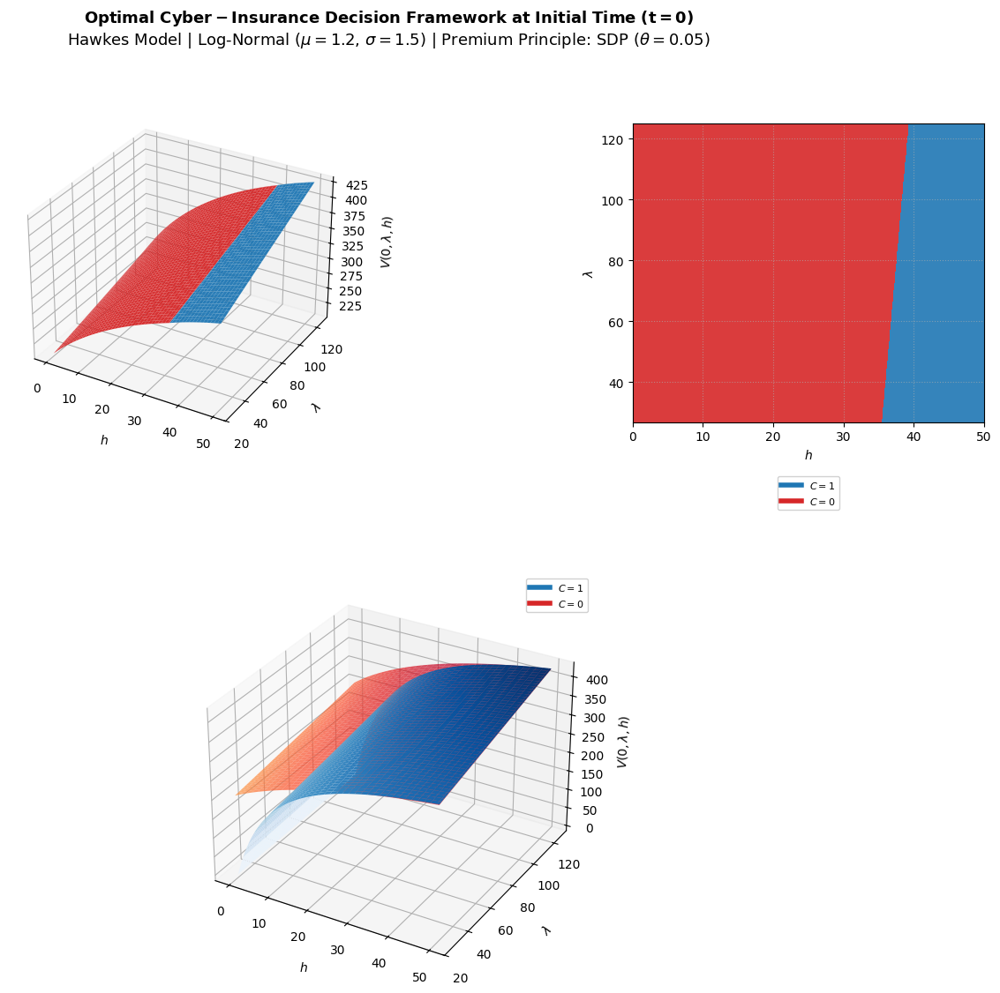

In [57]:
names =['comparison_sensivity_Lognormal_theta_005_1', 'comparison_sensivity_Lognormal_theta_005_2', 'comparison_sensivity_Lognormal_theta_005_3']

_ = PL.initial_comparison_1_0_Hawkes(
    V1=V1_Lognormal_I_Hawkes, V0=V0_Lognormal_I_Hawkes, dist_type="lognormal", mu=1.2, sigma = 1.5,
    d=0.1, Principle="SDP", theta = 0.05, lambda_plot_max=125, save_names = names
)

Saved: thesis_plots/comparison_sensivity_Lognormal_theta_0065_1.png
Saved: thesis_plots/comparison_sensivity_Lognormal_theta_0065_2.png
Saved: thesis_plots/comparison_sensivity_Lognormal_theta_0065_3.png


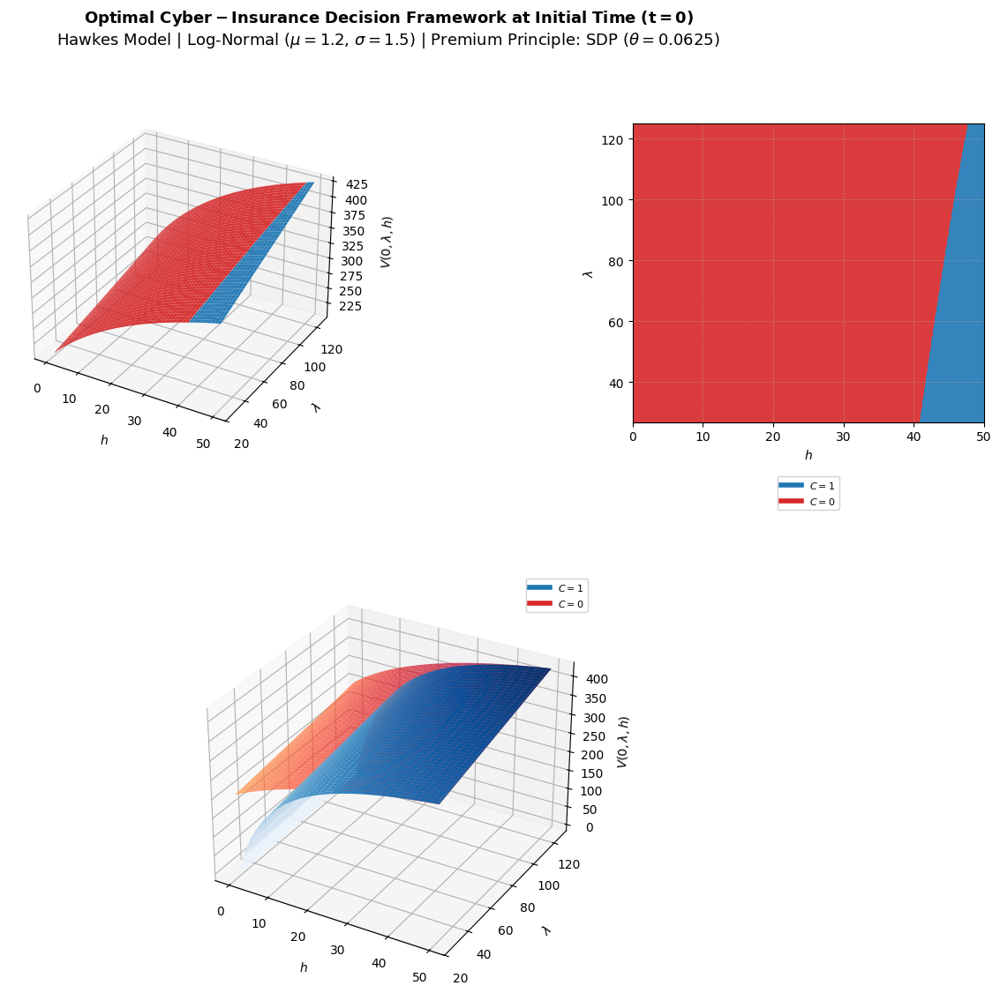

In [58]:
names =['comparison_sensivity_Lognormal_theta_0065_1', 'comparison_sensivity_Lognormal_theta_0065_2', 'comparison_sensivity_Lognormal_theta_0065_3']

_ = PL.initial_comparison_1_0_Hawkes(
    V1=V1_Lognormal_I_Hawkes, V0=V0_Lognormal_I_Hawkes, dist_type="lognormal", mu=1.2, sigma = 1.5,
    d=0.1, Principle="SDP", theta = 0.0625, lambda_plot_max=125, save_names = names
)

Saved: thesis_plots/comparison_sensivity_Lognormal_theta_0075_1.png
Saved: thesis_plots/comparison_sensivity_Lognormal_theta_0075_2.png
Saved: thesis_plots/comparison_sensivity_Lognormal_theta_0075_3.png


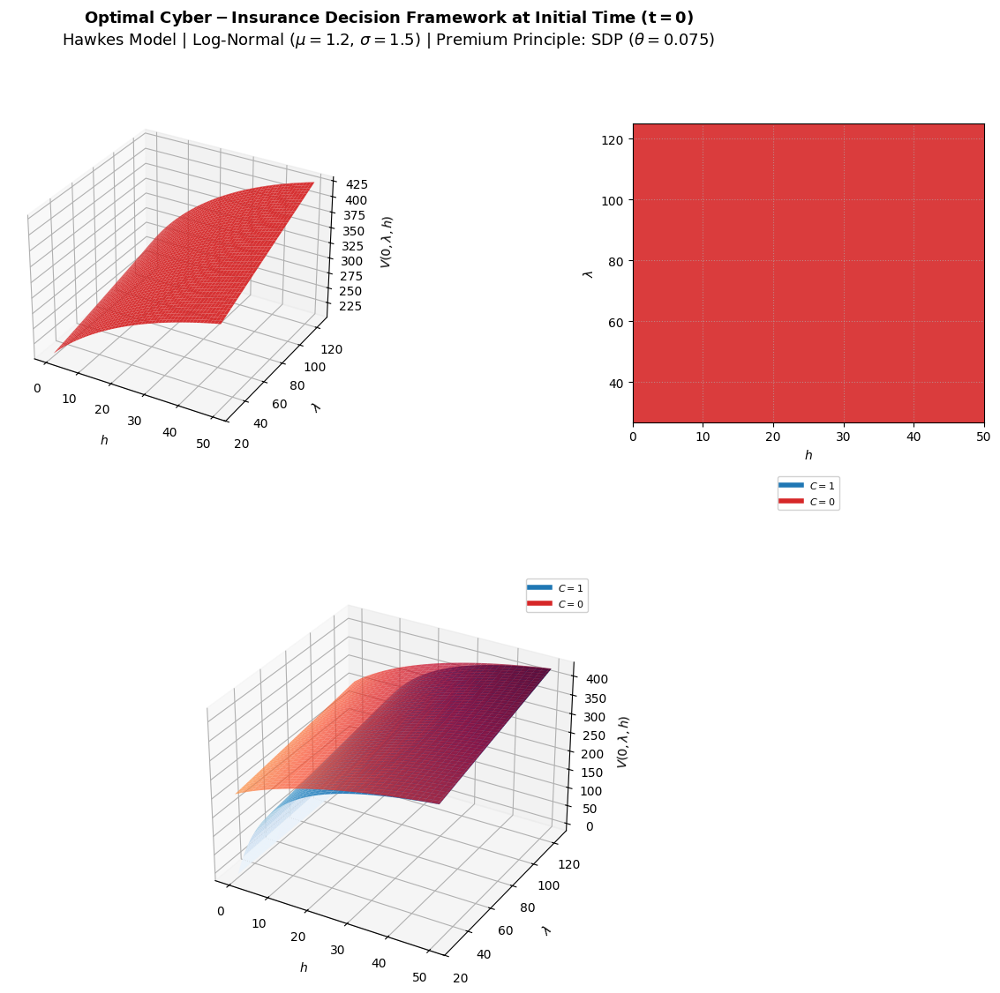

In [59]:
names =['comparison_sensivity_Lognormal_theta_0075_1', 'comparison_sensivity_Lognormal_theta_0075_2', 'comparison_sensivity_Lognormal_theta_0075_3']

_ = PL.initial_comparison_1_0_Hawkes(
    V1=V1_Lognormal_I_Hawkes, V0=V0_Lognormal_I_Hawkes, dist_type="lognormal", mu=1.2, sigma = 1.5,
    d=0.1, Principle="SDP", theta = 0.075, lambda_plot_max=125, save_names = names
)

# **Risk-Averse Framework**

## **Inner Control Problem**

Saved: thesis_plots/V09_Lomax_I_HawkesRA1.png
Saved: thesis_plots/V09_Lomax_I_HawkesRA2.png
Saved: thesis_plots/V09_Lomax_I_HawkesRA3.png


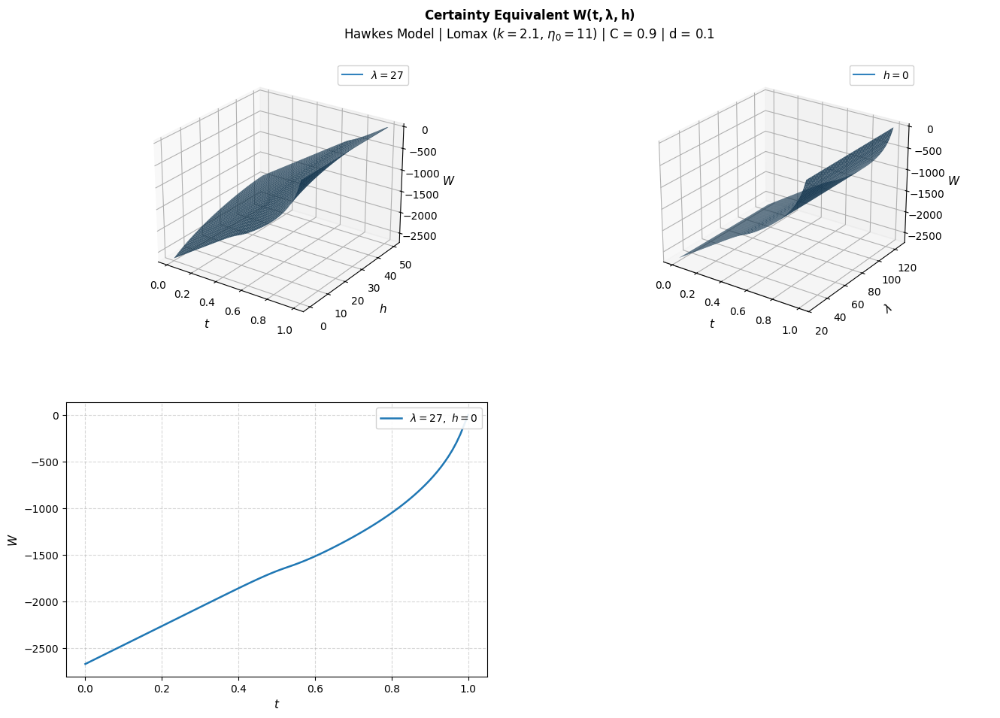

Saved: thesis_plots/z09_Lomax_I_HawkesRA1.png
Saved: thesis_plots/z09_Lomax_I_HawkesRA2.png
Saved: thesis_plots/z09_Lomax_I_HawkesRA3.png


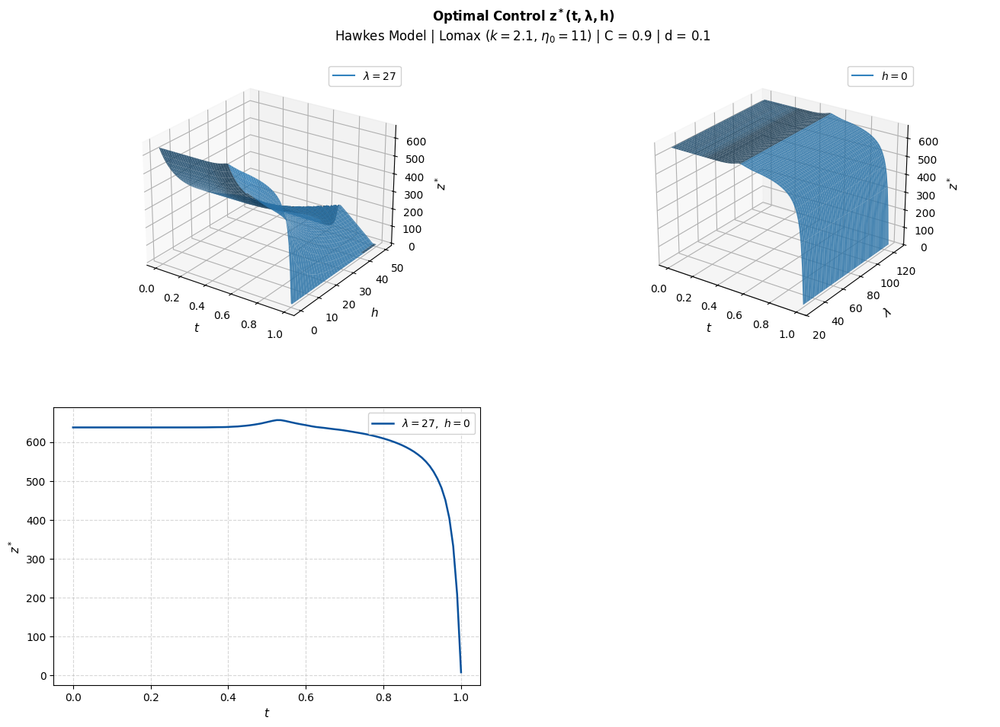

In [60]:
names_V=['V09_Lomax_I_HawkesRA1', 'V09_Lomax_I_HawkesRA2', 'V09_Lomax_I_HawkesRA3']
names_z=['z09_Lomax_I_HawkesRA1', 'z09_Lomax_I_HawkesRA2', 'z09_Lomax_I_HawkesRA3']

V09_Lomax_I_Hawkes_RA, _ = Hawkes_PIDE_solver_RA(dist_type="lomax", k=2.1, eta_0=11, d=0.1, r=75.0, omega=1, C =0.9)
z09_Lomax_I_Hawkes_RA = z_star(V09_Lomax_I_Hawkes_RA, d_lambda = 1, d_h = 0.5, gamma = 0.05)

_ = PL.plot_value_function(V09_Lomax_I_Hawkes_RA, lambda_fixed=27, h_fixed=0, context = 'RA',
                        dist_type="Lomax", k=2.1, eta_0=11, C=0.9, d=0.1, lambda_plot_max=125, save_names = names_V)
_ = PL.plot_optimal_control(V09_Lomax_I_Hawkes_RA, lambda_fixed=27, h_fixed=0,
                         dist_type="Lomax", k=2.1, eta_0=11, C=0.9, d=0.1, lambda_plot_max=125, save_names = names_z)

Saved: thesis_plots/V1_Lomax_I_HawkesRA1.png
Saved: thesis_plots/V1_Lomax_I_HawkesRA2.png
Saved: thesis_plots/V1_Lomax_I_HawkesRA3.png


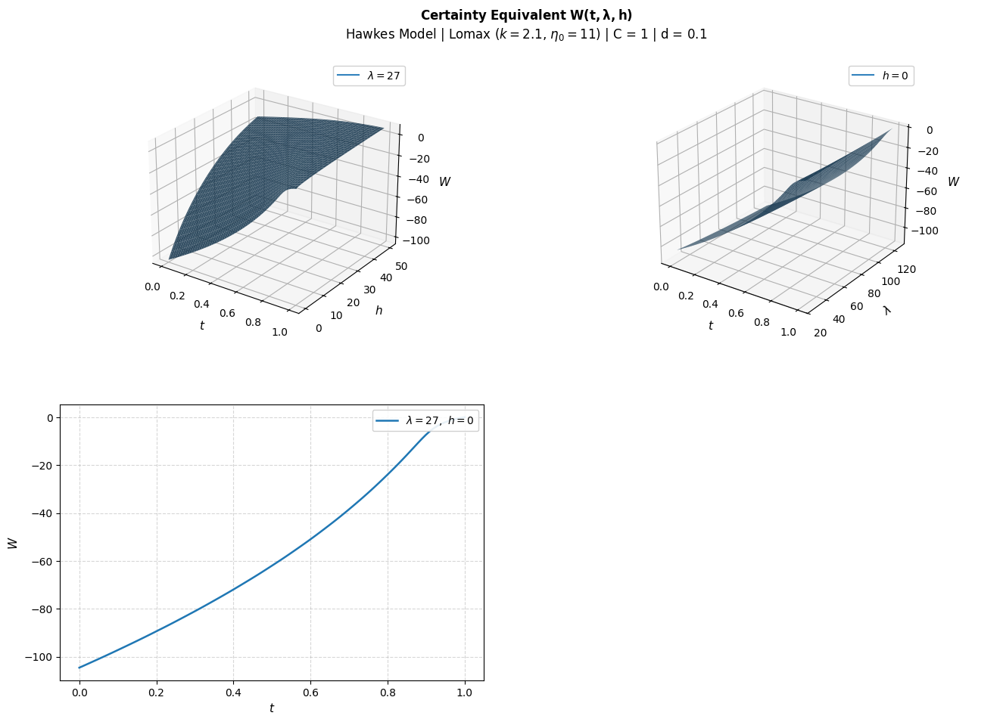

Saved: thesis_plots/z1_Lomax_I_HawkesRA1.png
Saved: thesis_plots/z1_Lomax_I_HawkesRA2.png
Saved: thesis_plots/z1_Lomax_I_HawkesRA3.png


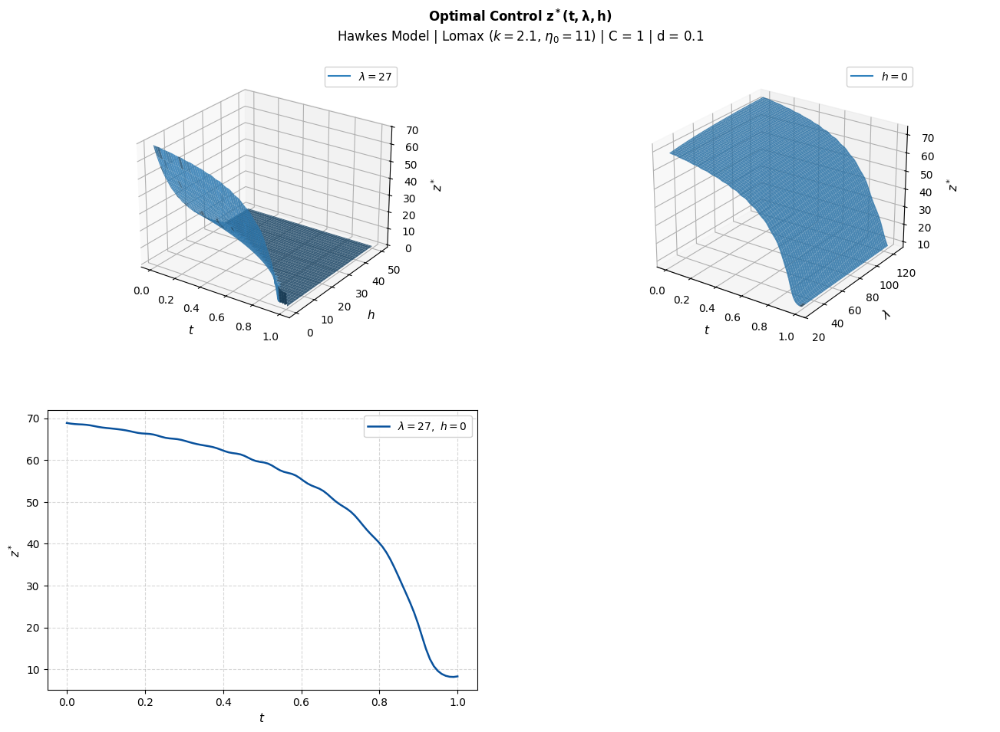

In [61]:
names_V=['V1_Lomax_I_HawkesRA1', 'V1_Lomax_I_HawkesRA2', 'V1_Lomax_I_HawkesRA3']
names_z=['z1_Lomax_I_HawkesRA1', 'z1_Lomax_I_HawkesRA2', 'z1_Lomax_I_HawkesRA3']

V1_Lomax_I_Hawkes_RA, _ = Hawkes_PIDE_solver_RA(dist_type="lomax", k=2.1, eta_0=11, d=0.1, r=75.0, omega=1, C = 1)
z1_Lomax_I_Hawkes_RA = z_star(V1_Lomax_I_Hawkes_RA, d_lambda = 1, d_h = 0.5, gamma = 0.05)

_ = PL.plot_value_function(V1_Lomax_I_Hawkes_RA, lambda_fixed=27, h_fixed=0, context = 'RA',
                        dist_type="Lomax", k=2.1, eta_0=11, C=1, d=0.1, lambda_plot_max=125, save_names = names_V)
_ = PL.plot_optimal_control(V1_Lomax_I_Hawkes_RA, lambda_fixed=27, h_fixed=0,
                         dist_type="Lomax", k=2.1, eta_0=11, C=1, d=0.1, lambda_plot_max=125, save_names = names_z)

Saved: thesis_plots/z_comparison_RA.png


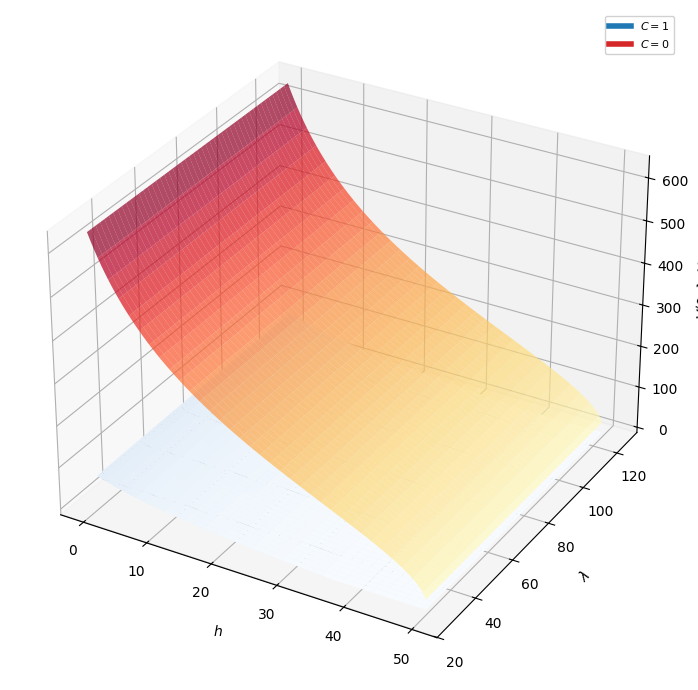

In [62]:
names =['z_comparison_RA']

# PL.initial_comparison_1_0_Hawkes is useful to compare between two different strategies in the grid lambda x h 
# at t = 0 when sub_Pre = False.

_ = PL.initial_comparison_1_0_Hawkes(
    V1=z1_Lomax_I_Hawkes_RA, V0=z09_Lomax_I_Hawkes_RA, dist_type="lomax", k=2.1, eta_0=11,lambda_plot_max=125, show_suptitle = False,
    d=0.1, Principle="SDP", theta = 0.0, save_names = names, panel = 'comparison_surface', sub_Pre=False,
)

### **Sensitivity analysis of the Value Function and the Optimal Control**

In [63]:
lambda_fixed = 27
h_fixed = 0

#### Sensitivity with respect to $\xi$

In [64]:
xi_grid = [15,25,35,45,50]

Solving V for xi=15 ...
Solving V for xi=25 ...
Solving V for xi=35 ...
Solving V for xi=45 ...
Solving V for xi=50 ...
Saved: thesis_plots/sensitivity090_xi_VRA.png
Saved: thesis_plots/sensitivity090_xi_zRA.png


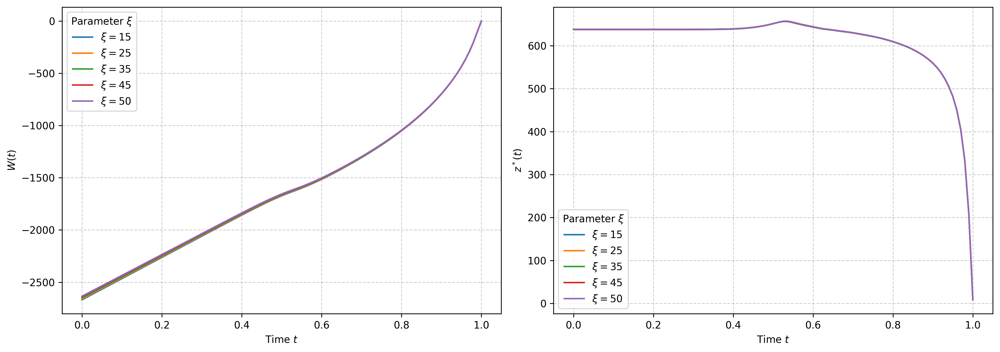

In [65]:
names = ['sensitivity090_xi_VRA', 'sensitivity090_xi_zRA']

fig, axes = PL.plot_parameter_sensitivityRA("xi", xi_grid, lambda_fixed=lambda_fixed, h_fixed=h_fixed,
                                        dist_type="lomax", k=2.1, eta_0=11, r = 75, d = 0.1, C =0.90, save_names = names)

Solving V for xi=15 ...
Solving V for xi=25 ...
Solving V for xi=35 ...
Solving V for xi=45 ...
Solving V for xi=50 ...
Saved: thesis_plots/sensitivity1_xi_VRA.png
Saved: thesis_plots/sensitivity1_xi_zRA.png


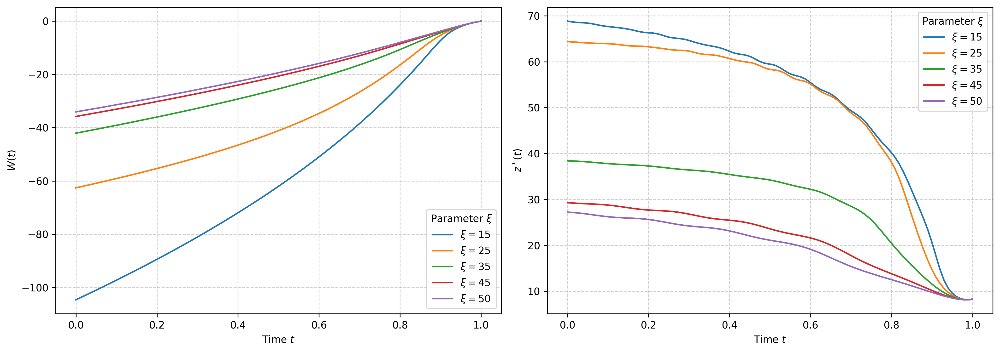

In [66]:
names = ['sensitivity1_xi_VRA', 'sensitivity1_xi_zRA']

fig, axes = PL.plot_parameter_sensitivityRA("xi", xi_grid, lambda_fixed=lambda_fixed, h_fixed=h_fixed,
                                        dist_type="lomax", k=2.1, eta_0=11, r = 75, d = 0.1, C =1, save_names = names)

#### Sensitivity with respect to $\rho$

In [67]:
rho_grid = [0,0.25,0.5,0.75,1]

Solving V for rho=0 ...
Solving V for rho=0.25 ...
Solving V for rho=0.5 ...
Solving V for rho=0.75 ...
Solving V for rho=1 ...
Saved: thesis_plots/sensitivity090_rho_VRA.png
Saved: thesis_plots/sensitivity090_rho_zRA.png


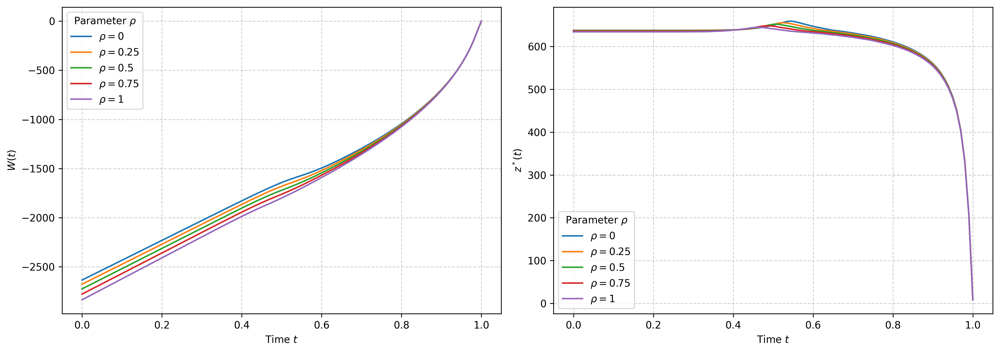

In [68]:
names = ['sensitivity090_rho_VRA', 'sensitivity090_rho_zRA']

fig, axes = PL.plot_parameter_sensitivityRA("rho", rho_grid, lambda_fixed=lambda_fixed, h_fixed=h_fixed,
                                        dist_type="lomax", k=2.1, eta_0=11, r = 75, d = 0.1, C =0.90, save_names = names)

Solving V for rho=0 ...
Solving V for rho=0.25 ...
Solving V for rho=0.5 ...
Solving V for rho=0.75 ...
Solving V for rho=1 ...
Saved: thesis_plots/sensitivity1_rho_VRA.png
Saved: thesis_plots/sensitivity1_rho_zRA.png


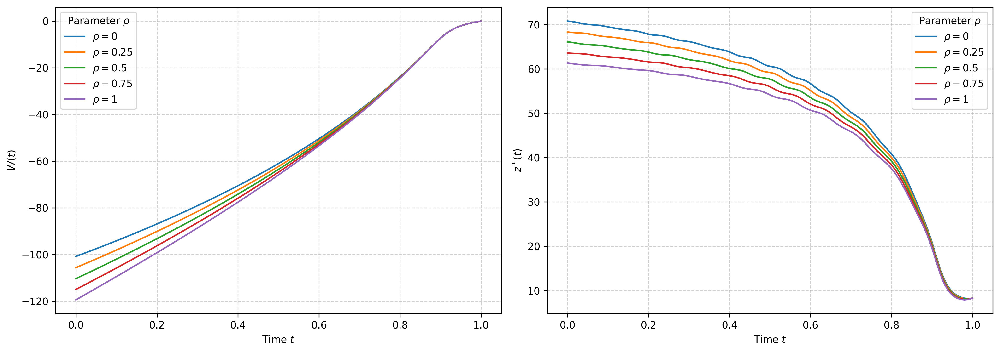

In [69]:
names = ['sensitivity1_rho_VRA', 'sensitivity1_rho_zRA']

fig, axes = PL.plot_parameter_sensitivityRA("rho", rho_grid, lambda_fixed=lambda_fixed, h_fixed=h_fixed,
                                        dist_type="lomax", k=2.1, eta_0=11, r = 75, d = 0.1, C =1, save_names = names)

#### Sensitivity with respect to $d$

In [70]:
d_grid = [0,0.05,0.10,0.15,0.2]

Solving V for d=0 ...
Solving V for d=0.05 ...
Solving V for d=0.1 ...
Solving V for d=0.15 ...
Solving V for d=0.2 ...
Saved: thesis_plots/sensitivity090_d_VRA.png
Saved: thesis_plots/sensitivity090_d_zRA.png


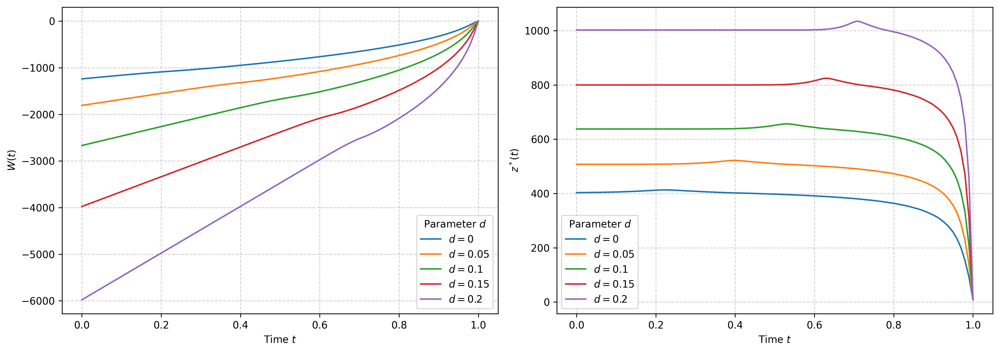

In [71]:
names = ['sensitivity090_d_VRA', 'sensitivity090_d_zRA']

fig, axes = PL.plot_parameter_sensitivityRA("d", d_grid, lambda_fixed=lambda_fixed, h_fixed=h_fixed,
                                        dist_type="lomax", k=2.1, eta_0=11, C =0.90, r = 75, save_names = names)

Solving V for d=0 ...
Solving V for d=0.05 ...
Solving V for d=0.1 ...
Solving V for d=0.15 ...
Solving V for d=0.2 ...
Saved: thesis_plots/sensitivity1_d_VRA.png
Saved: thesis_plots/sensitivity1_d_zRA.png


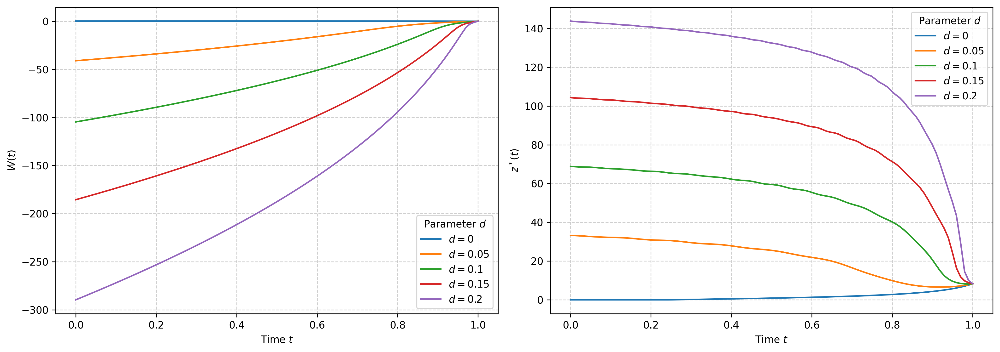

In [72]:
names = ['sensitivity1_d_VRA', 'sensitivity1_d_zRA']

fig, axes = PL.plot_parameter_sensitivityRA("d", d_grid, lambda_fixed=lambda_fixed, h_fixed=h_fixed,
                                        dist_type="lomax", k=2.1, eta_0=11, C =1, r = 75, save_names = names)

#### Sensitivity with respect to $r$

In [73]:
r_grid = [20,40,60,80,100]

Solving V for r=20 ...
Solving V for r=40 ...
Solving V for r=60 ...
Solving V for r=80 ...
Solving V for r=100 ...
Saved: thesis_plots/sensitivity090_r_VRA.png
Saved: thesis_plots/sensitivity090_r_zRA.png


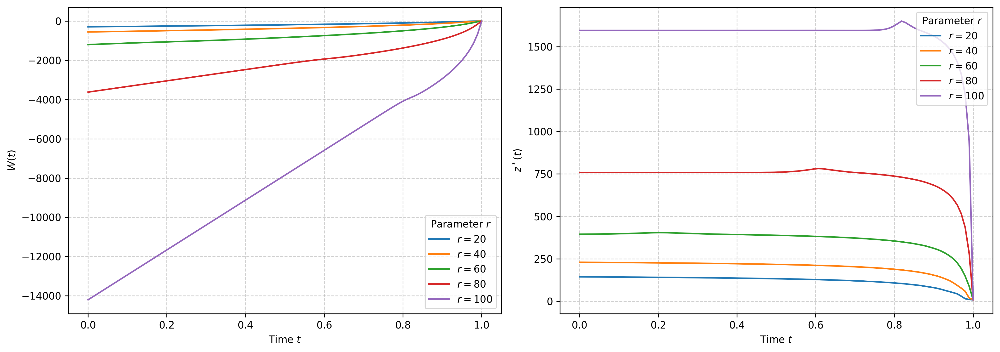

In [74]:
names = ['sensitivity090_r_VRA', 'sensitivity090_r_zRA']

fig, axes = PL.plot_parameter_sensitivityRA("r", r_grid, lambda_fixed=lambda_fixed, h_fixed=h_fixed,
                                        dist_type="lomax", k=2.1, eta_0=11, C =0.90, d = 0.1, save_names = names)

#### Sensitivity with respect to $\omega$

In [75]:
omega_grid = [0.1,0.01,0.001]

Solving V for omega=0.1 ...
Solving V for omega=0.01 ...
Solving V for omega=0.001 ...
Saved: thesis_plots/sensitivity090_omega_VRA.png
Saved: thesis_plots/sensitivity090_omega_zRA.png


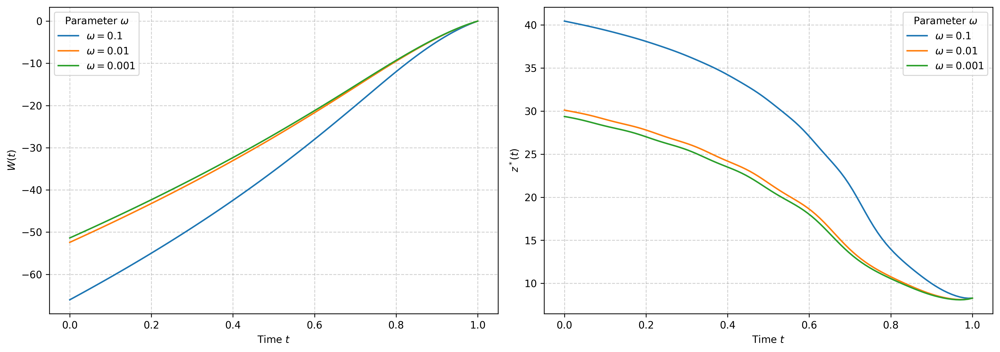

In [76]:
names = ['sensitivity090_omega_VRA', 'sensitivity090_omega_zRA']

fig, axes = PL.plot_parameter_sensitivityRA("omega", omega_grid, lambda_fixed=lambda_fixed, h_fixed=h_fixed,
                                        dist_type="lomax", k=2.1, eta_0=11, C =0.9, d = 0.1, r = 75, save_names = names)

Solving V for omega=0.1 ...
Solving V for omega=0.01 ...
Solving V for omega=0.001 ...
Saved: thesis_plots/sensitivity1_omega_VRA.png
Saved: thesis_plots/sensitivity1_omega_zRA.png


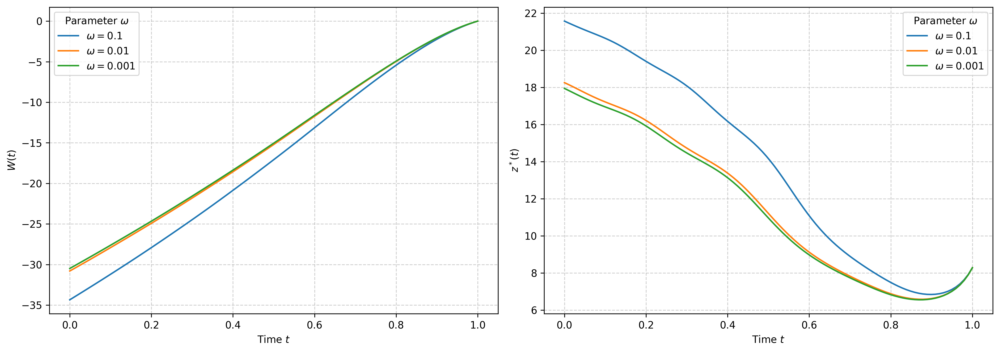

In [77]:
names = ['sensitivity1_omega_VRA', 'sensitivity1_omega_zRA']

fig, axes = PL.plot_parameter_sensitivityRA("omega", omega_grid, lambda_fixed=lambda_fixed, h_fixed=h_fixed,
                                        dist_type="lomax", k=2.1, eta_0=11, C =1, d = 0.1, r = 75, save_names = names)

### **Risk-Averse Convergence $\omega \to 0$**

In [78]:
V1_Lomax_I_Hawkes_RA_omega0001, _ = Hawkes_PIDE_solver_RA(dist_type="lomax", k=2.1, eta_0=11, d=0.1, r=75.0, omega=0.005, C =1)
z1_Lomax_I_Hawkes_RA_omega0001 = z_star(V1_Lomax_I_Hawkes_RA_omega0001, d_lambda = 1, d_h = 0.5, gamma = 0.05)

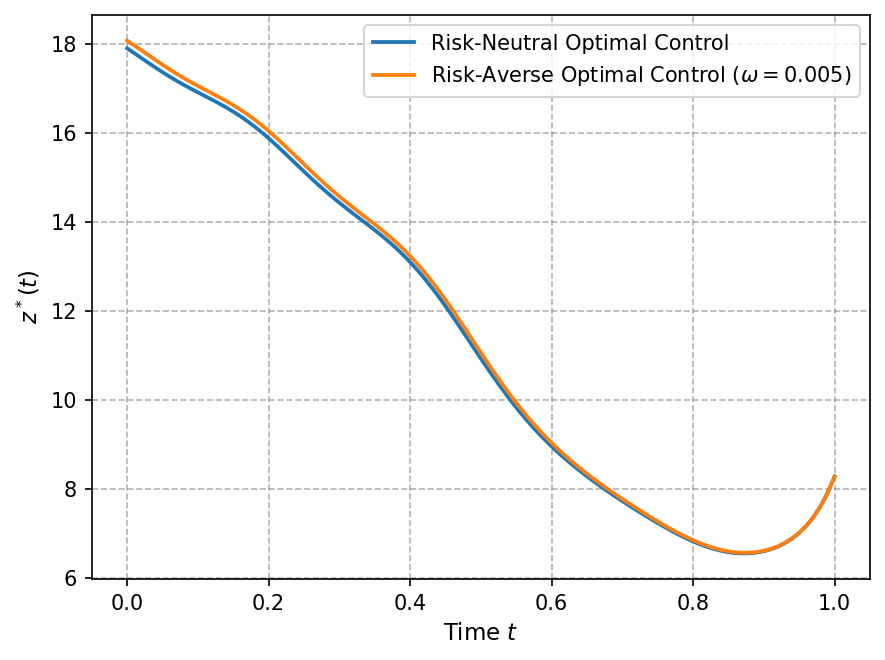

In [79]:
t = _[2]

data = {
    r"Risk-Neutral Optimal Control": z1_Lomax_I_Hawkes[0,0,::1],
    r"Risk-Averse Optimal Control $(\omega = 0.005)$": z1_Lomax_I_Hawkes_RA_omega0001[0,0,::1]
}

fig, ax = plt.subplots(figsize=(6, 4.5), dpi=150)
for label, z_t in data.items():
    ax.plot(t, z_t, label=label, linewidth=1.8)

ax.set_xlabel("Time $t$", fontsize=11)
ax.set_ylabel("$z^*(t)$", fontsize=11)

ax.grid(True, linestyle="--", alpha=0.6, color="gray")
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.savefig('RA_Convergence', dpi=300, bbox_inches='tight')
plt.show()

### **Gain against static z = 0 investment strategy**

Saved: thesis_plots/GainRA090.png


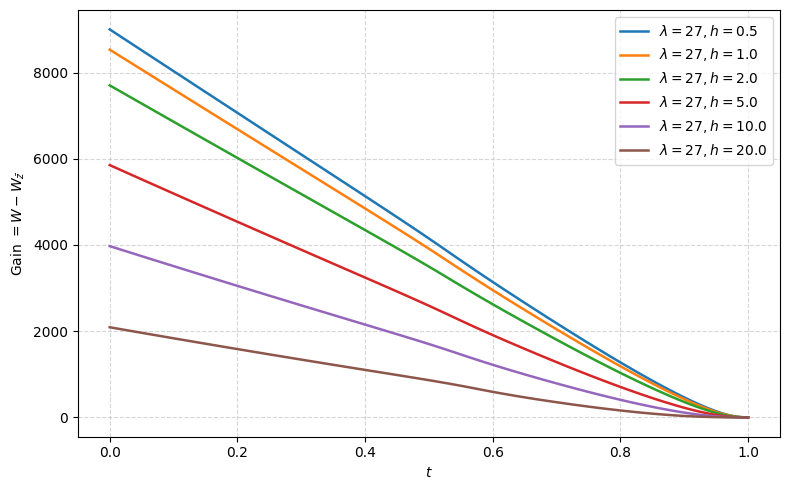

In [80]:
W_0strat_090, _ = solve_W_zbar_RA(z_bar=0.0, dist_type="lomax", k=2.1, eta_0=11, d=0.1, r=75.0, omega=1, C =0.9)

gains, t_eval = PL.compute_dynamic_vs_zbar_gain_RA(
    V09_Lomax_I_Hawkes_RA, W_0strat_090, dist_type="lomax", k=2.1, eta_0=11, C=0.9,
    lambda_fixed=27.0, h_targets=(0.5, 1.0, 2.0, 5.0, 10.0, 20.0), save_name = 'GainRA090'
)

Saved: thesis_plots/GainRA1.png


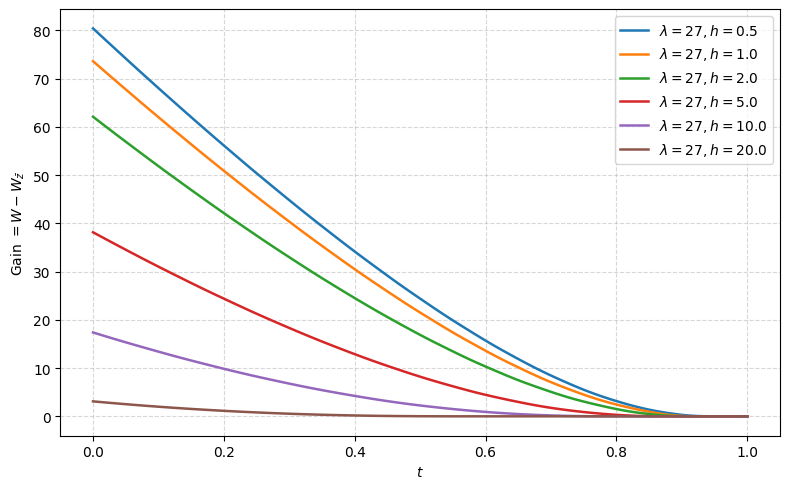

In [81]:
W_0strat_1, _ = solve_W_zbar_RA(z_bar=0.0, dist_type="lomax", k=2.1, eta_0=11, d=0.1, r=75.0, omega=1, C =1)

gains, t_eval = PL.compute_dynamic_vs_zbar_gain_RA(
    V1_Lomax_I_Hawkes_RA, W_0strat_1, dist_type="lomax", k=2.1, eta_0=11, C=1,
    lambda_fixed=27.0, h_targets=(0.5, 1.0, 2.0, 5.0, 10.0, 20.0), save_name = 'GainRA1'
)

### **Comparison with the Poisson Process Benchmark**

#### $\lambda = 27$

Saved: thesis_plots/Poisson_comparison_RA_09_27_1.png
Saved: thesis_plots/Poisson_comparison_RA_09_27_2.png
Saved: thesis_plots/Poisson_comparison_RA_09_27_3.png


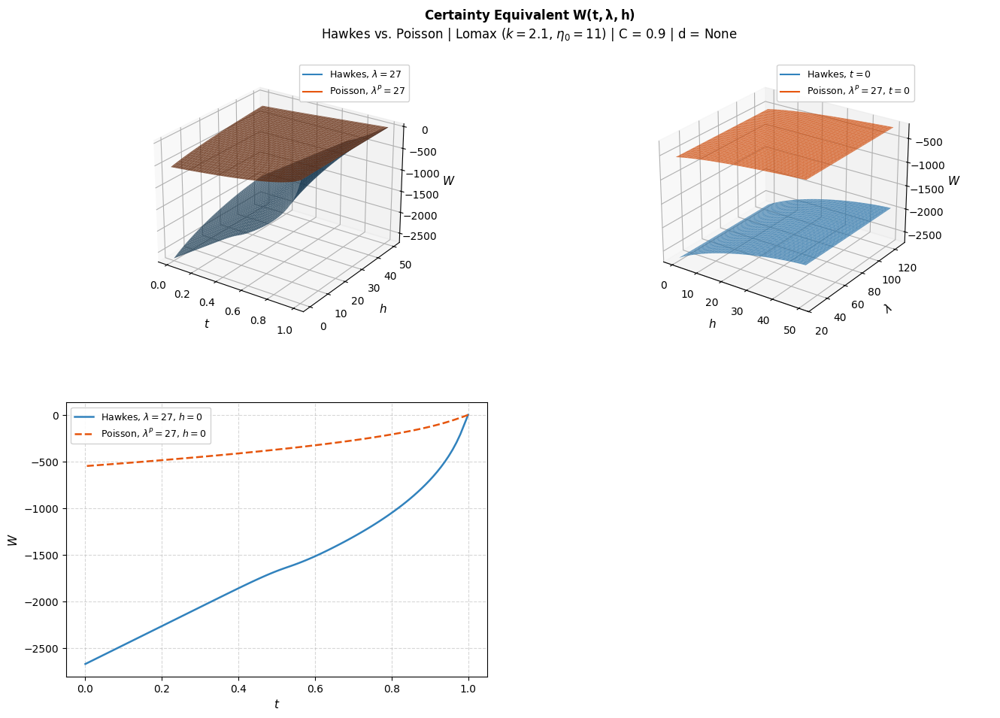

Saved: thesis_plots/Poisson_z_comparison_RA_09_27_1.png
Saved: thesis_plots/Poisson_z_comparison_RA_09_27_2.png
Saved: thesis_plots/Poisson_z_comparison_RA_09_27_3.png


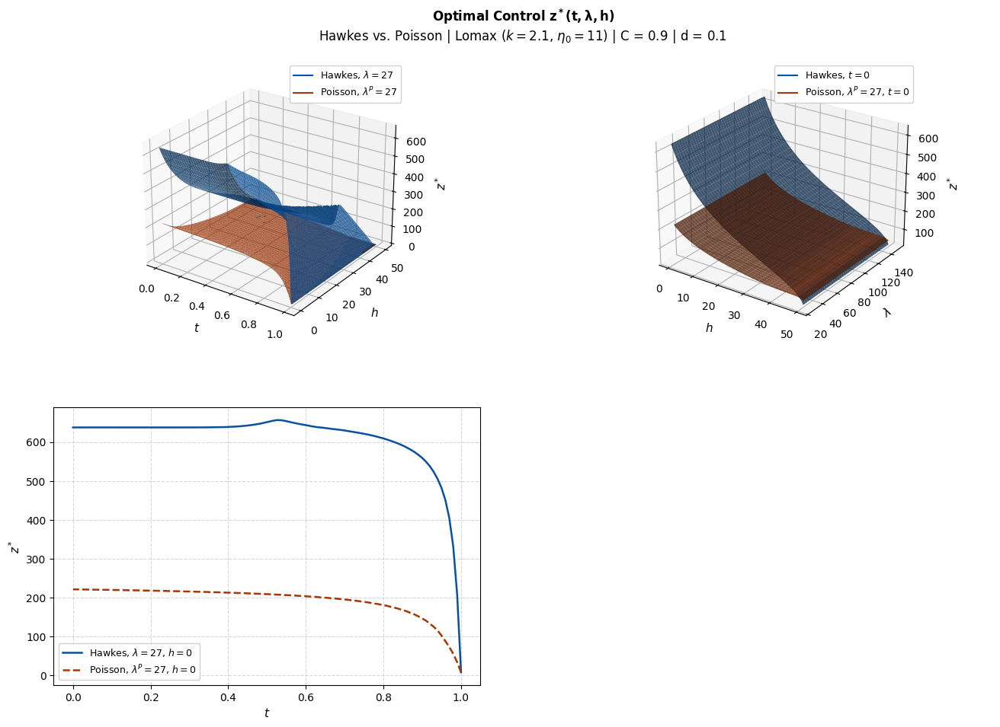

In [82]:
names_W = ['Poisson_comparison_RA_09_27_1','Poisson_comparison_RA_09_27_2','Poisson_comparison_RA_09_27_3']
names_z = ['Poisson_z_comparison_RA_09_27_1','Poisson_z_comparison_RA_09_27_2','Poisson_z_comparison_RA_09_27_3']

Poisson_RA090_27, _ = Hawkes_PIDE_solver_RA(dist_type="lomax", k=2.1, eta_0=11, d=0.1, r=75.0, omega=1, C =0.9, 
                                                lambda_min = 27, lambda_max = 27,beta = 0)

PL.plot_value_function_vs_poisson(V09_Lomax_I_Hawkes_RA, Poisson_RA090_27[0,:,:], lambda_fixed=27, h_fixed=0, t_fixed=0.0, context = 'RA',
                                dist_type='Lomax', k=2.1, eta_0=11, C=0.9, lambda_plot_max=125, save_names = names_W)

z09_Lomax_I_Hawkes, z09_mat_poisson27 = PL.plot_optimal_control_vs_poisson(
    V09_Lomax_I_Hawkes_RA, Poisson_RA090_27[0,:,:], gamma=0.05,
    lambda_fixed=27, h_fixed=0, t_fixed=0.0,
    dist_type='Lomax', k=2.1, eta_0=11, C=0.9, d = 0.1, save_names = names_z
)

Saved: thesis_plots/Poisson_comparison_RA_1_27_1.png
Saved: thesis_plots/Poisson_comparison_RA_1_27_2.png
Saved: thesis_plots/Poisson_comparison_RA_1_27_3.png


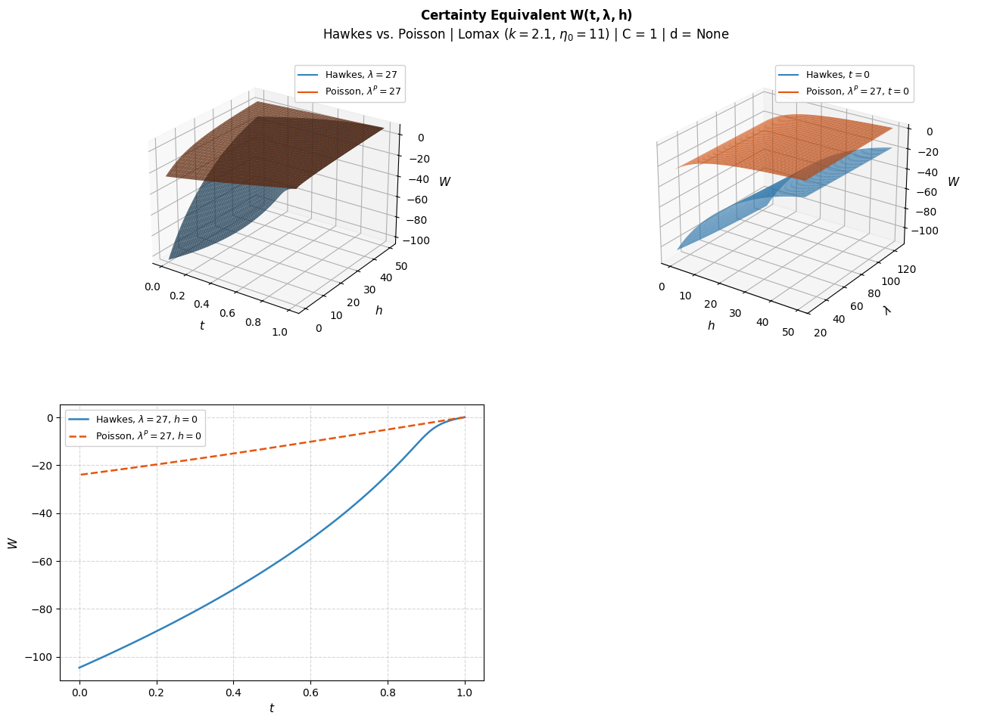

Saved: thesis_plots/Poisson_z_comparison_RA_1_27_1.png
Saved: thesis_plots/Poisson_z_comparison_RA_1_27_2.png
Saved: thesis_plots/Poisson_z_comparison_RA_1_27_3.png


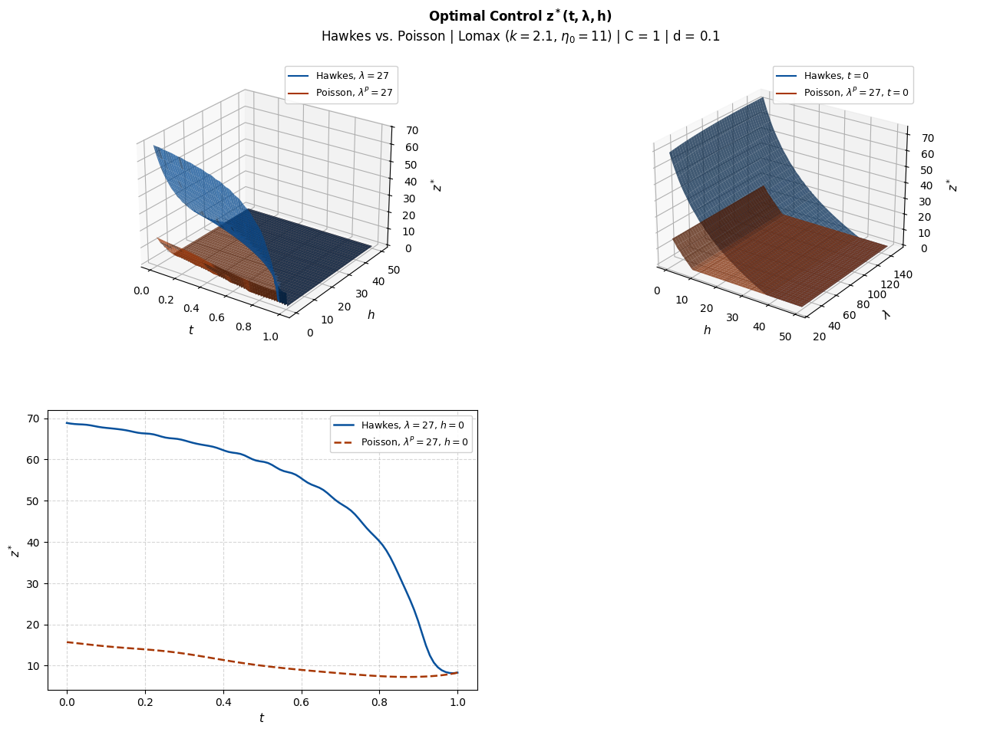

In [83]:
names_W = ['Poisson_comparison_RA_1_27_1','Poisson_comparison_RA_1_27_2','Poisson_comparison_RA_1_27_3']
names_z = ['Poisson_z_comparison_RA_1_27_1','Poisson_z_comparison_RA_1_27_2','Poisson_z_comparison_RA_1_27_3']

Poisson_RA1_27, _ = Hawkes_PIDE_solver_RA(dist_type="lomax", k=2.1, eta_0=11, d=0.1, r=75.0, omega=1, C =1, 
                                                lambda_min = 27, lambda_max = 27,beta = 0)

PL.plot_value_function_vs_poisson(V1_Lomax_I_Hawkes_RA, Poisson_RA1_27[0,:,:], lambda_fixed=27, h_fixed=0, t_fixed=0.0, context = 'RA',
                                dist_type='Lomax', k=2.1, eta_0=11, C=1, lambda_plot_max=125, save_names = names_W)

z1_Lomax_I_Hawkes, z1_mat_poisson27 = PL.plot_optimal_control_vs_poisson(
    V1_Lomax_I_Hawkes_RA, Poisson_RA1_27[0,:,:], gamma=0.05,
    lambda_fixed=27, h_fixed=0, t_fixed=0.0,
    dist_type='Lomax', k=2.1, eta_0=11, C=1, d = 0.1, save_names = names_z
)

#### $\lambda = 61$

Saved: thesis_plots/Poisson_comparison_RA_09_61_1.png
Saved: thesis_plots/Poisson_comparison_RA_09_61_2.png
Saved: thesis_plots/Poisson_comparison_RA_09_61_3.png


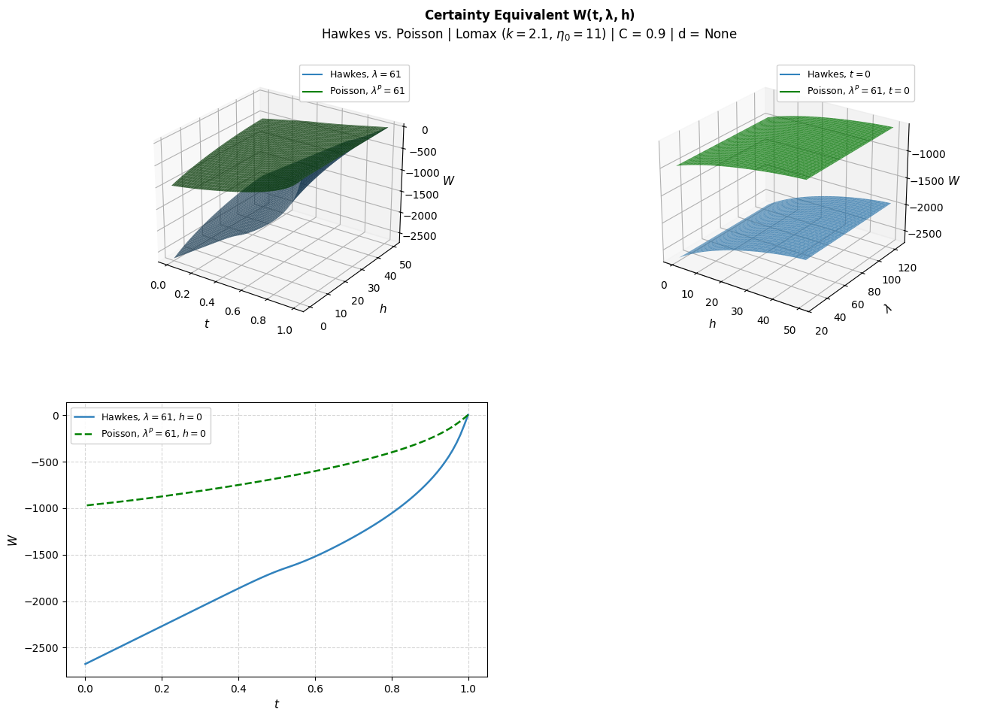

Saved: thesis_plots/Poisson_z_comparison_RA_09_61_1.png
Saved: thesis_plots/Poisson_z_comparison_RA_09_61_2.png
Saved: thesis_plots/Poisson_z_comparison_RA_09_61_3.png


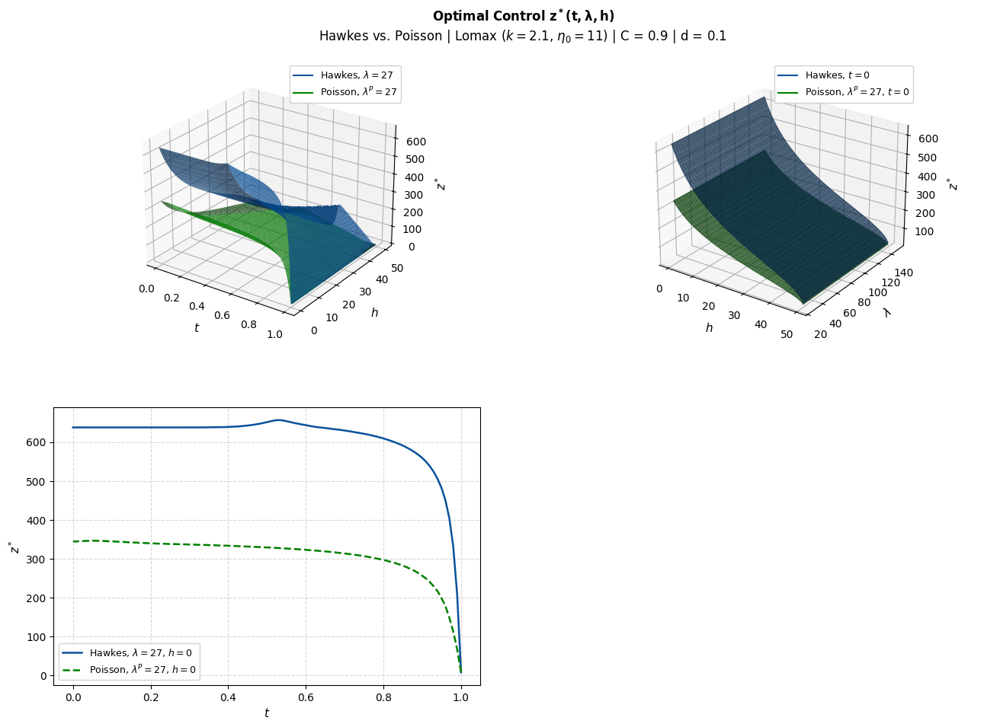

In [84]:
names_W = ['Poisson_comparison_RA_09_61_1','Poisson_comparison_RA_09_61_2','Poisson_comparison_RA_09_61_3']
names_z = ['Poisson_z_comparison_RA_09_61_1','Poisson_z_comparison_RA_09_61_2','Poisson_z_comparison_RA_09_61_3']

Poisson_RA090_61, _ = Hawkes_PIDE_solver_RA(dist_type="lomax", k=2.1, eta_0=11, d=0.1, r=75.0, omega=1, C =0.9, 
                                                lambda_min = 61, lambda_max = 61, beta = 0)

PL.plot_value_function_vs_poisson(V09_Lomax_I_Hawkes_RA, Poisson_RA090_61[0,:,:], lambda_fixed=61, h_fixed=0, t_fixed=0.0, context = 'RA',
                                dist_type='Lomax', k=2.1, eta_0=11, C=0.9, lambda_plot_max=125, poisson_color="green", save_names = names_W)

z09_Lomax_I_Hawkes, z09_mat_poisson61 = PL.plot_optimal_control_vs_poisson(
    V09_Lomax_I_Hawkes_RA, Poisson_RA090_61[0,:,:], gamma=0.05,
    lambda_fixed=27, h_fixed=0, t_fixed=0.0,
    dist_type='Lomax', k=2.1, eta_0=11, C=0.9, d = 0.1, poisson_color="green", save_names = names_z
)

Saved: thesis_plots/Poisson_comparison_RA_1_61_1.png
Saved: thesis_plots/Poisson_comparison_RA_1_61_2.png
Saved: thesis_plots/Poisson_comparison_RA_1_61_3.png


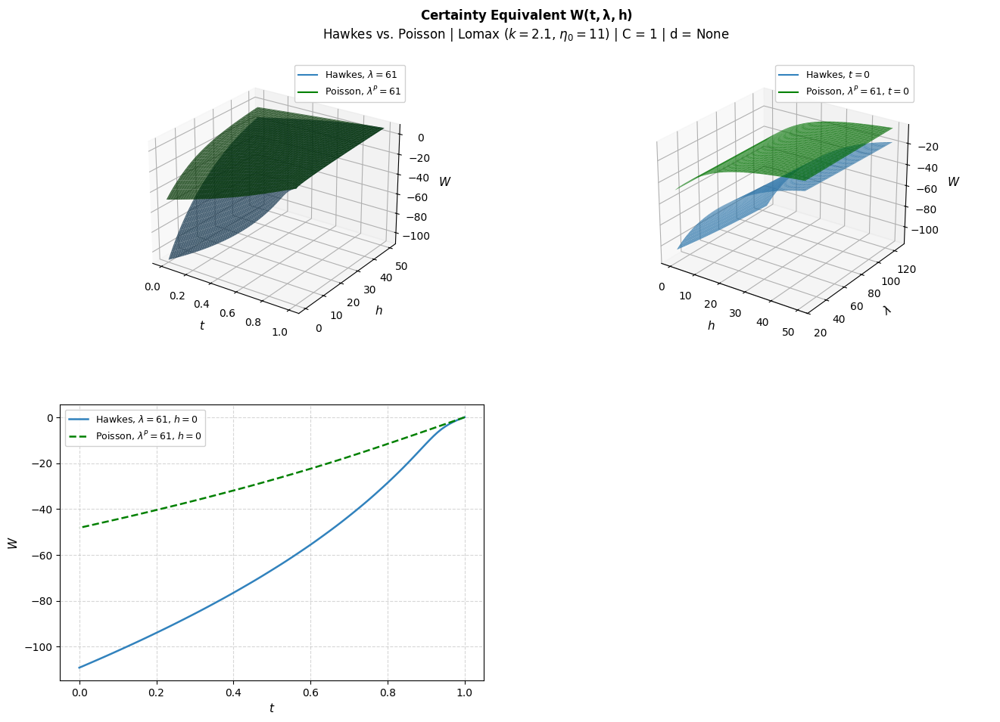

Saved: thesis_plots/Poisson_z_comparison_RA_1_61_1.png
Saved: thesis_plots/Poisson_z_comparison_RA_1_61_2.png
Saved: thesis_plots/Poisson_z_comparison_RA_1_61_3.png


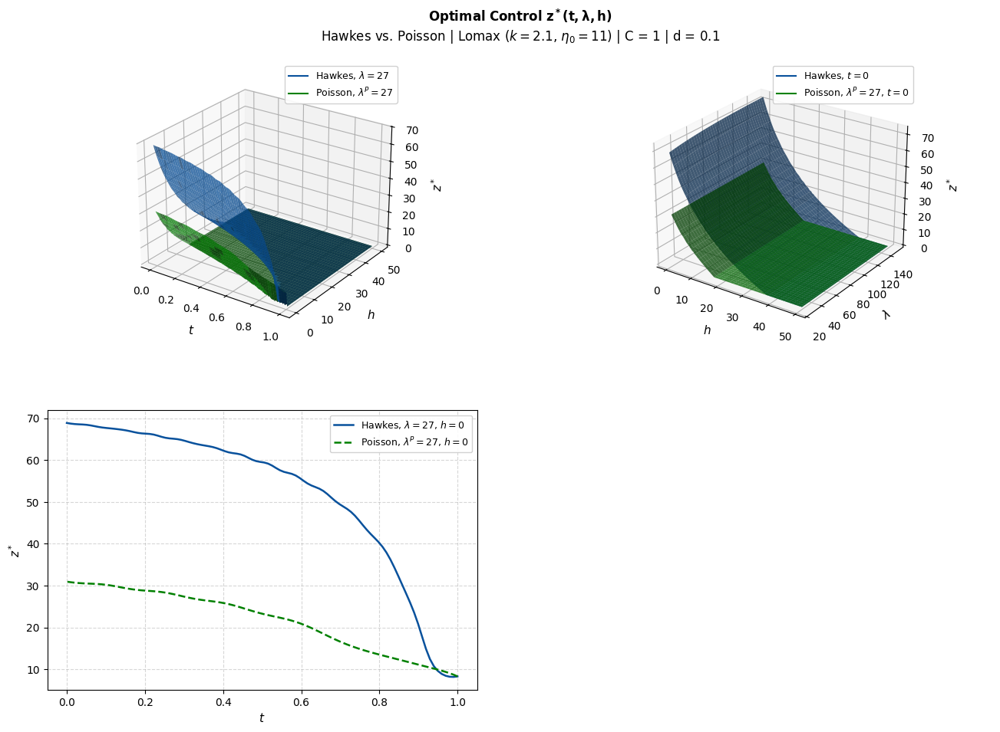

In [85]:
names_W = ['Poisson_comparison_RA_1_61_1','Poisson_comparison_RA_1_61_2','Poisson_comparison_RA_1_61_3']
names_z = ['Poisson_z_comparison_RA_1_61_1','Poisson_z_comparison_RA_1_61_2','Poisson_z_comparison_RA_1_61_3']

Poisson_RA1_61, _ = Hawkes_PIDE_solver_RA(dist_type="lomax", k=2.1, eta_0=11, d=0.1, r=75.0, omega=1, C =1, 
                                                lambda_min = 61, lambda_max = 61, beta = 0)

PL.plot_value_function_vs_poisson(V1_Lomax_I_Hawkes_RA, Poisson_RA1_61[0,:,:], lambda_fixed=61, h_fixed=0, t_fixed=0.0, context = 'RA',
                                dist_type='Lomax', k=2.1, eta_0=11, C=1, poisson_color="green", lambda_plot_max=125, save_names = names_W)

z1_Lomax_I_Hawkes, z1_mat_poisson61 = PL.plot_optimal_control_vs_poisson(
    V1_Lomax_I_Hawkes_RA, Poisson_RA1_61[0,:,:], gamma=0.05,
    lambda_fixed=27, h_fixed=0, t_fixed=0.0,
    dist_type='Lomax', k=2.1, eta_0=11, C=1, d = 0.1, poisson_color="green", save_names = names_z
)

## **Global Optimization Problem**

### **Decision Boundary $C^* \in [0,1]$**

In [86]:
C_GRID = [0.75, 0.775, 0.8, 0.825, 0.85, 0.875, 0.9, 0.925, 0.95, 0.975, 1]

Solving W for C=0.75 ...
Solving W for C=0.775 ...
Solving W for C=0.8 ...
Solving W for C=0.825 ...
Solving W for C=0.85 ...
Solving W for C=0.875 ...
Solving W for C=0.9 ...
Solving W for C=0.925 ...
Solving W for C=0.95 ...
Solving W for C=0.975 ...
Solving W for C=1 ...
Saved: thesis_plots/decision_map_theta_0_d01_lomax.png.png


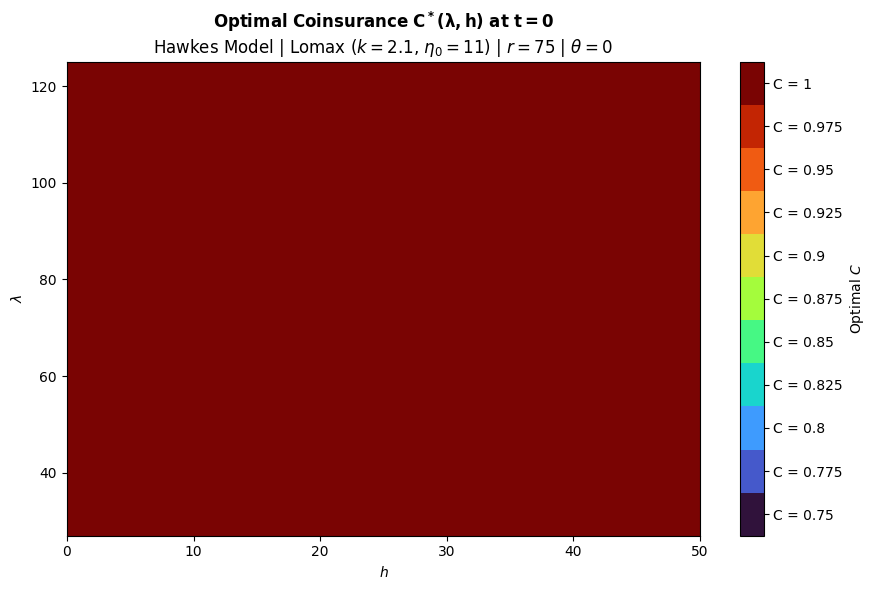

In [87]:
W_sweep_lomax = solve_W_by_C_RA(
    C_grid=C_GRID, dist_type="lomax", k=2.1, eta_0=11, d=0.1,
    omega=1, r=75,
)

_ = PL.plot_optimal_C_decision_map_RA(
        W_sweep_lomax,
        C_grid=C_GRID,
        theta=0,
        Principle="SDP",
        save_name=f"decision_map_theta_0_d01_lomax.png",
        lambda_plot_max=125
    )

Solving W for C=0.75 ...
Solving W for C=0.775 ...
Solving W for C=0.8 ...
Solving W for C=0.825 ...
Solving W for C=0.85 ...
Solving W for C=0.875 ...
Solving W for C=0.9 ...
Solving W for C=0.925 ...
Solving W for C=0.95 ...
Solving W for C=0.975 ...
Solving W for C=1 ...
Saved: thesis_plots/decision_map_theta_0_d01_lomax.png.png


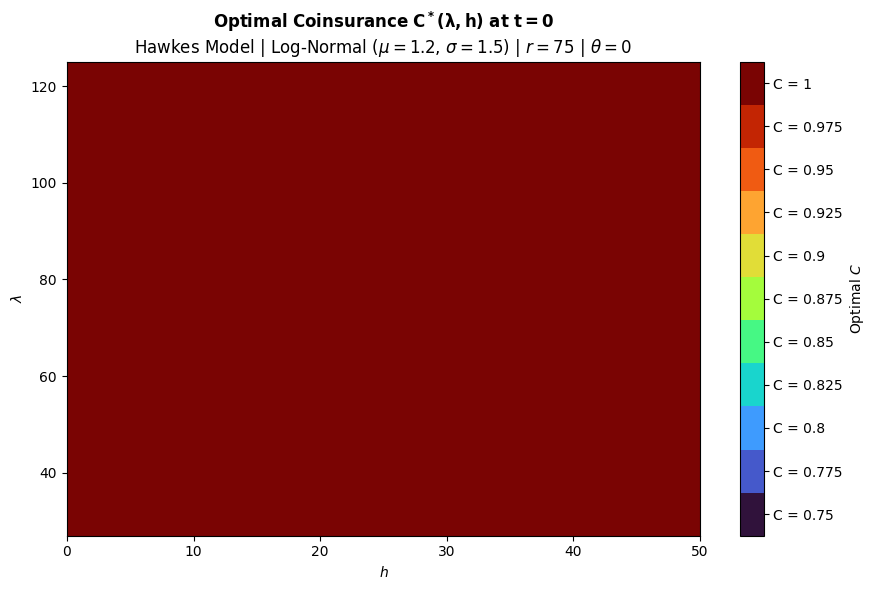

In [88]:
W_sweep_lognormal = solve_W_by_C_RA(
    C_grid=C_GRID, dist_type="lognormal", mu = 1.2, sigma = 1.5, d=0.1,
    omega=1, r=75,
)

_ = PL.plot_optimal_C_decision_map_RA(
        W_sweep_lognormal,
        C_grid=C_GRID,
        theta=0,
        Principle="SDP",
        save_name=f"decision_map_theta_0_d01_lomax.png",
        lambda_plot_max=125
    )

### **Sensitivity Analysis of the Decision Boundary**

#### **Sensitivity with respect to $d$**

**Lomax**

In [89]:
W_sweep_lomaxd0 = solve_W_by_C_RA(
    C_grid=C_GRID, dist_type="lomax", k=2.1, eta_0=11, d=0,
    omega=0.1, r=75,
)

Solving W for C=0.75 ...
Solving W for C=0.775 ...
Solving W for C=0.8 ...
Solving W for C=0.825 ...
Solving W for C=0.85 ...
Solving W for C=0.875 ...
Solving W for C=0.9 ...
Solving W for C=0.925 ...
Solving W for C=0.95 ...
Solving W for C=0.975 ...
Solving W for C=1 ...


Saved: thesis_plots/decision_map_theta_00_d0_lomax.png.png


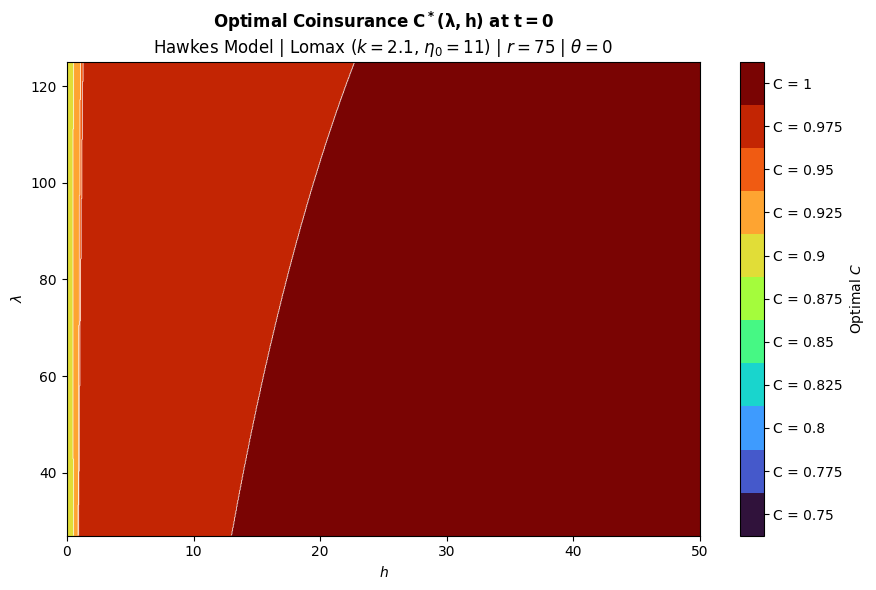

In [90]:
d_str = '0'
dist = 'lomax'

for theta in [0]:
    theta_str = f"{theta:.1f}".replace(".", "")
    _ = PL.plot_optimal_C_decision_map_RA(
        W_sweep_lomaxd0,
        C_grid=C_GRID,
        theta=theta,
        Principle="SDP",
        save_name=f"decision_map_theta_{theta_str}_d{d_str}_{dist}.png",
        lambda_plot_max=125
    )

In [91]:
W_sweep_lomaxd02 = solve_W_by_C_RA(
    C_grid=C_GRID, dist_type="lomax", k=2.1, eta_0=11, d=0.2,
    omega=0.1, r=75,
)

Solving W for C=0.75 ...
Solving W for C=0.775 ...
Solving W for C=0.8 ...
Solving W for C=0.825 ...
Solving W for C=0.85 ...
Solving W for C=0.875 ...
Solving W for C=0.9 ...
Solving W for C=0.925 ...
Solving W for C=0.95 ...
Solving W for C=0.975 ...
Solving W for C=1 ...


Saved: thesis_plots/decision_map_theta_00_d02_lomax.png.png


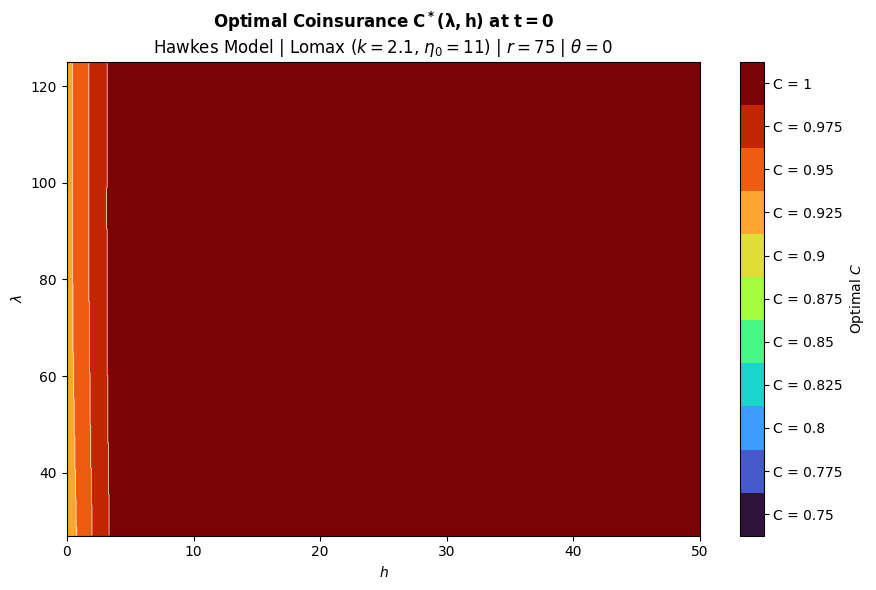

In [92]:
d_str = '02'
dist = 'lomax'

for theta in [0]:
    theta_str = f"{theta:.1f}".replace(".", "")
    _ = PL.plot_optimal_C_decision_map_RA(
        W_sweep_lomaxd02,
        C_grid=C_GRID,
        theta=theta,
        Principle="SDP",
        save_name=f"decision_map_theta_{theta_str}_d{d_str}_{dist}.png",
        lambda_plot_max=125
    )

In [93]:
W_sweep_lomaxd1 = solve_W_by_C_RA(
    C_grid=C_GRID, dist_type="lomax", k=2.1, eta_0=11, d=1,
    omega=0.1, r=75,
)

Solving W for C=0.75 ...
Solving W for C=0.775 ...
Solving W for C=0.8 ...
Solving W for C=0.825 ...
Solving W for C=0.85 ...
Solving W for C=0.875 ...
Solving W for C=0.9 ...
Solving W for C=0.925 ...
Solving W for C=0.95 ...
Solving W for C=0.975 ...
Solving W for C=1 ...


Saved: thesis_plots/decision_map_theta_00_d1_lomax.png.png


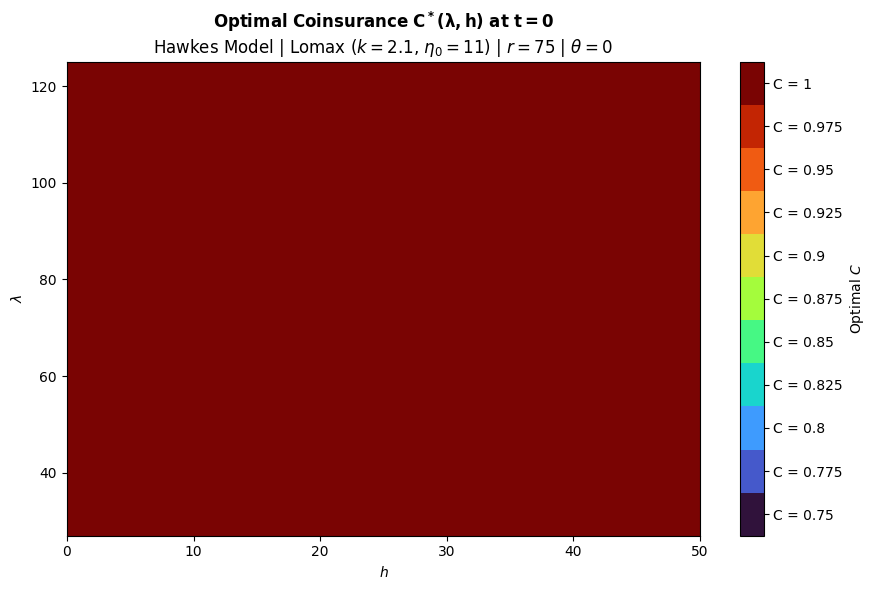

In [94]:
d_str = '1'
dist = 'lomax'

for theta in [0]:
    theta_str = f"{theta:.1f}".replace(".", "")
    _ = PL.plot_optimal_C_decision_map_RA(
        W_sweep_lomaxd1,
        C_grid=C_GRID,
        theta=theta,
        Principle="SDP",
        save_name=f"decision_map_theta_{theta_str}_d{d_str}_{dist}.png",
        lambda_plot_max=125
    )

**Lognormal**

In [95]:
W_sweep_lognormald0 = solve_W_by_C_RA(
    C_grid=C_GRID, dist_type="lognormal", mu = 1.2, sigma = 1.5, d=0.001,
    omega=0.1, r=75,
)

Solving W for C=0.75 ...
Solving W for C=0.775 ...
Solving W for C=0.8 ...
Solving W for C=0.825 ...
Solving W for C=0.85 ...
Solving W for C=0.875 ...
Solving W for C=0.9 ...
Solving W for C=0.925 ...
Solving W for C=0.95 ...
Solving W for C=0.975 ...
Solving W for C=1 ...


Saved: thesis_plots/decision_map_theta_00_d0_lognormal.png.png


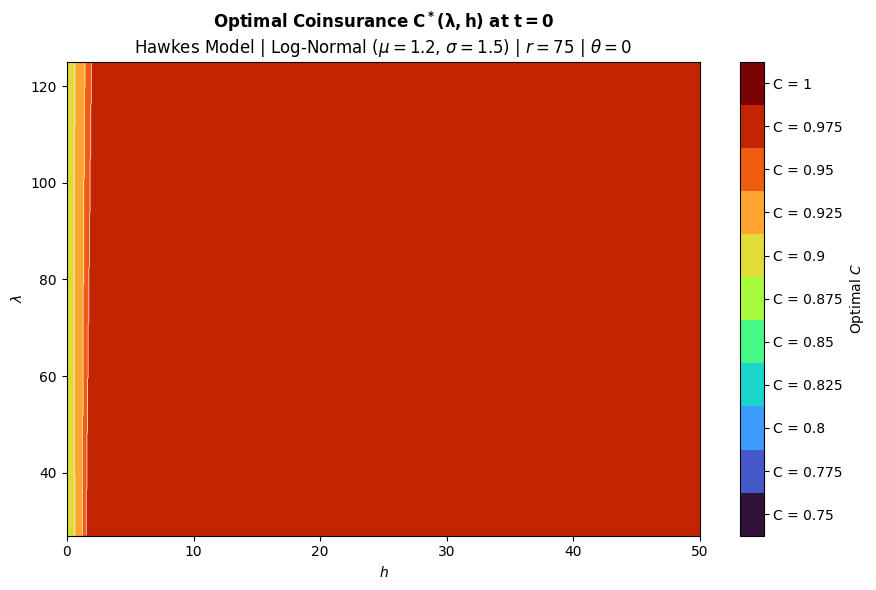

In [96]:
d_str = '0'
dist = 'lognormal'

for theta in [0]:
    theta_str = f"{theta:.1f}".replace(".", "")
    _ = PL.plot_optimal_C_decision_map_RA(
        W_sweep_lognormald0,
        C_grid=C_GRID,
        theta=theta,
        Principle="SDP",
        save_name=f"decision_map_theta_{theta_str}_d{d_str}_{dist}.png",
        lambda_plot_max=125
    )

In [97]:
W_sweep_lognormald02 = solve_W_by_C_RA(
    C_grid=C_GRID, dist_type="lognormal", mu = 1.2, sigma = 1.5, d=0.2,
    omega=0.1, r=75,
)

Solving W for C=0.75 ...
Solving W for C=0.775 ...
Solving W for C=0.8 ...
Solving W for C=0.825 ...
Solving W for C=0.85 ...
Solving W for C=0.875 ...
Solving W for C=0.9 ...
Solving W for C=0.925 ...
Solving W for C=0.95 ...
Solving W for C=0.975 ...
Solving W for C=1 ...


Saved: thesis_plots/decision_map_theta_00_d02_lognormal.png.png


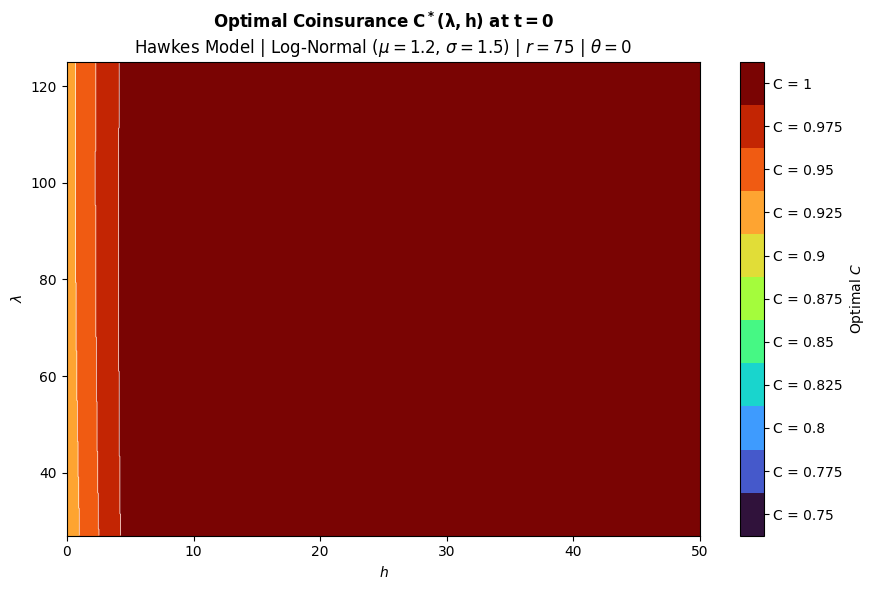

In [98]:
d_str = '02'
dist = 'lognormal'

for theta in [0]:
    theta_str = f"{theta:.1f}".replace(".", "")
    _ = PL.plot_optimal_C_decision_map_RA(
        W_sweep_lognormald02,
        C_grid=C_GRID,
        theta=theta,
        Principle="SDP",
        save_name=f"decision_map_theta_{theta_str}_d{d_str}_{dist}.png",
        lambda_plot_max=125
    )

In [99]:
W_sweep_lognormald1 = solve_W_by_C_RA(
    C_grid=C_GRID, dist_type="lognormal", mu = 1.2, sigma = 1.5, d=1,
    omega=0.1, r=75,
)

Solving W for C=0.75 ...
Solving W for C=0.775 ...
Solving W for C=0.8 ...
Solving W for C=0.825 ...
Solving W for C=0.85 ...
Solving W for C=0.875 ...
Solving W for C=0.9 ...
Solving W for C=0.925 ...
Solving W for C=0.95 ...
Solving W for C=0.975 ...
Solving W for C=1 ...


Saved: thesis_plots/decision_map_theta_00_d1_lomax.png.png


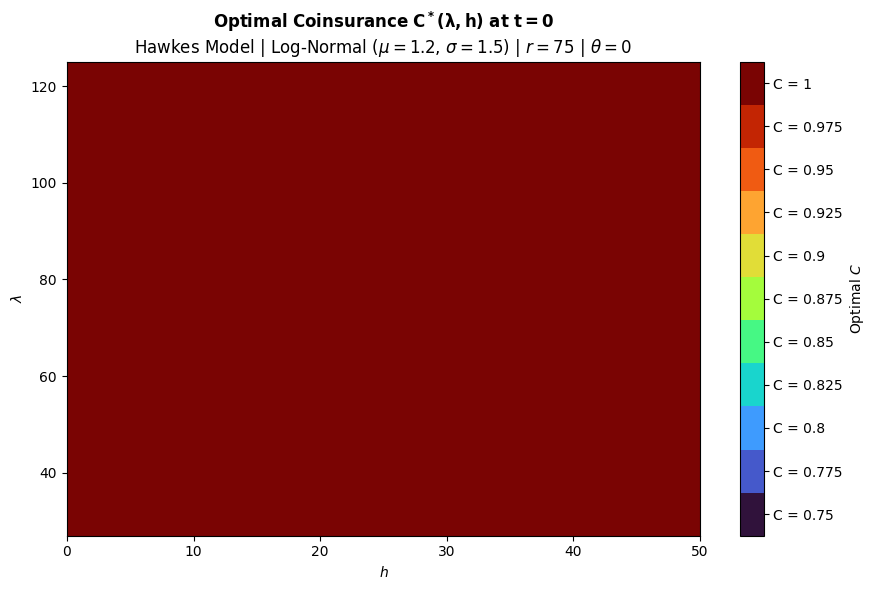

In [100]:
d_str = '1'
dist = 'lomax'

for theta in [0]:
    theta_str = f"{theta:.1f}".replace(".", "")
    _ = PL.plot_optimal_C_decision_map_RA(
        W_sweep_lognormald1,
        C_grid=C_GRID,
        theta=theta,
        Principle="SDP",
        save_name=f"decision_map_theta_{theta_str}_d{d_str}_{dist}.png",
        lambda_plot_max=125
    )

#### **Sensitivity with respect to $\theta$**

**Lomax**

In [101]:
W_sweep_lomax_theta = solve_W_by_C_RA(
    C_grid=C_GRID, dist_type="lomax", k=2.1, eta_0=11, d=0.1,
    omega=0.1, r=75,
)

Solving W for C=0.75 ...
Solving W for C=0.775 ...
Solving W for C=0.8 ...
Solving W for C=0.825 ...
Solving W for C=0.85 ...
Solving W for C=0.875 ...
Solving W for C=0.9 ...
Solving W for C=0.925 ...
Solving W for C=0.95 ...
Solving W for C=0.975 ...
Solving W for C=1 ...


Saved: thesis_plots/decision_map_theta_00_omega01_lomax.png.png


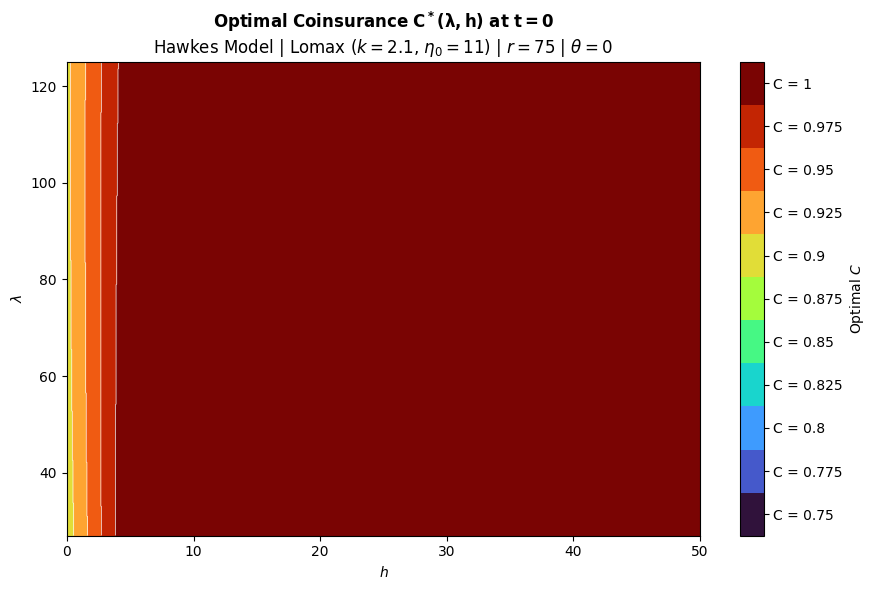

Saved: thesis_plots/decision_map_theta_01_omega01_lomax.png.png


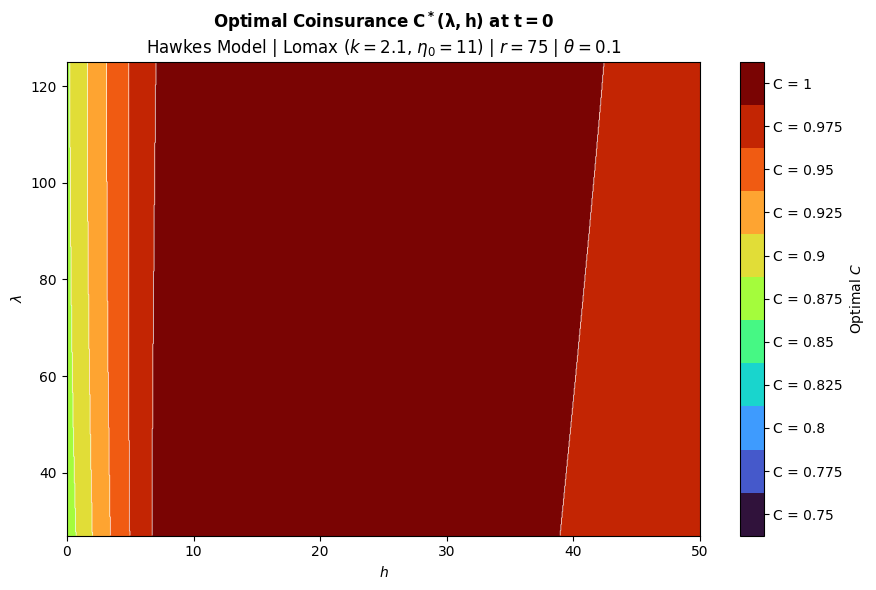

Saved: thesis_plots/decision_map_theta_03_omega01_lomax.png.png


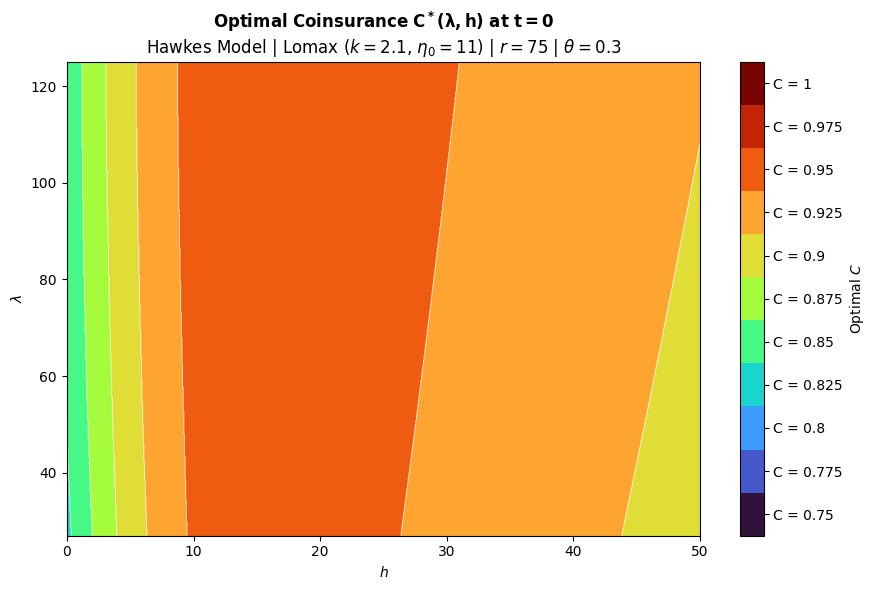

Saved: thesis_plots/decision_map_theta_05_omega01_lomax.png.png


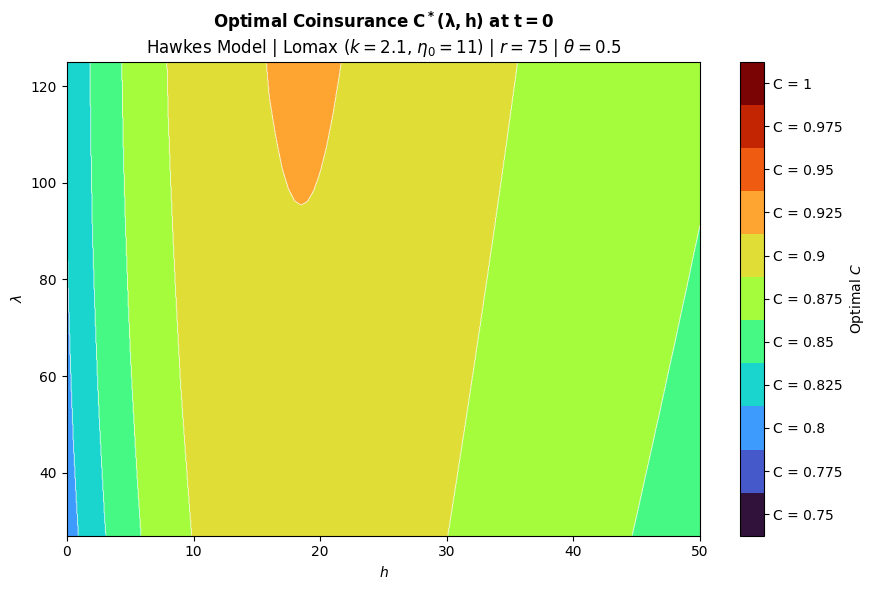

Saved: thesis_plots/decision_map_theta_07_omega01_lomax.png.png


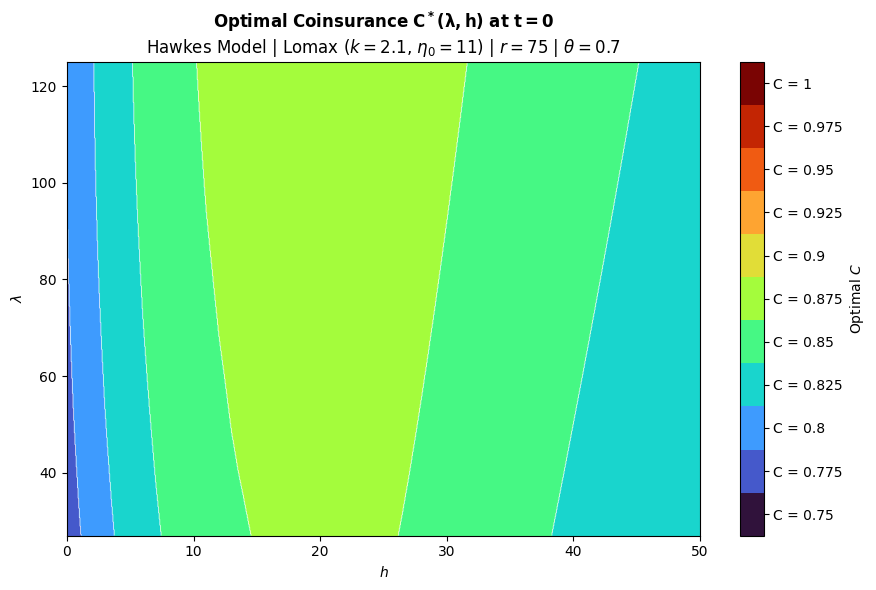

Saved: thesis_plots/decision_map_theta_09_omega01_lomax.png.png


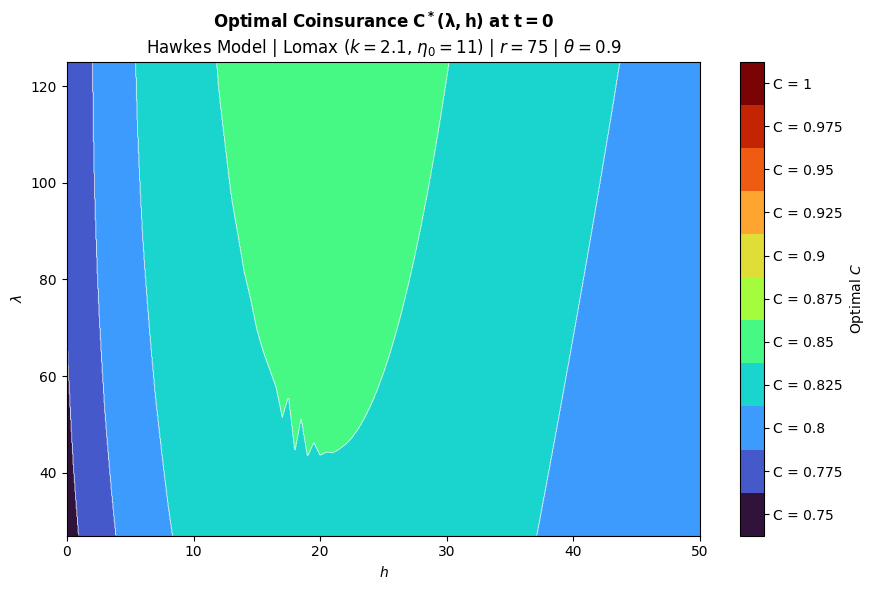

In [102]:
omega_str = '01'
dist = 'lomax'

for theta in [0, 0.1, 0.3, 0.5, 0.7, 0.9]:
    theta_str = f"{theta:.1f}".replace(".", "")
    _ = PL.plot_optimal_C_decision_map_RA(
        W_sweep_lomax_theta,
        C_grid=C_GRID,
        theta=theta,
        Principle="SDP",
        save_name=f"decision_map_theta_{theta_str}_omega{omega_str}_{dist}.png",
        lambda_plot_max=125
    )

**Lognormal**

In [103]:
W_sweep_lognormal_theta = solve_W_by_C_RA(
    C_grid=C_GRID, dist_type="lognormal", mu = 1.2, sigma = 1.5, d=0.1,
    omega=0.1, r=75,
)

Solving W for C=0.75 ...
Solving W for C=0.775 ...
Solving W for C=0.8 ...
Solving W for C=0.825 ...
Solving W for C=0.85 ...
Solving W for C=0.875 ...
Solving W for C=0.9 ...
Solving W for C=0.925 ...
Solving W for C=0.95 ...
Solving W for C=0.975 ...
Solving W for C=1 ...


Saved: thesis_plots/decision_map_theta_00_omega01_lognormal.png.png


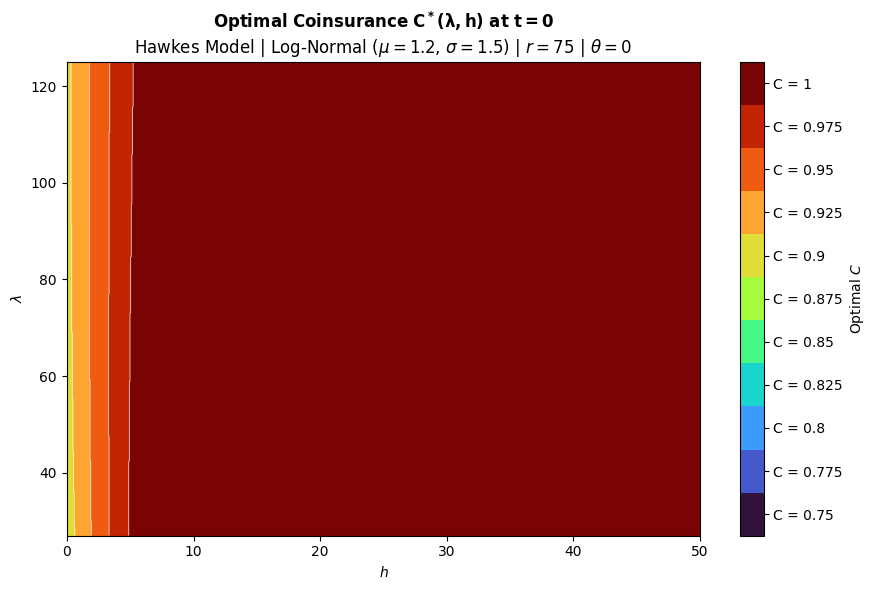

Saved: thesis_plots/decision_map_theta_01_omega01_lognormal.png.png


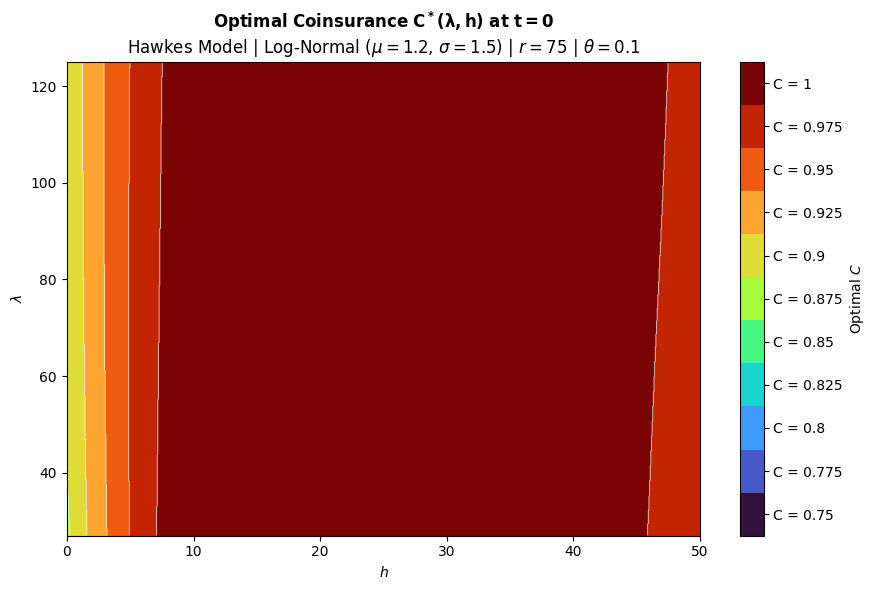

Saved: thesis_plots/decision_map_theta_03_omega01_lognormal.png.png


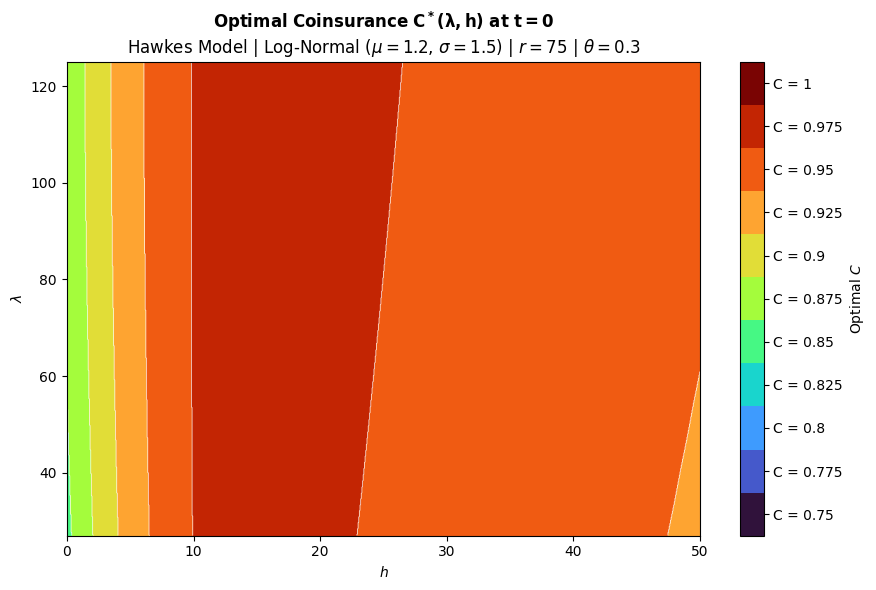

Saved: thesis_plots/decision_map_theta_05_omega01_lognormal.png.png


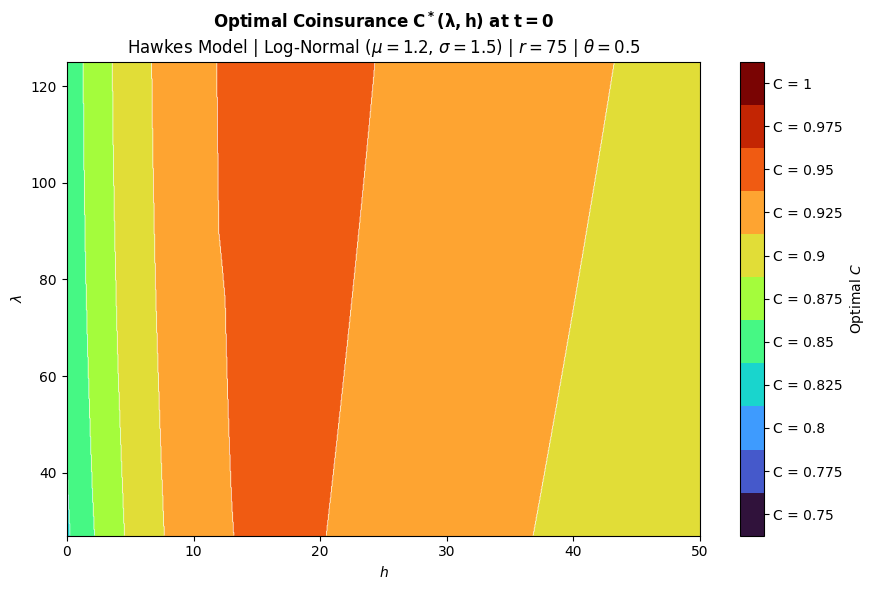

Saved: thesis_plots/decision_map_theta_07_omega01_lognormal.png.png


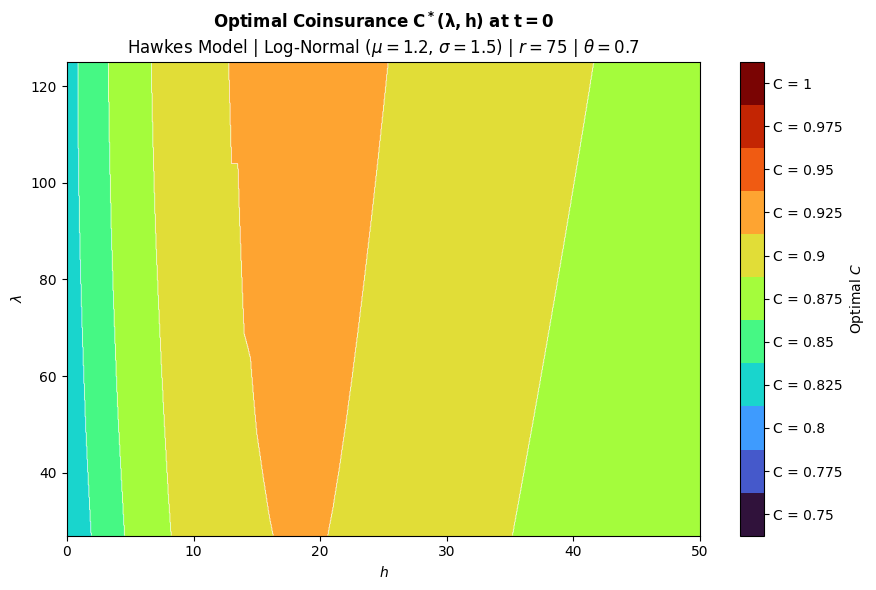

Saved: thesis_plots/decision_map_theta_09_omega01_lognormal.png.png


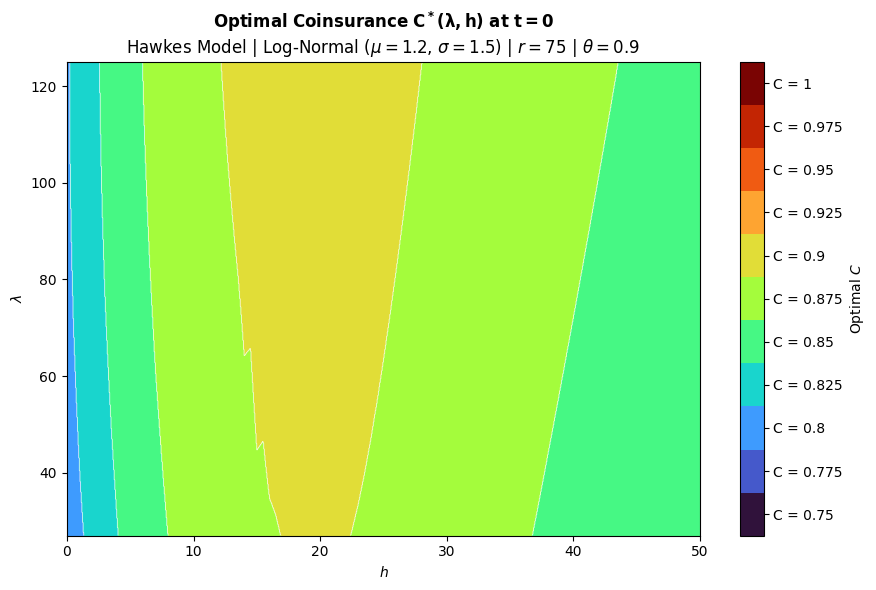

In [104]:
omega_str = '01'
dist = 'lognormal'

for theta in [0, 0.1, 0.3, 0.5, 0.7, 0.9]:
    theta_str = f"{theta:.1f}".replace(".", "")
    _ = PL.plot_optimal_C_decision_map_RA(
        W_sweep_lognormal_theta,
        C_grid=C_GRID,
        theta=theta,
        Principle="SDP",
        save_name=f"decision_map_theta_{theta_str}_omega{omega_str}_{dist}.png",
        lambda_plot_max=125
    )

### **Risk-averse in the limit of Risk-neutral**

In [105]:
C_GRID = [0,1]

In [106]:
dist = 'lomax'

W_sweep_lomax01 = solve_W_by_C_RA(
    C_grid=C_GRID, dist_type="lomax", eta_0 = 11, k = 2.1, d=0.1,
    omega=1e-5, r=160,
)

Solving W for C=0 ...
Solving W for C=1 ...


Saved: thesis_plots/decision_map01_theta_lomax2.png.png


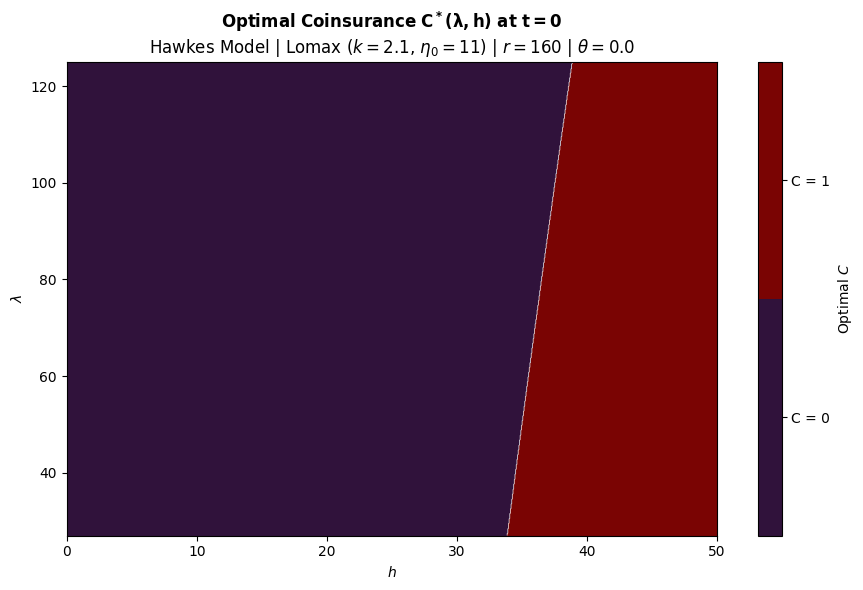

In [107]:
_ = PL.plot_optimal_C_decision_map_RA(
        W_sweep_lomax01,
        C_grid=C_GRID,
        theta=0.0,
        Principle="SDP",
        save_name=f"decision_map01_theta_{dist}2.png",
        lambda_plot_max=125
    )

In [108]:
W_sweep_lognormal01 = solve_W_by_C_RA(
    C_grid=C_GRID, dist_type="lognormal", mu = 1.2, sigma = 1.5, d=0.1,
    omega=1e-5, r=160,
)

Solving W for C=0 ...
Solving W for C=1 ...


Saved: thesis_plots/decision_map01_theta_lognormal2.png.png


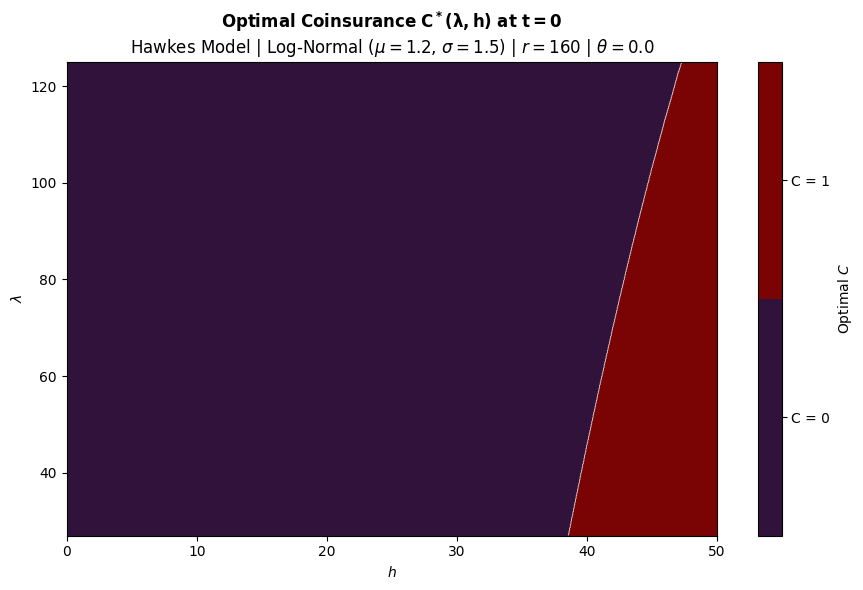

In [109]:
dist = 'lognormal'

_ = PL.plot_optimal_C_decision_map_RA(
        W_sweep_lognormal01,
        C_grid=C_GRID,
        theta=0.0,
        Principle="SDP",
        save_name=f"decision_map01_theta_{dist}2.png",
        lambda_plot_max=125
    )